# Exploratory Data Analysis & Data Cleaning
## Loan Eligibility · Adult Census Income · Hotel Booking

**Name:** ____________________  **Roll No:** ____________________

This notebook performs a complete, column-by-column **EDA (Exploratory Data Analysis)** and **data cleaning** of three datasets using **Pandas, NumPy, Matplotlib and Seaborn**, in the order required by the assignment:

| # | Dataset | File | Rows × Cols | Target column |
|---|---------|------|-------------|---------------|
| 1 | Loan Eligibility | `loan-train.csv` | 1,614 × 13 | `Loan_Status` |
| 2 | Adult Census Income | `adult.csv` | 48,842 × 15 | `income` |
| 3 | Hotel Booking | `hotel_booking.csv` | 119,390 × 36 | `is_canceled` |

**Workflow followed for every dataset**

1. Load the data and take a first look (shape, head, dtypes, `info()`, `describe()`)
2. Overall data-quality check (missing values, duplicates, hidden missing markers like `?` / `Undefined`)
3. **Column-by-column analysis** — for *every* column: profile → visualization → relationship with the target → cleaning step
4. Feature engineering and multivariate analysis (correlations, cross-tabs)
5. Final verification of the cleaned data and export to CSV
6. Key insights

> **How to run:** keep the three CSV files in the same folder as this notebook, then *Kernel → Restart & Run All*.

### Table of Contents
- **Part 0** — Setup & helper functions
- **Part 1** — Loan Eligibility dataset
- **Part 2** — Adult Census Income dataset
- **Part 3** — Hotel Booking dataset
- **Final Summary**

---
# Part 0 — Setup & Helper Functions

In [1]:
# Core libraries
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import warnings

warnings.filterwarnings("ignore")
pd.set_option("display.max_columns", None)
pd.set_option("display.width", 200)
pd.set_option("display.float_format", lambda x: f"{x:,.2f}")

# Consistent, clean plotting style
BLUE   = "#2a78d6"   # negative class / general series
ORANGE = "#eb6834"   # positive class (Approved / >50K / Canceled)
INK    = "#52514e"   # reference lines and annotations
sns.set_theme(style="whitegrid", rc={
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.edgecolor": "#b5b4ae", "grid.color": "#e6e6e3",
    "axes.titleweight": "bold", "axes.titlesize": 11,
    "axes.labelsize": 10, "figure.dpi": 100,
})

print("pandas ", pd.__version__)
print("numpy  ", np.__version__)
print("seaborn", sns.__version__)

pandas  3.0.3
numpy   2.4.6
seaborn 0.13.2


### Reusable helper functions
To analyse **every column** in a consistent way, the following helpers are used throughout the notebook:

| Helper | What it does |
|--------|--------------|
| `overview(df)` | One-table summary of every column: dtype, missing count/%, unique values, sample values |
| `profile(df, col)` | Detailed statistics for one column (numeric: describe, skewness, kurtosis, IQR outliers · categorical: frequency table) |
| `plot_numeric(df, col, target)` | Histogram + KDE, boxplot, and boxplot split by the target |
| `plot_categorical(df, col, target, pos)` | Frequency bar chart + target rate per category |
| `iqr_bounds(s)` | Lower / upper outlier fences using the 1.5 × IQR rule |

In [2]:
def is_num(s):
    """True if a Series is numeric (works on pandas 1.x, 2.x and 3.x)."""
    return pd.api.types.is_numeric_dtype(s)


def overview(df):
    """Summary table of every column in a DataFrame."""
    out = pd.DataFrame({
        "dtype": df.dtypes.astype(str),
        "non_null": df.notna().sum(),
        "missing": df.isna().sum(),
        "missing_%": (df.isna().mean() * 100).round(2),
        "unique": df.nunique(),
        "sample_values": [list(df[c].dropna().unique()[:4]) for c in df.columns],
    })
    return out


def iqr_bounds(s, k=1.5):
    q1, q3 = s.quantile([0.25, 0.75])
    iqr = q3 - q1
    return q1 - k * iqr, q3 + k * iqr


def profile(df, col, top=15):
    """Print a detailed profile of one column."""
    s = df[col]
    print(f"Column : {col}")
    print(f"dtype  : {s.dtype}")
    print(f"Missing: {s.isna().sum():,} ({s.isna().mean()*100:.2f}%)")
    print(f"Unique : {s.nunique():,}")
    if is_num(s) and s.nunique() > 2:
        d = s.describe()
        lo, hi = iqr_bounds(s.dropna())
        n_out = ((s < lo) | (s > hi)).sum()
        print("-" * 40)
        print(d.to_string())
        print(f"skewness : {s.skew():.3f}")
        print(f"kurtosis : {s.kurt():.3f}")
        print(f"zeros    : {(s == 0).sum():,} ({(s == 0).mean()*100:.2f}%)")
        print(f"IQR fences: [{lo:,.2f}, {hi:,.2f}] -> outliers: {n_out:,} ({n_out/len(s)*100:.2f}%)")
    else:
        vc = s.value_counts(dropna=False)
        tbl = pd.DataFrame({"count": vc, "percent": (vc / len(s) * 100).round(2)})
        print("-" * 40)
        print(tbl.head(top).to_string())
        if len(tbl) > top:
            print(f"... {len(tbl) - top} more categories")


def plot_numeric(df, col, target=None, order=None, bins=40, logy=False, clip_q=None):
    """Histogram+KDE, boxplot, and (optionally) boxplot by target."""
    data = df[col].dropna()
    if clip_q is not None:                       # zoom the view only (data unchanged)
        data = data[data <= data.quantile(clip_q)]
    n = 3 if target else 2
    fig, axes = plt.subplots(1, n, figsize=(5.4 * n, 3.8))
    sns.histplot(data, bins=bins, kde=True, color=BLUE, edgecolor="white", linewidth=0.4, ax=axes[0])
    axes[0].axvline(data.mean(), color=INK, ls="--", lw=1.2, label=f"mean = {data.mean():,.1f}")
    axes[0].axvline(data.median(), color=ORANGE, ls=":", lw=1.8, label=f"median = {data.median():,.1f}")
    axes[0].legend(fontsize=8, frameon=False)
    axes[0].set_title("Distribution" + (" (log y-axis)" if logy else ""))
    if logy:
        axes[0].set_yscale("log")
    sns.boxplot(x=data, color=BLUE, width=0.45, fliersize=2, ax=axes[1],
                boxprops=dict(alpha=0.75))
    axes[1].set_title("Boxplot (dots = IQR outliers)")
    if target:
        sub = df[[col, target]].dropna()
        if clip_q is not None:
            sub = sub[sub[col] <= df[col].quantile(clip_q)]
        sns.boxplot(data=sub, x=target, y=col, order=order, palette=[BLUE, ORANGE],
                    width=0.5, fliersize=1.5, ax=axes[2])
        axes[2].set_title(f"{col} by {target}")
    title = col + (f"  (view clipped at {int(clip_q*100)}th percentile)" if clip_q else "")
    fig.suptitle(title, fontsize=13, fontweight="bold")
    plt.tight_layout()
    plt.show()


def plot_categorical(df, col, target=None, pos=None, top=None, sort_index=False, label=None):
    """Frequency bar chart + % of positive target class per category."""
    s = df[col].copy()
    cat_order = ([str(c) for c in s.cat.categories]
                 if isinstance(s.dtype, pd.CategoricalDtype) else None)
    s = s.astype("object").where(s.notna(), "Missing").astype(str)
    vc = s.value_counts()
    if cat_order:                                # keep the natural order of ordered bins
        vc = vc.reindex([c for c in cat_order if c in vc.index] +
                        [c for c in vc.index if c not in cat_order])
    if sort_index:
        try:
            vc = vc.loc[sorted(vc.index, key=lambda v: float(v))]
        except ValueError:
            vc = vc.sort_index()
    if top:
        vc = vc.head(top)
    cats = list(vc.index)
    n = 2 if target else 1
    h = max(3.2, 0.32 * len(cats) + 1.2)
    fig, axes = plt.subplots(1, n, figsize=(6.2 * n, h))
    axes = np.atleast_1d(axes)

    ax = axes[0]
    ax.barh(cats[::-1], vc.values[::-1], color=BLUE, height=0.7)
    total = len(s)
    for i, v in enumerate(vc.values[::-1]):
        ax.text(v, i, f" {v:,} ({v/total*100:.1f}%)", va="center", fontsize=8, color=INK)
    ax.set_xlim(0, vc.max() * 1.35)
    ax.set_title("Frequency" + (f" (top {top})" if top else ""))
    ax.set_xlabel("count")

    if target:
        y = (df[target] == pos).astype(int)
        rate = (y.groupby(s).mean() * 100).reindex(cats)
        overall = y.mean() * 100
        ax2 = axes[1]
        ax2.barh(cats[::-1], rate.values[::-1], color=ORANGE, height=0.7)
        ax2.axvline(overall, color=INK, ls="--", lw=1.2)
        for i, v in enumerate(rate.values[::-1]):
            ax2.text(v, i, f" {v:.1f}%", va="center", fontsize=8, color=INK)
        ax2.set_xlim(0, min(110, rate.max() * 1.25 + 5))
        ax2.set_title(f"% {label or pos} by {col}  (dashed line = overall {overall:.1f}%)")
        ax2.set_xlabel("%")
    fig.suptitle(col, fontsize=13, fontweight="bold")
    plt.tight_layout()
    plt.show()


print("Helper functions ready.")

Helper functions ready.


---
# Part 1 — Loan Eligibility Dataset

**Goal:** understand which applicant characteristics are associated with loan approval (`Loan_Status` = `Y`/`N`), and produce a clean, analysis-ready version of the data.

## 1.1 Load the data & first look

In [3]:
loan_raw = pd.read_csv("loan-train.csv")
loan = loan_raw.copy()          # all cleaning happens on this working copy
print("Shape:", loan.shape)
loan.head()

FileNotFoundError: [Errno 2] No such file or directory: 'loan-train.csv'

In [ ]:
loan.info()

In [ ]:
loan.describe(include="all").T

## 1.2 Overall data-quality check

In [ ]:
overview(loan)

In [ ]:
missing = loan.isna().sum()
missing = missing[missing > 0].sort_values()
fig, ax = plt.subplots(figsize=(7, 3.2))
ax.barh(missing.index, missing.values, color=BLUE, height=0.65)
for i, v in enumerate(missing.values):
    ax.text(v, i, f" {v} ({v/len(loan)*100:.1f}%)", va="center", fontsize=8, color=INK)
ax.set_xlim(0, missing.max() * 1.3)
ax.set_title("Loan dataset — missing values per column")
plt.tight_layout(); plt.show()

print("Fully duplicated rows:", loan.duplicated().sum())
print("Duplicated Loan_ID values:", loan["Loan_ID"].duplicated().sum())

In [ ]:
# Where are the missing values? (yellow = missing)
plt.figure(figsize=(10, 3.5))
sns.heatmap(loan.isna().T, cbar=False, cmap=["#f2f1ee", "#eda100"], yticklabels=True)
plt.title("Missing-value map (rows → columns)")
plt.xlabel("row index"); plt.xticks([])
plt.tight_layout(); plt.show()

**Observations**
- 7 of 13 columns have missing values; the largest gap is `Credit_History` (50 rows, ≈3.1%). All gaps are small (<5%), so **imputation** is preferred over dropping rows.
- There are **no fully duplicated rows**, but `Loan_ID` is not unique — this is investigated in its own column section below.
- Missing values are scattered randomly across rows (no block pattern in the map).

## 1.3 Target variable — `Loan_Status`
The target is analysed first because every other column is compared against it.

In [ ]:
profile(loan, "Loan_Status")
plot_categorical(loan, "Loan_Status")

**Observations — `Loan_Status`**
- `Y` (approved) = 915 (56.7%), `N` (rejected) = 699 (43.3%). The classes are **only mildly imbalanced**, so no resampling is needed for EDA.
- No missing values; only two valid labels.

**Cleaning:** add a numeric version (`Y` → 1, `N` → 0) so it can be used in correlations.

In [ ]:
loan["Loan_Status_num"] = loan["Loan_Status"].map({"Y": 1, "N": 0})
loan["Loan_Status_num"].value_counts()

## 1.4 Column-by-column analysis & cleaning

### Column 1 — `Loan_ID`

In [ ]:
profile(loan, "Loan_ID", top=5)

id_counts = loan["Loan_ID"].value_counts().value_counts().sort_index()
fig, ax = plt.subplots(figsize=(6, 3))
ax.bar(id_counts.index.astype(str), id_counts.values, color=BLUE, width=0.55)
for i, v in enumerate(id_counts.values):
    ax.text(i, v, f"{v:,}", ha="center", va="bottom", fontsize=9, color=INK)
ax.set_xlabel("times a Loan_ID appears"); ax.set_ylabel("number of IDs")
ax.set_title("Loan_ID — how often is each ID repeated?")
plt.tight_layout(); plt.show()

In [ ]:
# Do repeated IDs carry the same information? (i.e. are they real duplicates?)
dup_ids = loan[loan["Loan_ID"].duplicated(keep=False)].sort_values("Loan_ID")
print("Rows sharing an ID:", len(dup_ids))
dup_ids.head(6)

**Observations — `Loan_ID`**
- 1,538 unique IDs for 1,614 rows: 76 IDs are reused (151 rows).
- Rows with the same ID have **different gender, income, loan amount and status**, so they are *different applicants* that received a colliding ID — **not duplicate records**. Deleting them would throw away valid data.
- An ID is just a label; it has no analytical or predictive value.

**Cleaning:** keep all rows, drop the `Loan_ID` column.

In [ ]:
loan = loan.drop(columns="Loan_ID")
print("Loan_ID dropped. Shape:", loan.shape)

### Column 2 — `Gender`

In [ ]:
profile(loan, "Gender")
plot_categorical(loan, "Gender", target="Loan_Status", pos="Y", label="approved")

**Observations — `Gender`**
- Male 980 (60.7%), Female 621 (38.5%), missing 13 (0.8%).
- Approval rate: Male 58.5% vs Female 53.8% — a small difference.

**Cleaning:** fill the 13 missing values with the **mode** (`Male`) — the standard choice for a categorical column with very few gaps.

In [ ]:
loan["Gender"] = loan["Gender"].fillna(loan["Gender"].mode()[0])
print("Missing after cleaning:", loan["Gender"].isna().sum())
loan["Gender"].value_counts()

### Column 3 — `Married`

In [ ]:
profile(loan, "Married")
plot_categorical(loan, "Married", target="Loan_Status", pos="Y", label="approved")

**Observations — `Married`**
- Married applicants: 925 (57.3%), unmarried: 686 (42.5%), missing: 3.
- Married applicants are approved slightly more often (59.5% vs 52.8%), possibly due to combined household income.

**Cleaning:** fill 3 missing values with the mode (`Yes`).

In [ ]:
loan["Married"] = loan["Married"].fillna(loan["Married"].mode()[0])
print("Missing after cleaning:", loan["Married"].isna().sum())

### Column 4 — `Dependents`

In [ ]:
profile(loan, "Dependents")
plot_categorical(loan, "Dependents", target="Loan_Status", pos="Y", label="approved", sort_index=False)

**Observations — `Dependents`**
- Stored as **text** because of the value `"3+"`. Distribution: `0` = 619, `1` = 341, `2` = 336, `3+` = 303, missing = 15.
- Applicants with 0 dependents have the highest approval rate (59.9%).

**Cleaning:**
1. Replace `"3+"` with `"3"` (3 means "3 or more").
2. Fill 15 missing values with the mode (`0`).
3. Convert the column to integer.

In [ ]:
loan["Dependents"] = loan["Dependents"].replace("3+", "3")
loan["Dependents"] = loan["Dependents"].fillna(loan["Dependents"].mode()[0]).astype(int)
print("dtype:", loan["Dependents"].dtype, "| missing:", loan["Dependents"].isna().sum())
loan["Dependents"].value_counts().sort_index()

### Column 5 — `Education`

In [ ]:
profile(loan, "Education")
plot_categorical(loan, "Education", target="Loan_Status", pos="Y", label="approved")

**Observations — `Education`**
- Graduate 952 (59.0%), Not Graduate 662 (41.0%); no missing values.
- Graduates are approved slightly more often (59.0% vs 53.3%).

**Cleaning:** no missing or inconsistent values. Only whitespace is stripped as a safety check.

In [ ]:
loan["Education"] = loan["Education"].str.strip()
loan["Education"].unique()

### Column 6 — `Self_Employed`

In [6]:
profile(loan, "Self_Employed")
plot_categorical('loan', "Self_Employed", target="Loan_Status", pos="Y", label="approved")

NameError: name 'loan' is not defined

**Observations — `Self_Employed`**
- No = 999 (61.9%), Yes = 583 (36.1%), missing = 32 (2.0%) — the second-largest gap in the dataset.
- Salaried applicants are approved more often (59.0%) than self-employed ones (52.0%), consistent with lenders preferring stable income.

**Cleaning:** fill missing values with the mode (`No`).

In [23]:
loan["Self_Employed"] = loan["Self_Employed"].fillna(loan["Self_Employed"].mode()[0])
print("Missing after cleaning:", loan["Self_Employed"].isna().sum())

Missing after cleaning: 0


### Column 7 — `ApplicantIncome`

Column : ApplicantIncome
dtype  : int64
Missing: 0 (0.00%)
Unique : 1,455
----------------------------------------
count    1,614.00
mean     8,746.30
std      6,249.89
min        150.00
25%      3,675.25
50%      7,045.00
75%     13,251.00
max     81,000.00
skewness : 2.164
kurtosis : 15.531
zeros    : 0 (0.00%)
IQR fences: [-10,688.38, 27,614.62] -> outliers: 7 (0.43%)


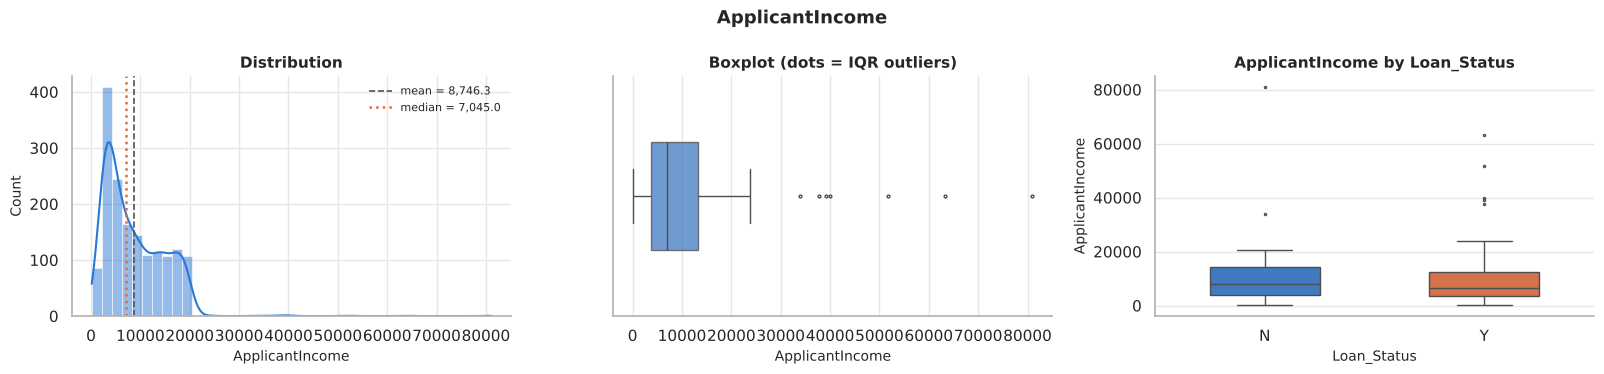

In [24]:
profile(loan, "ApplicantIncome")
plot_numeric(loan, "ApplicantIncome", target="Loan_Status", order=["N", "Y"])

**Observations — `ApplicantIncome`**
- Range 150 – 81,000; median ≈ 7,045 and mean ≈ 8,746 → **right-skewed** (skewness ≈ 2.2).
- 7 values lie above the upper IQR fence — a few very high earners stretch the scale.
- Approved and rejected applicants have overlapping income distributions, so applicant income alone does not decide approval.

**Cleaning:**
- No missing values.
- Outliers are **capped (winsorised) at the upper IQR fence** rather than deleted — the applicants are real, but extreme values would distort averages and models.
- A **log-transformed** copy is added to reduce skewness.

In [25]:
lo, hi = iqr_bounds(loan["ApplicantIncome"])
print(f"Upper fence = {hi:,.0f} | values capped: {(loan['ApplicantIncome'] > hi).sum()}")
loan["ApplicantIncome"] = loan["ApplicantIncome"].clip(upper=hi)
loan["ApplicantIncome_log"] = np.log1p(loan["ApplicantIncome"])
print(f"Skewness after capping: {loan['ApplicantIncome'].skew():.2f} | after log: {loan['ApplicantIncome_log'].skew():.2f}")

Upper fence = 27,615 | values capped: 7
Skewness after capping: 0.66 | after log: -0.33


### Column 8 — `CoapplicantIncome`

Column : CoapplicantIncome
dtype  : float64
Missing: 0 (0.00%)
Unique : 1,206
----------------------------------------
count    1,614.00
mean     3,658.72
std      3,291.75
min          0.00
25%        986.25
50%      2,941.50
75%      5,893.00
max     41,667.00
skewness : 1.913
kurtosis : 14.607
zeros    : 273 (16.91%)
IQR fences: [-6,373.88, 13,253.12] -> outliers: 4 (0.25%)


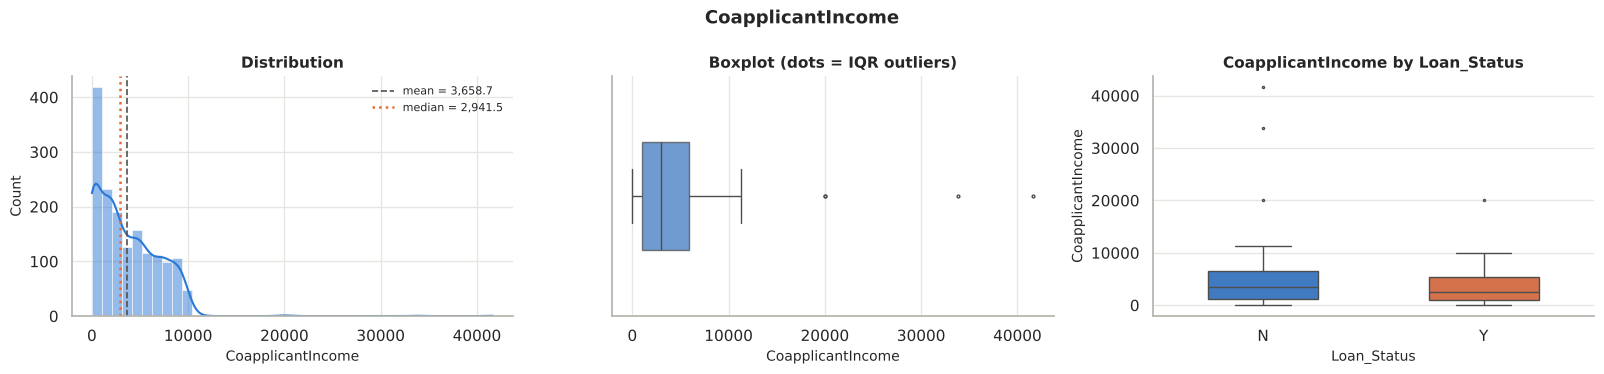

In [26]:
profile(loan, "CoapplicantIncome")
plot_numeric(loan, "CoapplicantIncome", target="Loan_Status", order=["N", "Y"])

**Observations — `CoapplicantIncome`**
- Range 0 – 41,667; median ≈ 2,942; right-skewed (skewness ≈ 1.9).
- The output above shows how many applicants have **no co-applicant income (0)** — that is a valid value, not missing data.
- 4 values are above the upper IQR fence.

**Cleaning:** cap the 4 extreme values at the upper fence (same approach as `ApplicantIncome`).

In [27]:
lo, hi = iqr_bounds(loan["CoapplicantIncome"])
print(f"Upper fence = {hi:,.0f} | values capped: {(loan['CoapplicantIncome'] > hi).sum()}")
loan["CoapplicantIncome"] = loan["CoapplicantIncome"].clip(upper=hi)

Upper fence = 13,253 | values capped: 4


### Column 9 — `LoanAmount`
*(amount in thousands)*

Column : LoanAmount
dtype  : float64
Missing: 22 (1.36%)
Unique : 461
----------------------------------------
count   1,592.00
mean      218.85
std       133.62
min         9.00
25%       112.00
50%       180.00
75%       324.00
max       700.00
skewness : 0.605
kurtosis : -0.741
zeros    : 0 (0.00%)
IQR fences: [-206.00, 642.00] -> outliers: 2 (0.12%)


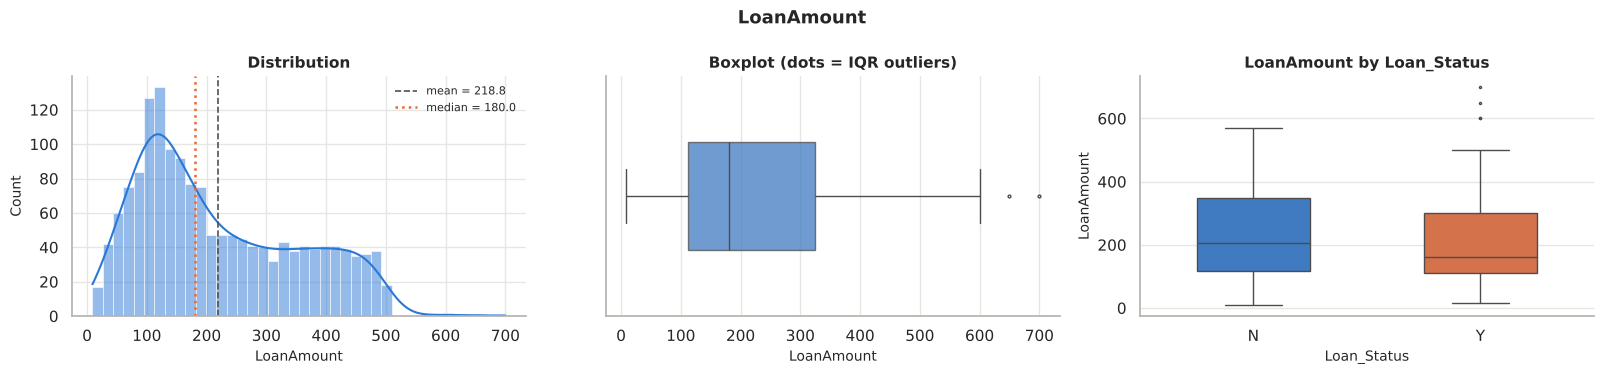

In [28]:
profile(loan, "LoanAmount")
plot_numeric(loan, "LoanAmount", target="Loan_Status", order=["N", "Y"])

**Observations — `LoanAmount`**
- Range 9 – 700; median 180, mean ≈ 219 → moderately right-skewed (skewness ≈ 0.6).
- 22 missing values (1.4%); only 2 IQR outliers.
- Rejected applications have a higher median loan amount (≈205) than approved ones (≈162) — **larger loans are rejected more often**.

**Cleaning:** fill missing values with the **median** (robust to skew). The 2 outliers are plausible amounts and are kept.

In [29]:
loan["LoanAmount"] = loan["LoanAmount"].fillna(loan["LoanAmount"].median())
print("Missing after cleaning:", loan["LoanAmount"].isna().sum())

Missing after cleaning: 0


### Column 10 — `Loan_Amount_Term`
*(term in months — only a few distinct values, so it is analysed like a category)*

Column : Loan_Amount_Term
dtype  : float64
Missing: 14 (0.87%)
Unique : 10
----------------------------------------
count   1,600.00
mean      290.48
std        81.90
min        12.00
25%       240.00
50%       360.00
75%       360.00
max       480.00
skewness : -0.346
kurtosis : -1.216
zeros    : 0 (0.00%)
IQR fences: [60.00, 540.00] -> outliers: 3 (0.19%)


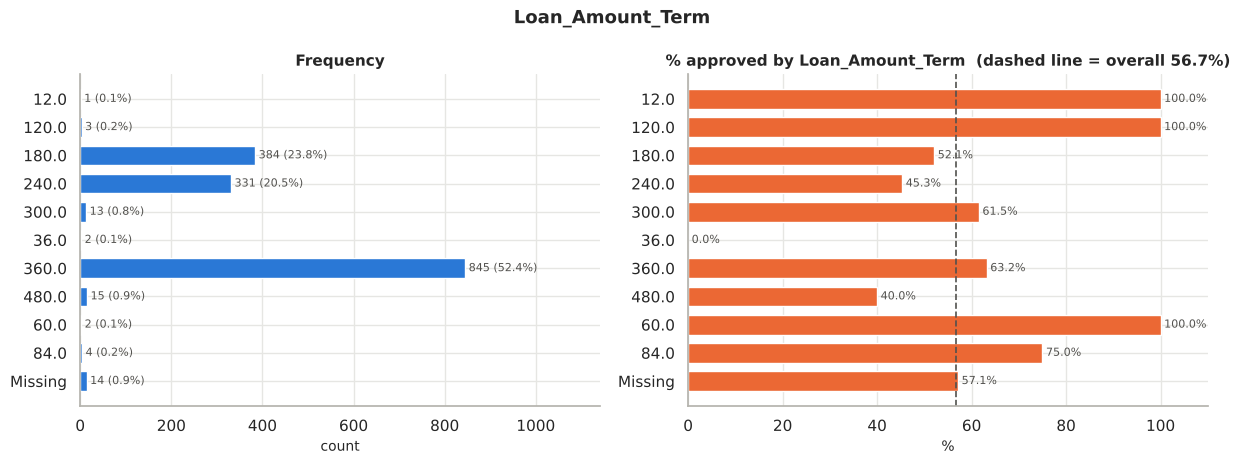

In [30]:
profile(loan, "Loan_Amount_Term")
plot_categorical(loan, "Loan_Amount_Term", target="Loan_Status", pos="Y", label="approved", sort_index=True)

**Observations — `Loan_Amount_Term`**
- Only 10 distinct terms (12 – 480 months). **360 months (30 years)** dominates with 845 loans (52%), followed by 180 and 240.
- 360-month loans have the highest approval rate among the common terms (63.2%), while 240 months is lowest (45.3%). Rare terms (12, 36, 60, 120) have too few rows to draw conclusions.
- 14 missing values.

**Cleaning:** fill missing values with the mode (360) and add a `Loan_Term_Years` helper column.

In [31]:
loan["Loan_Amount_Term"] = loan["Loan_Amount_Term"].fillna(loan["Loan_Amount_Term"].mode()[0]).astype(int)
loan["Loan_Term_Years"] = loan["Loan_Amount_Term"] / 12
print("Missing after cleaning:", loan["Loan_Amount_Term"].isna().sum())

Missing after cleaning: 0


### Column 11 — `Credit_History`
*(1 = credit history meets guidelines, 0 = does not)*

Column : Credit_History
dtype  : float64
Missing: 50 (3.10%)
Unique : 2
----------------------------------------
                count  percent
Credit_History                
1.00              994    61.59
0.00              570    35.32
NaN                50     3.10


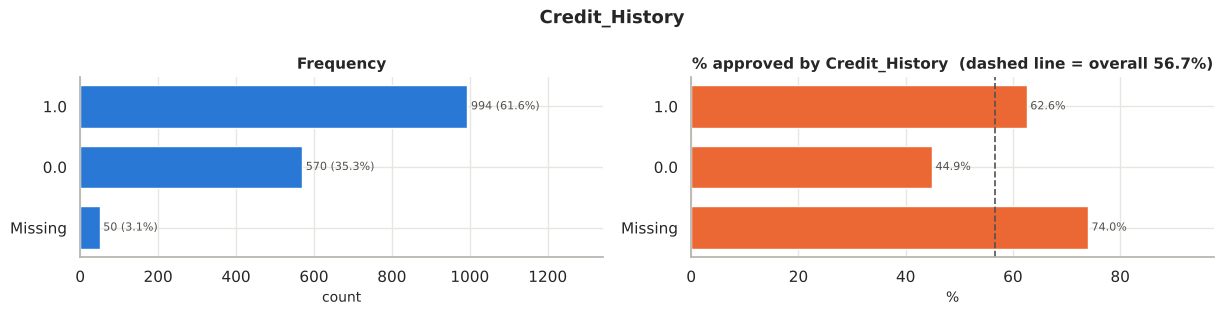

In [32]:
profile(loan, "Credit_History")
plot_categorical(loan, "Credit_History", target="Loan_Status", pos="Y", label="approved")

**Observations — `Credit_History`**
- 1.0 = 994 (61.6%), 0.0 = 570 (35.3%), missing = 50 (3.1%) — the **largest gap** in this dataset.
- Applicants with a good credit history are approved far more often (62.6% vs 44.9%) — this is the **strongest single signal** in the Loan data.

**Cleaning:** fill missing values with the mode (1) and convert to integer. (In a modelling project you might also add a "history unknown" flag.)

In [33]:
loan["Credit_History"] = loan["Credit_History"].fillna(loan["Credit_History"].mode()[0]).astype(int)
print("Missing after cleaning:", loan["Credit_History"].isna().sum())
loan["Credit_History"].value_counts()

Missing after cleaning: 0


Credit_History
1    1044
0     570
Name: count, dtype: int64

### Column 12 — `Property_Area`

Column : Property_Area
dtype  : str
Missing: 0 (0.00%)
Unique : 3
----------------------------------------
               count  percent
Property_Area                
Urban            549    34.01
Semiurban        545    33.77
Rural            520    32.22


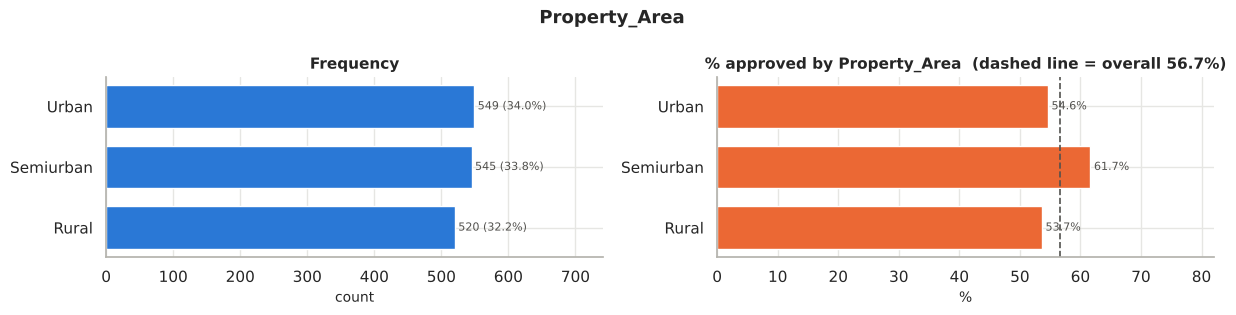

In [34]:
profile(loan, "Property_Area")
plot_categorical(loan, "Property_Area", target="Loan_Status", pos="Y", label="approved")

**Observations — `Property_Area`**
- Three balanced groups: Urban 549, Semiurban 545, Rural 520; no missing values.
- **Semiurban** properties have the highest approval rate (61.7%), Urban (54.6%) and Rural (53.7%) are similar.

**Cleaning:** none needed (strip whitespace as a check).

In [35]:
loan["Property_Area"] = loan["Property_Area"].str.strip()
loan["Property_Area"].unique()

<StringArray>
['Urban', 'Rural', 'Semiurban']
Length: 3, dtype: str

### Column 13 — `Loan_Status`
Already analysed in section 1.3 (target). Cleaning done: added `Loan_Status_num` (1/0).

## 1.5 Feature engineering
New columns that make the data more informative:
- `TotalIncome` = ApplicantIncome + CoapplicantIncome (household repayment capacity)
- `EMI` = LoanAmount / Loan_Amount_Term (approximate monthly instalment, in thousands)
- `Income_to_Loan` = TotalIncome / (LoanAmount × 1000)

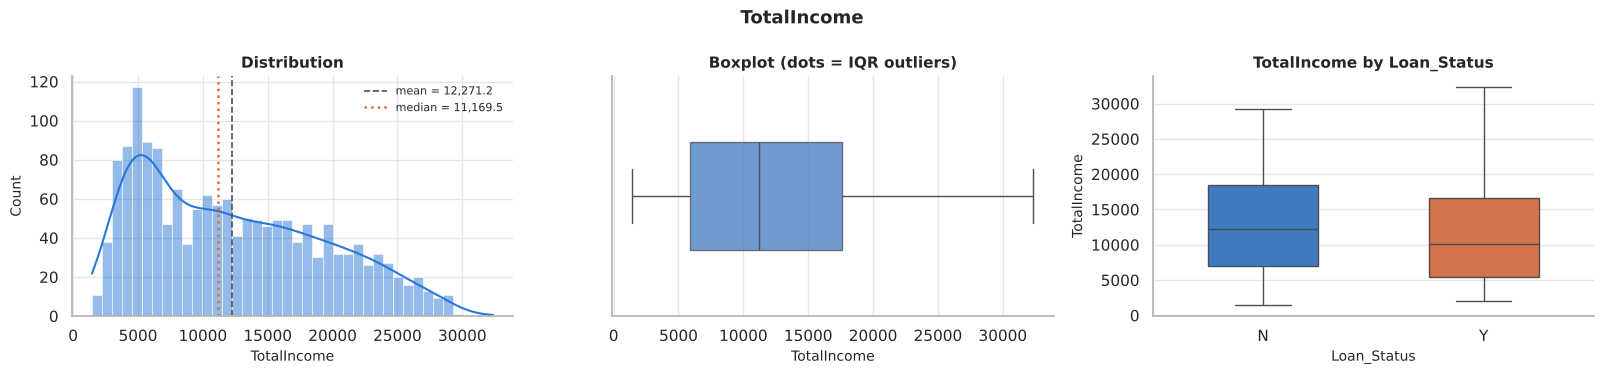

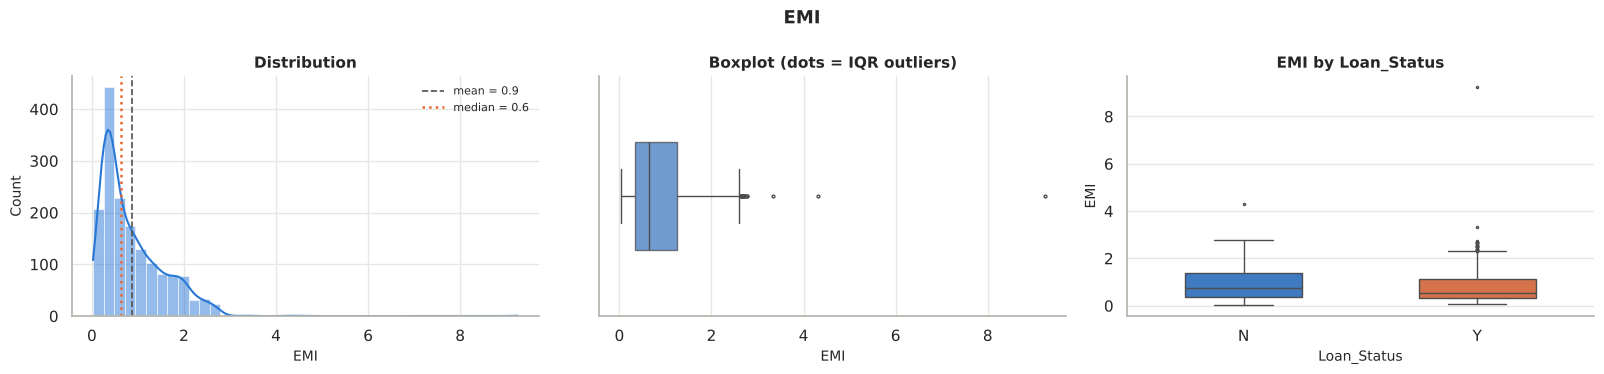

In [36]:
loan["TotalIncome"] = loan["ApplicantIncome"] + loan["CoapplicantIncome"]
loan["TotalIncome_log"] = np.log1p(loan["TotalIncome"])
loan["EMI"] = loan["LoanAmount"] / loan["Loan_Amount_Term"]
loan["Income_to_Loan"] = loan["TotalIncome"] / (loan["LoanAmount"] * 1000)

for c in ["TotalIncome", "EMI"]:
    plot_numeric(loan, c, target="Loan_Status", order=["N", "Y"])

## 1.6 Multivariate analysis

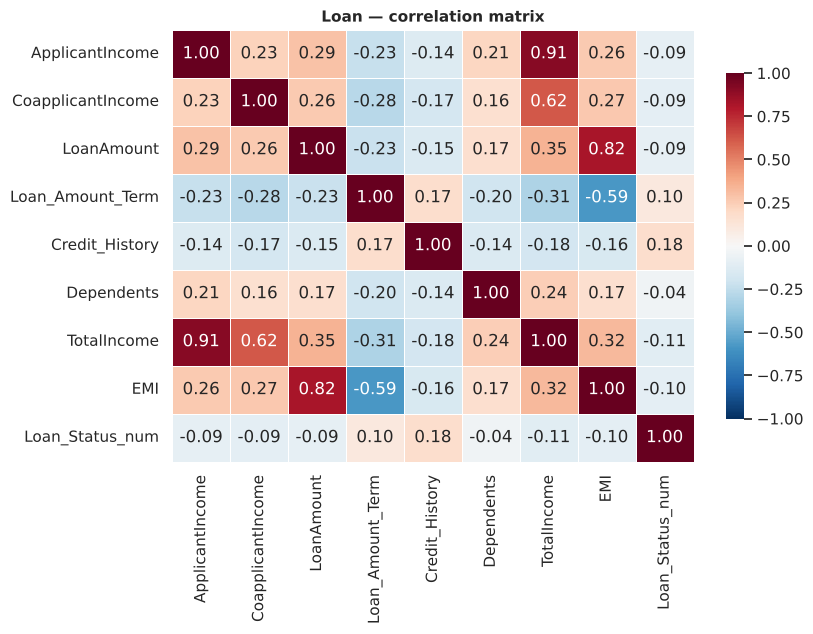

In [37]:
num_cols = ["ApplicantIncome", "CoapplicantIncome", "LoanAmount", "Loan_Amount_Term",
            "Credit_History", "Dependents", "TotalIncome", "EMI", "Loan_Status_num"]
corr = loan[num_cols].corr()
plt.figure(figsize=(8.5, 6.5))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="RdBu_r", center=0, vmin=-1, vmax=1,
            linewidths=0.5, cbar_kws={"shrink": 0.8})
plt.title("Loan — correlation matrix")
plt.tight_layout(); plt.show()

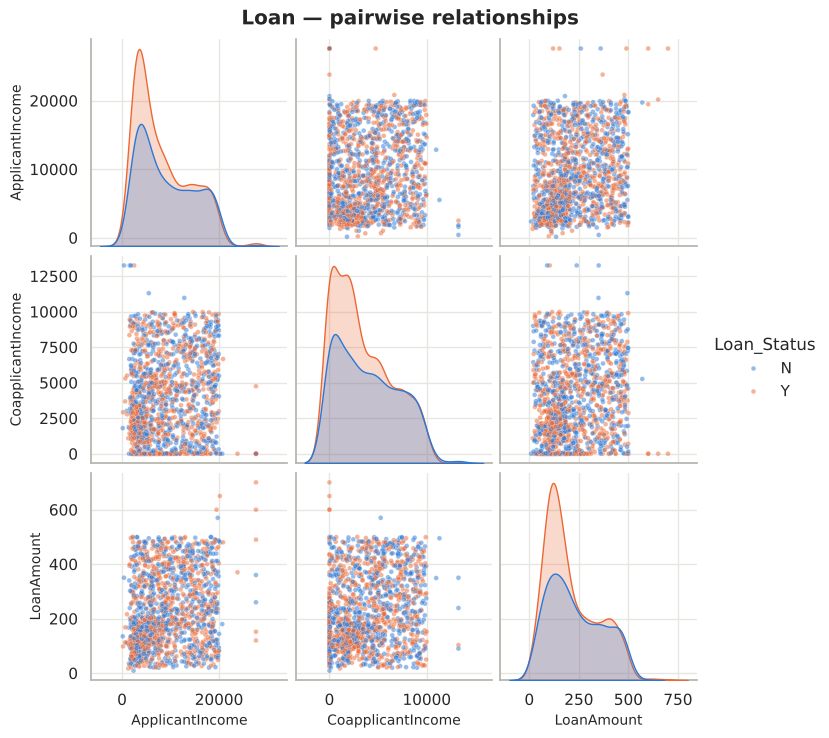

In [38]:
sns.pairplot(loan[["ApplicantIncome", "CoapplicantIncome", "LoanAmount", "Loan_Status"]],
             hue="Loan_Status", hue_order=["N", "Y"], palette=[BLUE, ORANGE],
             plot_kws={"s": 12, "alpha": 0.5}, height=2.4)
plt.suptitle("Loan — pairwise relationships", y=1.02, fontweight="bold")
plt.show()

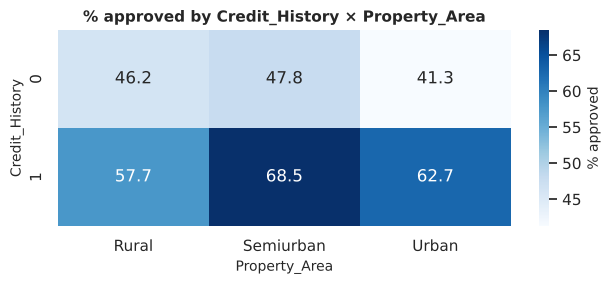

In [39]:
# Approval rate for combinations of two strong categorical drivers
pivot = loan.pivot_table(index="Credit_History", columns="Property_Area",
                         values="Loan_Status_num", aggfunc="mean") * 100
plt.figure(figsize=(6.5, 3))
sns.heatmap(pivot, annot=True, fmt=".1f", cmap="Blues", cbar_kws={"label": "% approved"})
plt.title("% approved by Credit_History × Property_Area")
plt.tight_layout(); plt.show()

## 1.7 Final verification & export

In [40]:
print("Original shape:", loan_raw.shape, "| Cleaned shape:", loan.shape)
print("Total missing values remaining:", loan.isna().sum().sum())
print("Duplicated rows:", loan.duplicated().sum())
overview(loan)

Original shape: (1614, 13) | Cleaned shape: (1614, 19)
Total missing values remaining: 0
Duplicated rows: 0


,dtype,non_null,missing,missing_%,unique,sample_values
Gender,str,1614,0,0.00,2,"[Male, Female]"
Married,str,1614,0,0.00,2,"[No, Yes]"
Dependents,int64,1614,0,0.00,4,"[0, 1, 2, 3]"
Education,str,1614,0,0.00,2,"[Graduate, Not Graduate]"
Self_Employed,str,1614,0,0.00,2,"[No, Yes]"
ApplicantIncome,float64,1614,0,0.00,1449,"[5849.0, 4583.0, 3000.0, 2583.0]"
CoapplicantIncome,float64,1614,0,0.00,1204,"[0.0, 1508.0, 2358.0, 4196.0]"
LoanAmount,float64,1614,0,0.00,461,"[180.0, 128.0, 66.0, 120.0]"
Loan_Amount_Term,int64,1614,0,0.00,10,"[360, 120, 240, 180]"
Credit_History,int64,1614,0,0.00,2,"[1, 0]"


In [41]:
loan.to_csv("loan_cleaned.csv", index=False)
print("Saved -> loan_cleaned.csv")

Saved -> loan_cleaned.csv


## 1.8 Key insights — Loan dataset
1. **Credit history is the strongest driver**: applicants with a good credit history are approved ~63% of the time vs ~45% without.
2. **Larger loan amounts are rejected more often** (median requested amount ≈205 for rejected vs ≈162 for approved).
3. **Semiurban** properties and **360-month** terms have the highest approval rates.
4. Married, graduate and salaried (not self-employed) applicants are approved slightly more often, but these effects are small.
5. Data quality: 149 missing cells across 7 columns were imputed (mode for categorical, median for `LoanAmount`); `Dependents` was converted from text to integer; `Loan_ID` was found to be non-unique (ID collisions, not duplicates) and dropped; income outliers were capped instead of removed.

---
# Part 2 — Adult Census Income Dataset

**Goal:** explore which demographic and work-related factors are associated with earning more than \$50K per year (`income`), and clean the data.

## 2.1 Load the data & first look

In [42]:
adult_raw = pd.read_csv("adult.csv")
adult = adult_raw.copy()
print("Shape:", adult.shape)
adult.head()

Shape: (48842, 15)


,age,workclass,fnlwgt,education,educational-num,marital-status,occupation,relationship,race,gender,capital-gain,capital-loss,hours-per-week,native-country,income
0,25,Private,226802,11th,7,Never-married,Machine-op-inspct,Own-child,Black,Male,0,0,40,United-States,<=50K
1,38,Private,89814,HS-grad,9,Married-civ-spouse,Farming-fishing,Husband,White,Male,0,0,50,United-States,<=50K
2,28,Local-gov,336951,Assoc-acdm,12,Married-civ-spouse,Protective-serv,Husband,White,Male,0,0,40,United-States,>50K
3,44,Private,160323,Some-college,10,Married-civ-spouse,Machine-op-inspct,Husband,Black,Male,7688,0,40,United-States,>50K
4,18,?,103497,Some-college,10,Never-married,?,Own-child,White,Female,0,0,30,United-States,<=50K


In [43]:
adult.info()

<class 'pandas.DataFrame'>
RangeIndex: 48842 entries, 0 to 48841
Data columns (total 15 columns):
 #   Column           Non-Null Count  Dtype
---  ------           --------------  -----
 0   age              48842 non-null  int64
 1   workclass        48842 non-null  str  
 2   fnlwgt           48842 non-null  int64
 3   education        48842 non-null  str  
 4   educational-num  48842 non-null  int64
 5   marital-status   48842 non-null  str  
 6   occupation       48842 non-null  str  
 7   relationship     48842 non-null  str  
 8   race             48842 non-null  str  
 9   gender           48842 non-null  str  
 10  capital-gain     48842 non-null  int64
 11  capital-loss     48842 non-null  int64
 12  hours-per-week   48842 non-null  int64
 13  native-country   48842 non-null  str  
 14  income           48842 non-null  str  
dtypes: int64(6), str(9)
memory usage: 5.6 MB


In [44]:
adult.describe(include="all").T

,count,unique,top,freq,mean,std,min,25%,50%,75%,max
age,"48,842.00",NaN,NaN,NaN,38.64,13.71,17.00,28.00,37.00,48.00,90.00
workclass,48842,9,Private,33906,NaN,NaN,NaN,NaN,NaN,NaN,NaN
fnlwgt,"48,842.00",NaN,NaN,NaN,"189,664.13","105,604.03","12,285.00","117,550.50","178,144.50","237,642.00","1,490,400.00"
education,48842,16,HS-grad,15784,NaN,NaN,NaN,NaN,NaN,NaN,NaN
educational-num,"48,842.00",NaN,NaN,NaN,10.08,2.57,1.00,9.00,10.00,12.00,16.00
marital-status,48842,7,Married-civ-spouse,22379,NaN,NaN,NaN,NaN,NaN,NaN,NaN
occupation,48842,15,Prof-specialty,6172,NaN,NaN,NaN,NaN,NaN,NaN,NaN
relationship,48842,6,Husband,19716,NaN,NaN,NaN,NaN,NaN,NaN,NaN
race,48842,5,White,41762,NaN,NaN,NaN,NaN,NaN,NaN,NaN
gender,48842,2,Male,32650,NaN,NaN,NaN,NaN,NaN,NaN,NaN


## 2.2 Overall data-quality check
`info()` reports **no missing values** — but in this dataset missing values are hidden as the character **`?`**. We check every text column for it.

In [45]:
text_cols = [c for c in adult.columns if not is_num(adult[c])]
q_marks = {c: (adult[c].astype(str).str.strip() == "?").sum() for c in text_cols}
q_marks = pd.Series(q_marks)
print("Count of '?' per text column:")
print(q_marks[q_marks > 0])

print("\nLeading/trailing spaces present:",
      {c: (adult[c].astype(str) != adult[c].astype(str).str.strip()).sum() for c in text_cols})
print("Fully duplicated rows:", adult.duplicated().sum())

Count of '?' per text column:
workclass         2799
occupation        2809
native-country     857
dtype: int64



Leading/trailing spaces present: {'workclass': np.int64(0), 'education': np.int64(0), 'marital-status': np.int64(0), 'occupation': np.int64(0), 'relationship': np.int64(0), 'race': np.int64(0), 'gender': np.int64(0), 'native-country': np.int64(0), 'income': np.int64(0)}
Fully duplicated rows: 52


**Global cleaning steps (apply to all columns):**
1. Strip whitespace from every text column (safety step — values are already clean).
2. Replace the placeholder `?` with a real missing value (`NaN`) so pandas can detect it.
3. Remove the **52 exact duplicate rows** (identical on all 15 columns).

Duplicates removed: 52 | New shape: (48790, 15)


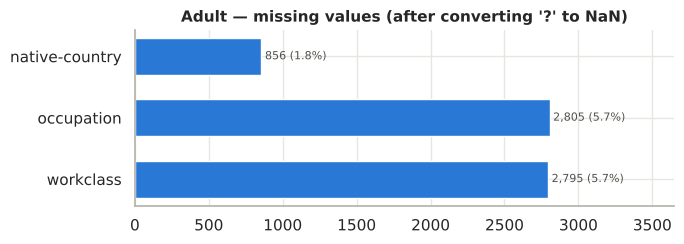

In [46]:
for c in text_cols:
    adult[c] = adult[c].astype(str).str.strip()
adult = adult.replace("?", np.nan)

before = len(adult)
adult = adult.drop_duplicates().reset_index(drop=True)
print(f"Duplicates removed: {before - len(adult)} | New shape: {adult.shape}")

missing = adult.isna().sum()
missing = missing[missing > 0]
fig, ax = plt.subplots(figsize=(7, 2.6))
ax.barh(missing.index, missing.values, color=BLUE, height=0.6)
for i, v in enumerate(missing.values):
    ax.text(v, i, f" {v:,} ({v/len(adult)*100:.1f}%)", va="center", fontsize=8, color=INK)
ax.set_xlim(0, missing.max() * 1.3)
ax.set_title("Adult — missing values (after converting '?' to NaN)")
plt.tight_layout(); plt.show()

In [47]:
overview(adult)

,dtype,non_null,missing,missing_%,unique,sample_values
age,int64,48790,0,0.00,74,"[25, 38, 28, 44]"
workclass,str,45995,2795,5.73,8,"[Private, Local-gov, Self-emp-not-inc, Federal..."
fnlwgt,int64,48790,0,0.00,28523,"[226802, 89814, 336951, 160323]"
education,str,48790,0,0.00,16,"[11th, HS-grad, Assoc-acdm, Some-college]"
educational-num,int64,48790,0,0.00,16,"[7, 9, 12, 10]"
marital-status,str,48790,0,0.00,7,"[Never-married, Married-civ-spouse, Widowed, D..."
occupation,str,45985,2805,5.75,14,"[Machine-op-inspct, Farming-fishing, Protectiv..."
relationship,str,48790,0,0.00,6,"[Own-child, Husband, Not-in-family, Unmarried]"
race,str,48790,0,0.00,5,"[Black, White, Asian-Pac-Islander, Other]"
gender,str,48790,0,0.00,2,"[Male, Female]"


## 2.3 Target variable — `income`

Column : income
dtype  : str
Missing: 0 (0.00%)
Unique : 2
----------------------------------------
        count  percent
income                
<=50K   37109    76.06
>50K    11681    23.94


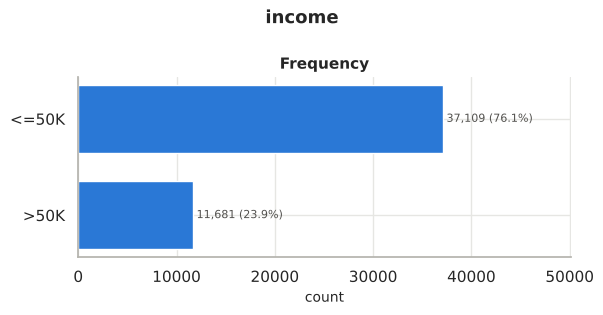

In [48]:
profile(adult, "income")
plot_categorical(adult, "income")

**Observations — `income`**
- `<=50K` ≈ 76%, `>50K` ≈ 24% → the target is **imbalanced (about 3 : 1)**. Any model trained later should use stratified splits or class weights.
- Only two clean labels (no variants such as `>50K.`).

**Cleaning:** add a numeric target `income_num` (1 = `>50K`).

In [49]:
adult["income_num"] = (adult["income"] == ">50K").astype(int)
adult["income_num"].value_counts()

income_num
0    37109
1    11681
Name: count, dtype: int64

## 2.4 Column-by-column analysis & cleaning

### Column 1 — `age`

Column : age
dtype  : int64
Missing: 0 (0.00%)
Unique : 74
----------------------------------------
count   48,790.00
mean        38.65
std         13.71
min         17.00
25%         28.00
50%         37.00
75%         48.00
max         90.00
skewness : 0.557
kurtosis : -0.187
zeros    : 0 (0.00%)
IQR fences: [-2.00, 78.00] -> outliers: 215 (0.44%)


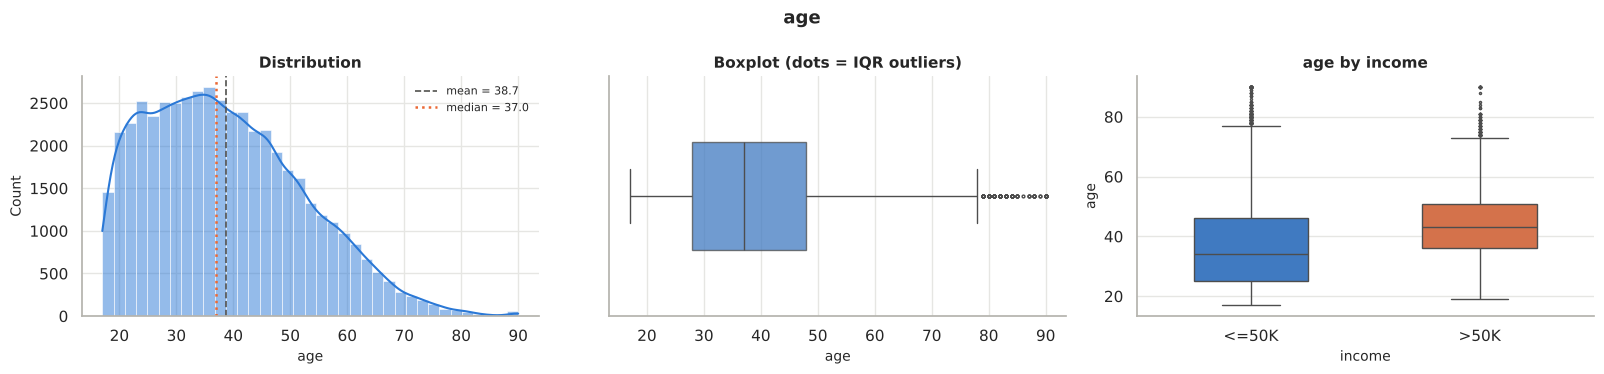

In [50]:
profile(adult, "age")
plot_numeric(adult, "age", target="income", order=["<=50K", ">50K"], bins=37)

**Observations — `age`**
- Range 17 – 90, mean ≈ 38.6, median 37; slightly right-skewed (more young workers).
- About 216 IQR "outliers" (age > 78) are **genuine older people**, not errors.
- People earning `>50K` are older on average (≈44 vs ≈37 years) — income rises with experience.

**Cleaning:** no missing or invalid values; outliers kept. An `age_group` column is added for easier analysis.

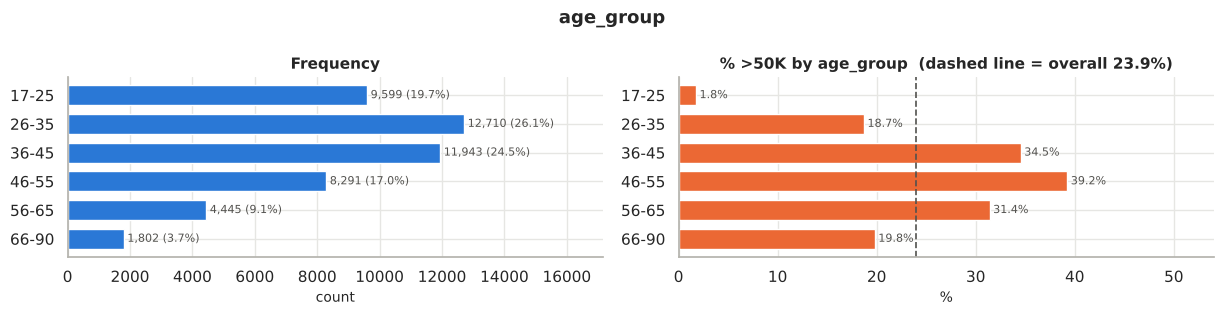

In [51]:
adult["age_group"] = pd.cut(adult["age"], bins=[16, 25, 35, 45, 55, 65, 90],
                            labels=["17-25", "26-35", "36-45", "46-55", "56-65", "66-90"])
plot_categorical(adult, "age_group", target="income", pos=">50K")

### Column 2 — `workclass`

Column : workclass
dtype  : str
Missing: 2,795 (5.73%)
Unique : 8
----------------------------------------
                  count  percent
workclass                       
Private           33860    69.40
Self-emp-not-inc   3861     7.91
Local-gov          3136     6.43
NaN                2795     5.73
State-gov          1981     4.06
Self-emp-inc       1694     3.47
Federal-gov        1432     2.94
Without-pay          21     0.04
Never-worked         10     0.02


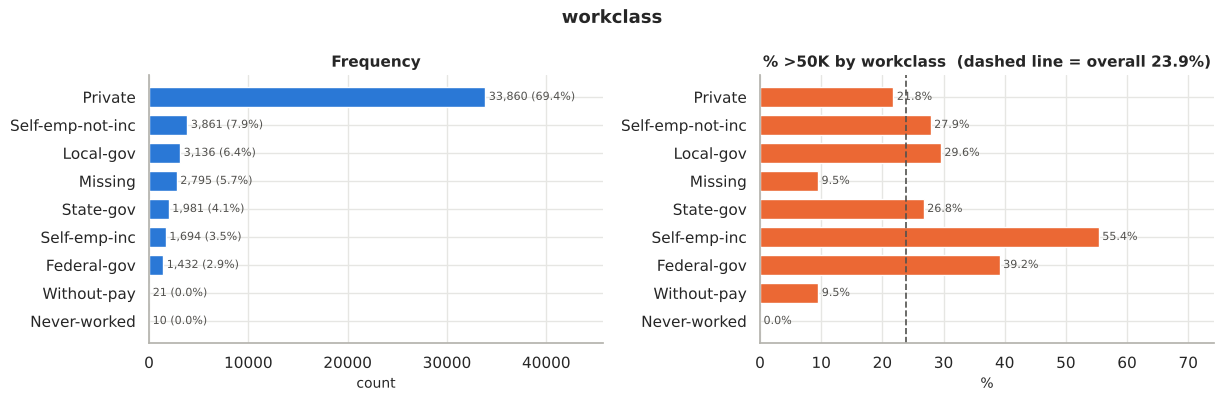

In [52]:
profile(adult, "workclass")
plot_categorical(adult, "workclass", target="income", pos=">50K")

**Observations — `workclass`**
- `Private` dominates (≈69%). `?` (now *Missing*) affects 2,799 rows (≈5.7%).
- `Self-emp-inc` (incorporated business owners) has the highest share of `>50K` (≈55%), followed by `Federal-gov` (≈39%).
- Rows with missing workclass have a very low `>50K` rate (≈9.5%) — they behave differently from `Private`, so filling them with the mode would bias the data.

**Cleaning:** fill missing values with a separate category **`Unknown`**.

In [53]:
adult["workclass"] = adult["workclass"].fillna("Unknown")
print("Missing after cleaning:", adult["workclass"].isna().sum())

Missing after cleaning: 0


### Column 3 — `fnlwgt` (final sampling weight)

Column : fnlwgt
dtype  : int64
Missing: 0 (0.00%)
Unique : 28,523
----------------------------------------
count      48,790.00
mean      189,669.00
std       105,617.23
min        12,285.00
25%       117,555.00
50%       178,138.50
75%       237,606.25
max     1,490,400.00
skewness : 1.440
kurtosis : 6.061
zeros    : 0 (0.00%)
IQR fences: [-62,521.88, 417,683.12] -> outliers: 1,453 (2.98%)


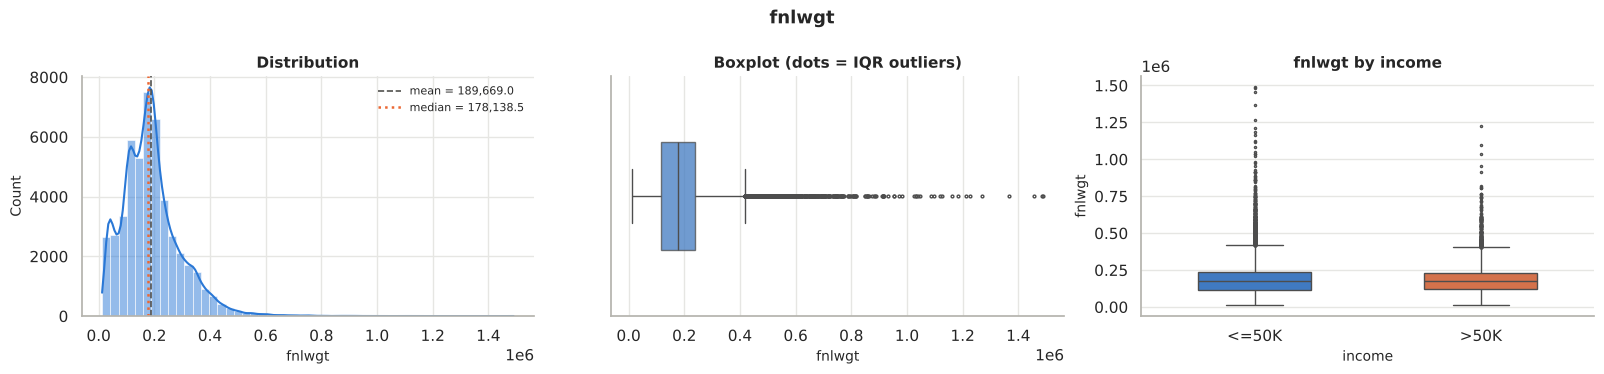

In [54]:
profile(adult, "fnlwgt")
plot_numeric(adult, "fnlwgt", target="income", order=["<=50K", ">50K"], bins=50)

**Observations — `fnlwgt`**
- A census **sampling weight** (how many people each row represents), not a personal attribute.
- Strongly right-skewed (skewness ≈ 1.4) with ≈1,450 IQR outliers.
- The distribution is almost identical for both income groups (medians ≈177K vs ≈179K) → **no relationship with income**.

**Cleaning:** no missing values. Outliers are valid weights and kept. A log version is added; for modelling this column is usually dropped.

In [55]:
adult["fnlwgt_log"] = np.log1p(adult["fnlwgt"])
print(f"Skewness raw: {adult['fnlwgt'].skew():.2f} | log: {adult['fnlwgt_log'].skew():.2f}")

Skewness raw: 1.44 | log: -0.84


### Column 4 — `education`

Column : education
dtype  : str
Missing: 0 (0.00%)
Unique : 16
----------------------------------------
              count  percent
education                   
HS-grad       15770    32.32
Some-college  10863    22.26
Bachelors      8013    16.42
Masters        2656     5.44
Assoc-voc      2060     4.22
11th           1812     3.71
Assoc-acdm     1601     3.28
10th           1389     2.85
7th-8th         954     1.96
Prof-school     834     1.71
9th             756     1.55
12th            655     1.34
Doctorate       594     1.22
5th-6th         507     1.04
1st-4th         245     0.50
Preschool        81     0.17


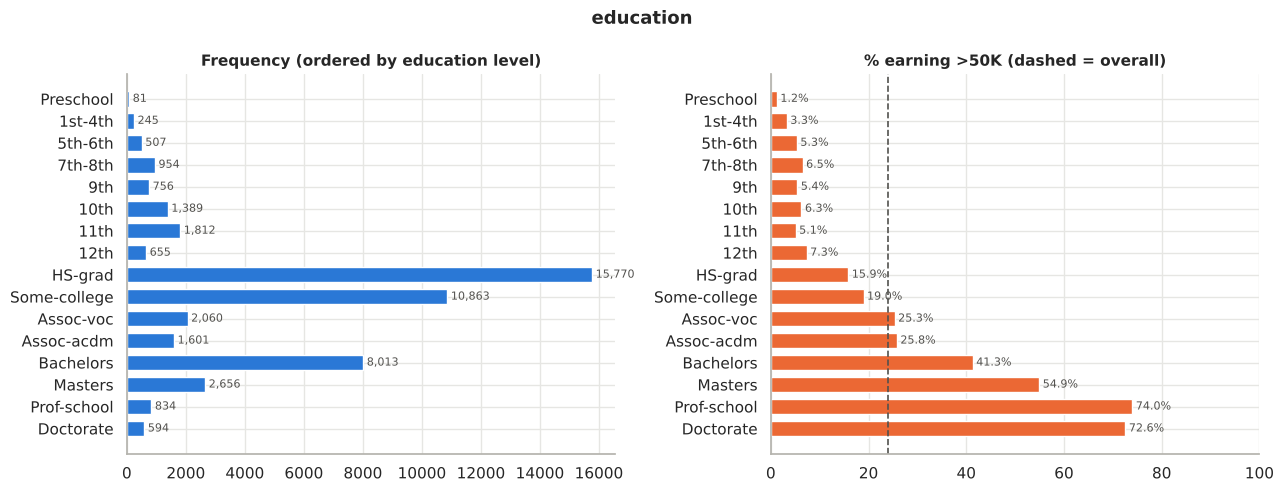

In [56]:
edu_order = (adult[["education", "educational-num"]].drop_duplicates()
             .sort_values("educational-num")["education"].tolist())
profile(adult, "education", top=16)

y = adult["income_num"]
cnt = adult["education"].value_counts().reindex(edu_order)
rate = (y.groupby(adult["education"]).mean() * 100).reindex(edu_order)
fig, axes = plt.subplots(1, 2, figsize=(13, 5))
axes[0].barh(edu_order[::-1], cnt.values[::-1], color=BLUE, height=0.7)
for i, v in enumerate(cnt.values[::-1]):
    axes[0].text(v, i, f" {v:,}", va="center", fontsize=8, color=INK)
axes[0].set_title("Frequency (ordered by education level)")
axes[1].barh(edu_order[::-1], rate.values[::-1], color=ORANGE, height=0.7)
for i, v in enumerate(rate.values[::-1]):
    axes[1].text(v, i, f" {v:.1f}%", va="center", fontsize=8, color=INK)
axes[1].axvline(y.mean() * 100, color=INK, ls="--", lw=1.2)
axes[1].set_title("% earning >50K (dashed = overall)")
axes[1].set_xlim(0, 100)
fig.suptitle("education", fontsize=13, fontweight="bold")
plt.tight_layout(); plt.show()

**Observations — `education`**
- 16 levels; most common are `HS-grad` (≈32%), `Some-college` (≈22%) and `Bachelors` (≈16%).
- A very clear pattern: the share of `>50K` **rises steadily with education** — from ≈5% for school drop-outs to ≈73–74% for `Doctorate` and `Prof-school`.
- The 12 school levels below HS-grad are small groups.

**Cleaning:** no missing values. Add a simplified `education_group` (School / HS-grad / College / Bachelors / Postgrad) to reduce sparse categories.

Unmapped values: 0


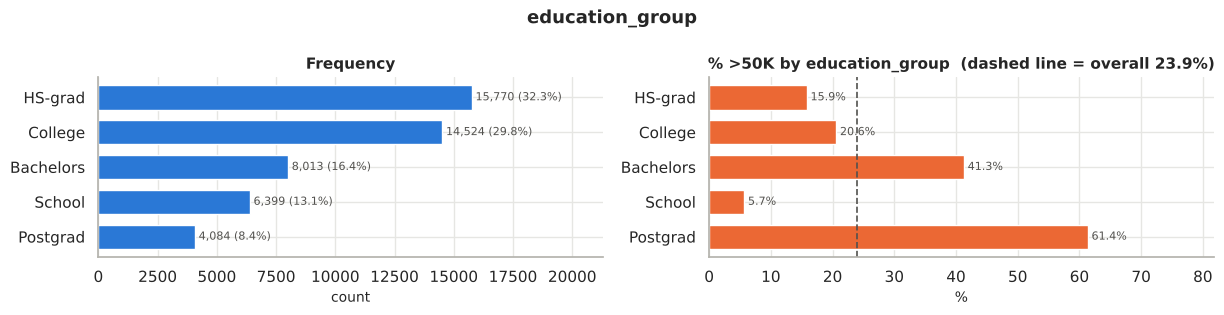

In [57]:
edu_map = {"Preschool": "School", "1st-4th": "School", "5th-6th": "School", "7th-8th": "School",
           "9th": "School", "10th": "School", "11th": "School", "12th": "School",
           "HS-grad": "HS-grad", "Some-college": "College", "Assoc-voc": "College",
           "Assoc-acdm": "College", "Bachelors": "Bachelors", "Masters": "Postgrad",
           "Prof-school": "Postgrad", "Doctorate": "Postgrad"}
adult["education_group"] = adult["education"].map(edu_map)
print("Unmapped values:", adult["education_group"].isna().sum())
plot_categorical(adult, "education_group", target="income", pos=">50K")

### Column 5 — `educational-num`

Column : educational-num
dtype  : int64
Missing: 0 (0.00%)
Unique : 16
----------------------------------------
count   48,790.00
mean        10.08
std          2.57
min          1.00
25%          9.00
50%         10.00
75%         12.00
max         16.00
skewness : -0.314
kurtosis : 0.621
zeros    : 0 (0.00%)
IQR fences: [4.50, 16.50] -> outliers: 1,787 (3.66%)


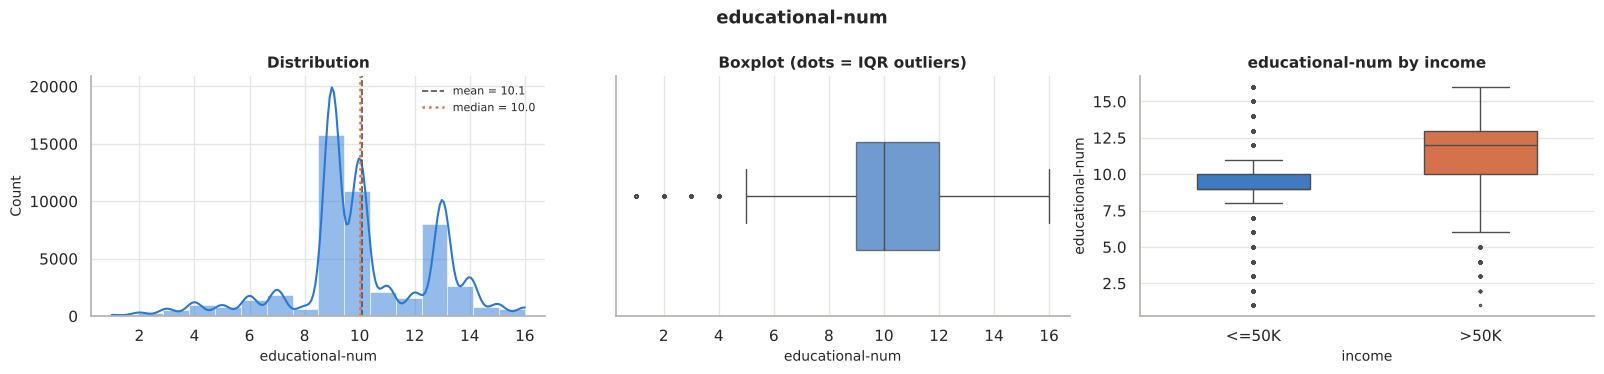

Each education level maps to exactly one number: True


In [58]:
profile(adult, "educational-num")
plot_numeric(adult, "educational-num", target="income", order=["<=50K", ">50K"], bins=16)

# Is educational-num just a numeric code for education?
check = adult.groupby("education")["educational-num"].nunique()
print("Each education level maps to exactly one number:", (check == 1).all())

**Observations — `educational-num`**
- Values 1–16, median 10. The ≈1,800 IQR "outliers" are just the low school levels (1–4) — valid values.
- It is a **one-to-one numeric code of `education`** (verified above) → the two columns carry the same information.
- `>50K` earners have a higher median (12 vs 9).

**Cleaning:** no missing values. Keep it (it is the numeric, ordered version — better for models); `education` can be dropped before modelling to avoid redundancy.

### Column 6 — `marital-status`

Column : marital-status
dtype  : str
Missing: 0 (0.00%)
Unique : 7
----------------------------------------
                       count  percent
marital-status                       
Married-civ-spouse     22366    45.84
Never-married          16082    32.96
Divorced                6630    13.59
Separated               1530     3.14
Widowed                 1518     3.11
Married-spouse-absent    627     1.29
Married-AF-spouse         37     0.08


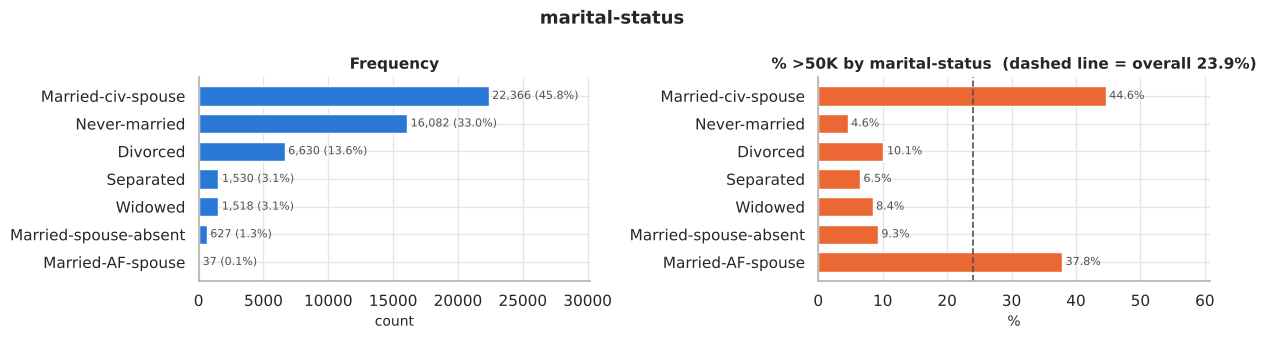

In [59]:
profile(adult, "marital-status")
plot_categorical(adult, "marital-status", target="income", pos=">50K")

**Observations — `marital-status`**
- `Married-civ-spouse` (≈46%) and `Never-married` (≈33%) are the main groups.
- **Married-civ-spouse has ≈45% `>50K`**, while Never-married has only ≈4.5% — one of the strongest signals in the data (partly linked to age).

**Cleaning:** no missing values. Add a simplified `marital_group` (Married / Not-married).

In [60]:
married = ["Married-civ-spouse", "Married-AF-spouse", "Married-spouse-absent"]
adult["marital_group"] = np.where(adult["marital-status"].isin(married), "Married", "Not-married")
adult["marital_group"].value_counts()

marital_group
Not-married    25760
Married        23030
Name: count, dtype: int64

### Column 7 — `occupation`

Column : occupation
dtype  : str
Missing: 2,805 (5.75%)
Unique : 14
----------------------------------------
                   count  percent
occupation                       
Prof-specialty      6165    12.64
Craft-repair        6102    12.51
Exec-managerial     6082    12.47
Adm-clerical        5606    11.49
Sales               5501    11.27
Other-service       4919    10.08
Machine-op-inspct   3017     6.18
NaN                 2805     5.75
Transport-moving    2355     4.83
Handlers-cleaners   2071     4.24
Farming-fishing     1485     3.04
Tech-support        1445     2.96
Protective-serv      982     2.01
Priv-house-serv      240     0.49
Armed-Forces          15     0.03


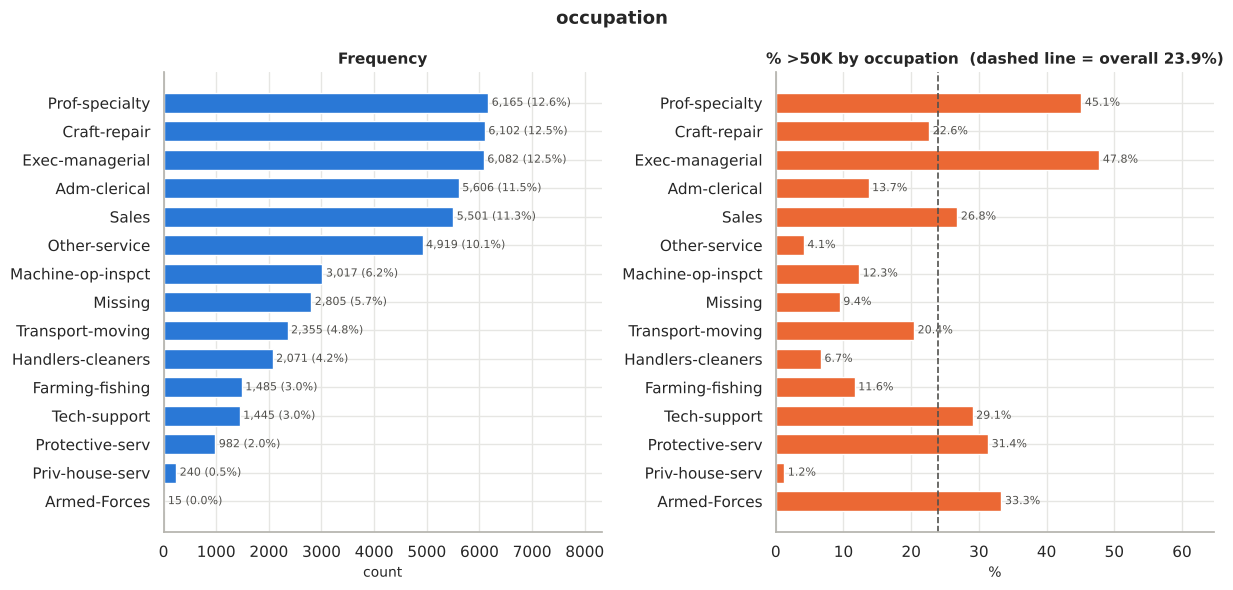

In [61]:
profile(adult, "occupation")
plot_categorical(adult, "occupation", target="income", pos=">50K")

In [62]:
# Are missing occupation and missing workclass the same people?
both = (adult["occupation"].isna() & (adult["workclass"] == "Unknown")).sum()
print(f"Rows missing occupation: {adult['occupation'].isna().sum():,} | also missing workclass: {both:,}")
print(adult.loc[adult["occupation"].isna(), "workclass"].value_counts())

Rows missing occupation: 2,805 | also missing workclass: 2,795
workclass
Unknown         2795
Never-worked      10
Name: count, dtype: int64


**Observations — `occupation`**
- 14 occupations; `Prof-specialty`, `Craft-repair` and `Exec-managerial` are the largest.
- `Exec-managerial` (≈48%) and `Prof-specialty` (≈45%) have the highest `>50K` share; `Priv-house-serv` and `Other-service` the lowest.
- ≈2,800 missing values (≈5.7%). Almost all of them are the same rows where `workclass` is missing; the remaining ones are `Never-worked` people, who have no occupation.

**Cleaning:** fill missing with `Unknown` (same reasoning as `workclass`).

In [63]:
adult["occupation"] = adult["occupation"].fillna("Unknown")
print("Missing after cleaning:", adult["occupation"].isna().sum())

Missing after cleaning: 0


### Column 8 — `relationship`

Column : relationship
dtype  : str
Missing: 0 (0.00%)
Unique : 6
----------------------------------------
                count  percent
relationship                  
Husband         19703    40.38
Not-in-family   12557    25.74
Own-child        7569    15.51
Unmarried        5124    10.50
Wife             2331     4.78
Other-relative   1506     3.09


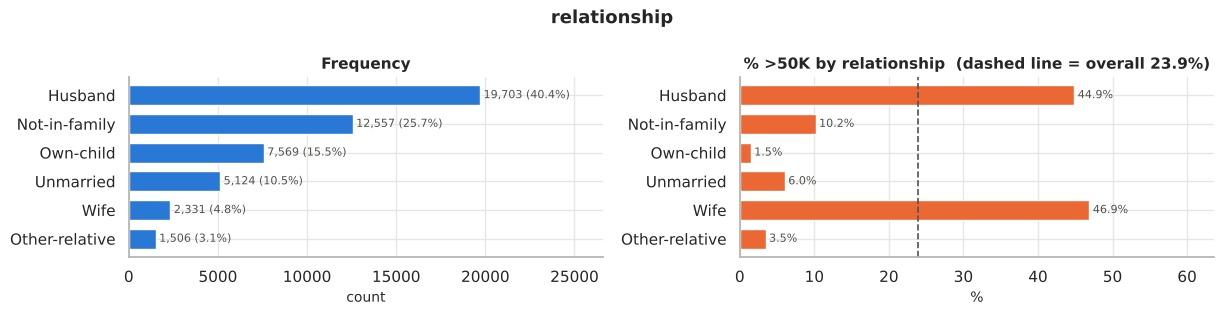

In [64]:
profile(adult, "relationship")
plot_categorical(adult, "relationship", target="income", pos=">50K")

**Observations — `relationship`**
- `Husband` (≈40%) and `Not-in-family` (≈26%) are the largest groups.
- `Wife` (≈47%) and `Husband` (≈45%) have the highest `>50K` share; `Own-child` is lowest (≈1.5%) — mostly young people still living with parents.
- This column overlaps heavily with `marital-status` and `gender` (Husband ⇒ male & married).

**Cleaning:** no missing or inconsistent values — none required.

### Column 9 — `race`

Column : race
dtype  : str
Missing: 0 (0.00%)


Unique : 5
----------------------------------------
                    count  percent
race                              
White               41714    85.50
Black                4683     9.60
Asian-Pac-Islander   1517     3.11
Amer-Indian-Eskimo    470     0.96
Other                 406     0.83


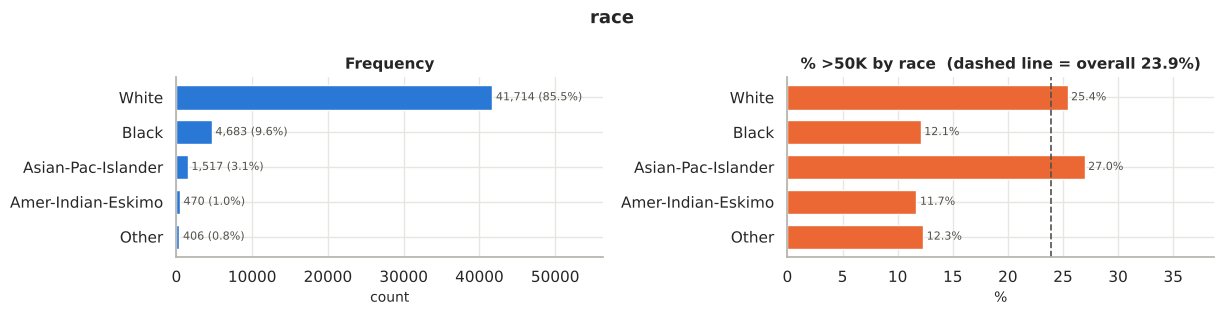

In [65]:
profile(adult, "race")
plot_categorical(adult, "race", target="income", pos=">50K")

**Observations — `race`**
- Highly unbalanced: `White` ≈ 86% of rows.
- `Asian-Pac-Islander` (≈27%) and `White` (≈25%) have higher `>50K` shares than `Black` (≈12%), `Amer-Indian-Eskimo` (≈12%) and `Other` (≈12%).
- Small groups mean these percentages are less reliable; this is a **sensitive attribute** and should be handled carefully (fairness) in any model.

**Cleaning:** none required.

### Column 10 — `gender`

Column : gender
dtype  : str
Missing: 0 (0.00%)
Unique : 2
----------------------------------------
        count  percent
gender                
Male    32614    66.85
Female  16176    33.15


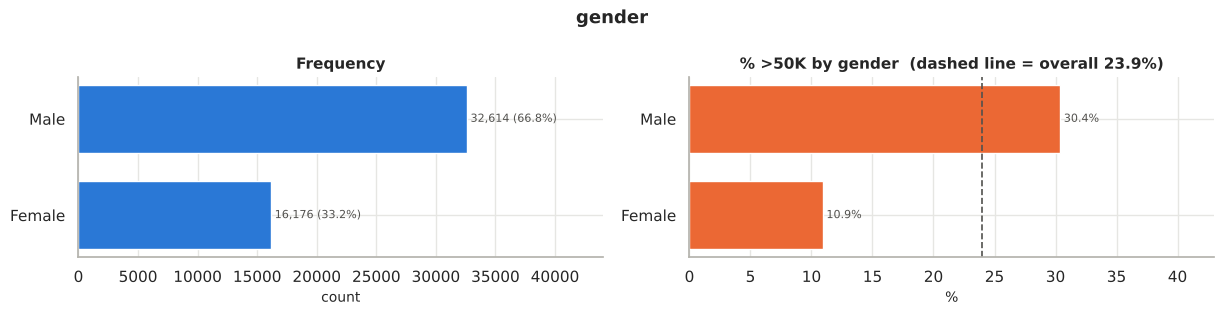

In [66]:
profile(adult, "gender")
plot_categorical(adult, "gender", target="income", pos=">50K")

**Observations — `gender`**
- Male ≈ 67%, Female ≈ 33%.
- **≈30% of men vs ≈11% of women earn `>50K`** — a large gap reflecting the 1994 census (also linked to hours worked and occupation).

**Cleaning:** none required.

### Column 11 — `capital-gain`

Column : capital-gain
dtype  : int64
Missing: 0 (0.00%)
Unique : 123
----------------------------------------
count   48,790.00
mean     1,080.22
std      7,455.91
min          0.00
25%          0.00
50%          0.00
75%          0.00
max     99,999.00
skewness : 11.888
kurtosis : 152.527
zeros    : 44,755 (91.73%)
IQR fences: [0.00, 0.00] -> outliers: 4,035 (8.27%)


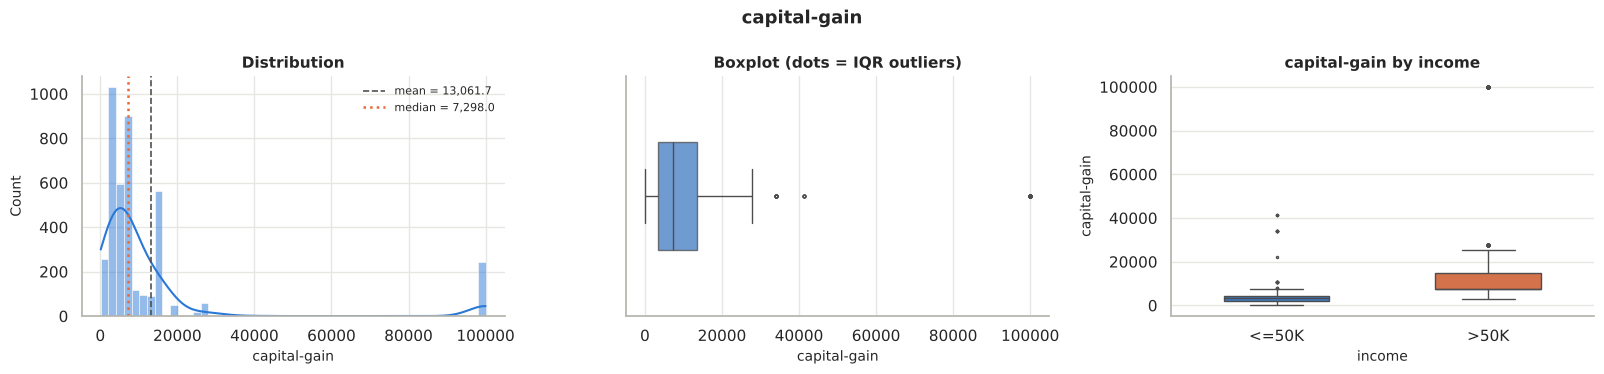

Plots above show ONLY the non-zero values (zeros are ~92% of rows).
Rows with the value 99999: 244


In [67]:
profile(adult, "capital-gain")
plot_numeric(adult[adult["capital-gain"] > 0], "capital-gain", target="income",
             order=["<=50K", ">50K"], bins=50)
print("Plots above show ONLY the non-zero values (zeros are ~92% of rows).")
print("Rows with the value 99999:", (adult["capital-gain"] == 99999).sum())

**Observations — `capital-gain`**
- **≈92% of values are 0** → extremely skewed (skewness ≈ 12).
- `99999` appears ≈244 times — this is the census **top-code** (a maximum cap), not a real amount.
- Having *any* capital gain is a strong signal: ≈62% of people with gains earn `>50K` vs ≈21% without.

**Cleaning:** no missing values. Values are kept (99999 is a legitimate cap). Add a binary flag `has_capital_gain` and a log version.

In [68]:
adult["has_capital_gain"] = (adult["capital-gain"] > 0).astype(int)
adult["capital_gain_log"] = np.log1p(adult["capital-gain"])
adult.groupby("has_capital_gain")["income_num"].mean().mul(100).round(1)

has_capital_gain
0   20.50
1   61.70
Name: income_num, dtype: float64

### Column 12 — `capital-loss`

Column : capital-loss
dtype  : int64
Missing: 0 (0.00%)
Unique : 99
----------------------------------------
count   48,790.00
mean        87.60
std        403.21
min          0.00
25%          0.00
50%          0.00
75%          0.00
max      4,356.00
skewness : 4.567
kurtosis : 19.988
zeros    : 46,508 (95.32%)
IQR fences: [0.00, 0.00] -> outliers: 2,282 (4.68%)


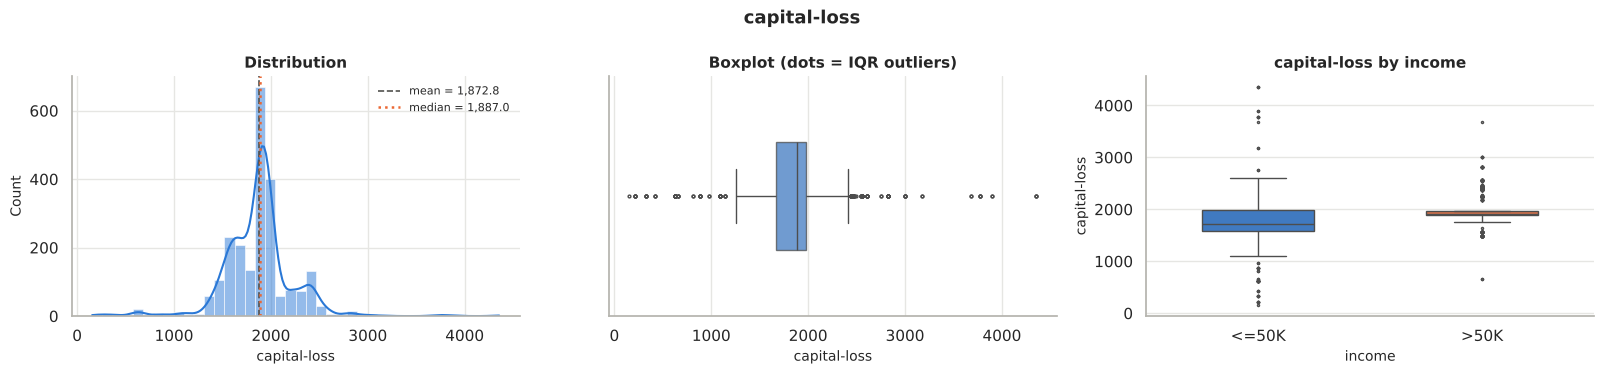

Plots above show ONLY the non-zero values (zeros are ~95% of rows).


In [69]:
profile(adult, "capital-loss")
plot_numeric(adult[adult["capital-loss"] > 0], "capital-loss", target="income",
             order=["<=50K", ">50K"], bins=40)
print("Plots above show ONLY the non-zero values (zeros are ~95% of rows).")

**Observations — `capital-loss`**
- ≈95% zeros; non-zero values cluster around 1,500–2,500.
- People reporting a capital loss earn `>50K` about half the time (≈50% vs ≈23%) — reporting investment losses implies having investments.

**Cleaning:** no missing values; add `has_capital_loss` flag.

In [70]:
adult["has_capital_loss"] = (adult["capital-loss"] > 0).astype(int)
adult.groupby("has_capital_loss")["income_num"].mean().mul(100).round(1)

has_capital_loss
0   22.70
1   50.10
Name: income_num, dtype: float64

### Column 13 — `hours-per-week`

Column : hours-per-week
dtype  : int64
Missing: 0 (0.00%)
Unique : 96
----------------------------------------
count   48,790.00
mean        40.43
std         12.39
min          1.00
25%         40.00
50%         40.00
75%         45.00
max         99.00
skewness : 0.240
kurtosis : 2.951
zeros    : 0 (0.00%)
IQR fences: [32.50, 52.50] -> outliers: 13,486 (27.64%)


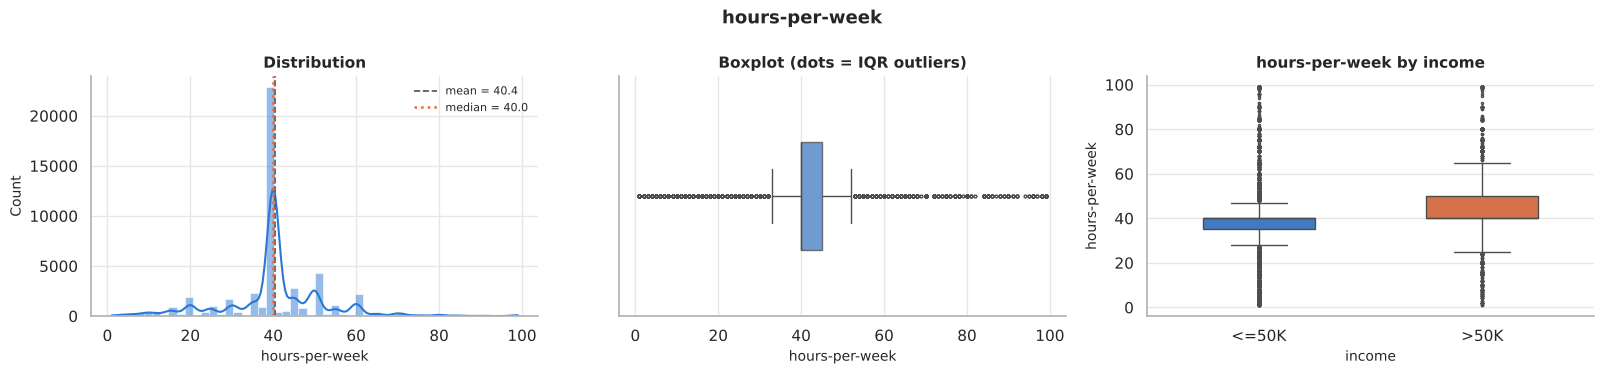

In [71]:
profile(adult, "hours-per-week")
plot_numeric(adult, "hours-per-week", target="income", order=["<=50K", ">50K"], bins=50)

**Observations — `hours-per-week`**
- Range 1 – 99; **≈47% of people work exactly 40 hours**, which makes the IQR very narrow — that is why ≈13,500 values are flagged as "outliers". Most of these (part-time or long hours) are realistic.
- `>50K` earners work more on average (≈45 vs ≈39 hours).

**Cleaning:** no missing values. Values are kept; a `work_type` category (Part-time / Full-time / Overtime) is added.

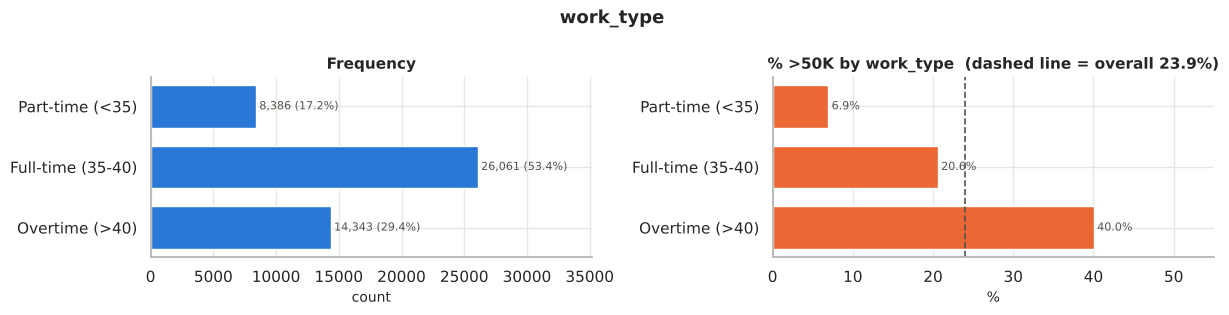

In [72]:
adult["work_type"] = pd.cut(adult["hours-per-week"], bins=[0, 34, 40, 99],
                            labels=["Part-time (<35)", "Full-time (35-40)", "Overtime (>40)"])
plot_categorical(adult, "work_type", target="income", pos=">50K")

### Column 14 — `native-country`

Column : native-country
dtype  : str
Missing: 856 (1.75%)
Unique : 41
----------------------------------------
                count  percent
native-country                
United-States   43792    89.76
Mexico            943     1.93
NaN               856     1.75
Philippines       294     0.60
Germany           206     0.42
Puerto-Rico       184     0.38
Canada            182     0.37
El-Salvador       155     0.32
India             151     0.31
Cuba              138     0.28
England           127     0.26
China             122     0.25
... 30 more categories


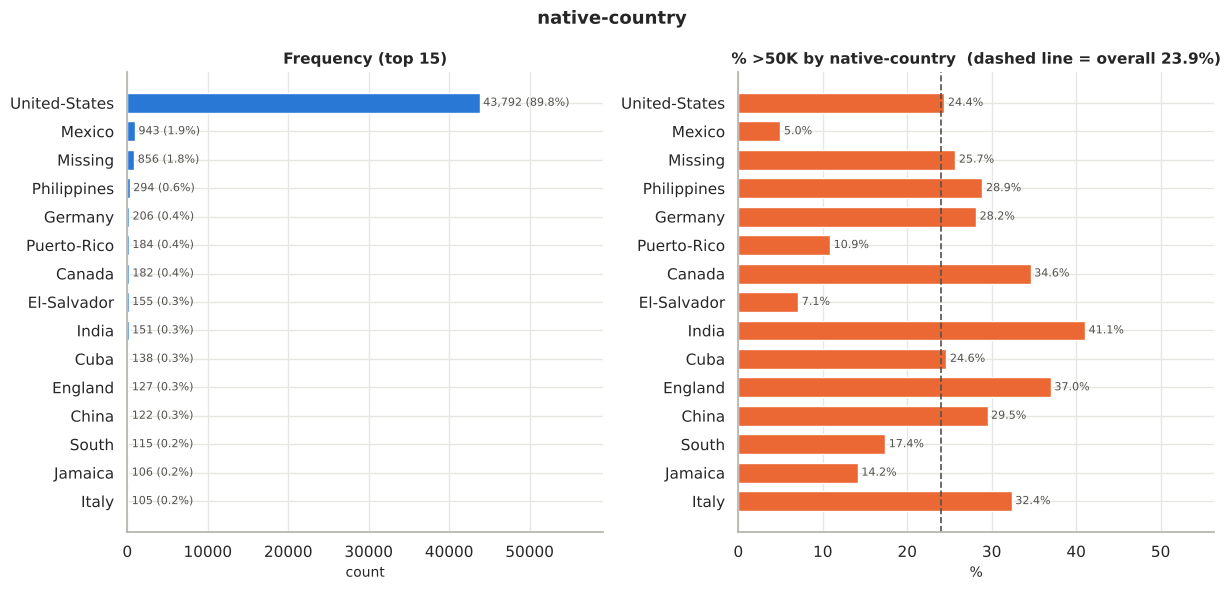

In [73]:
profile(adult, "native-country", top=12)
plot_categorical(adult, "native-country", target="income", pos=">50K", top=15)

**Observations — `native-country`**
- 41 countries, but **United-States ≈ 90%**; Mexico is second (≈2%). 26 countries have fewer than 100 rows.
- 857 missing values (≈1.8%). Their `>50K` rate (≈26%) is close to that of the US group (≈24%).
- Mexico has a very low `>50K` share (≈5%); India and Canada are above average.

**Cleaning:**
1. Fill missing with the mode (`United-States`) — justified because the missing group behaves like the US group.
2. Add `native_region` = US / Non-US to deal with the many sparse categories.

In [74]:
adult["native-country"] = adult["native-country"].fillna(adult["native-country"].mode()[0])
adult["native_region"] = np.where(adult["native-country"] == "United-States", "US", "Non-US")
print("Missing after cleaning:", adult["native-country"].isna().sum())
adult["native_region"].value_counts()

Missing after cleaning: 0


native_region
US        44648
Non-US     4142
Name: count, dtype: int64

### Column 15 — `income`
Already analysed in section 2.3 (target). Cleaning done: added `income_num`.

## 2.5 Multivariate analysis

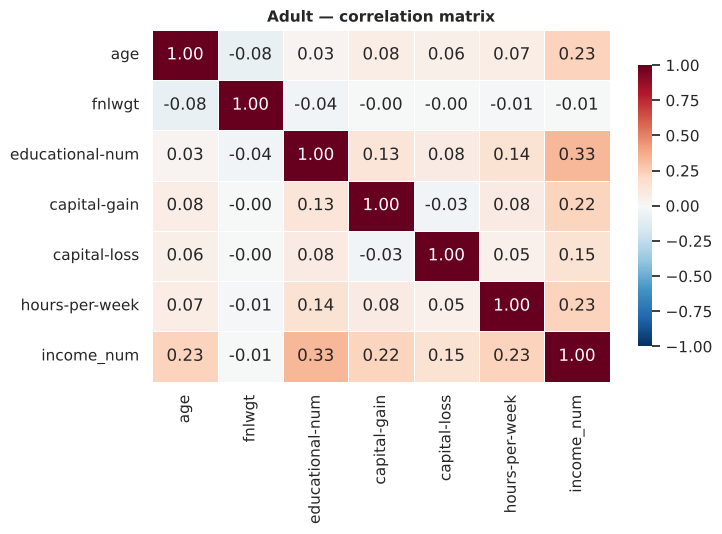

In [75]:
num_cols = ["age", "fnlwgt", "educational-num", "capital-gain", "capital-loss",
            "hours-per-week", "income_num"]
plt.figure(figsize=(7.5, 5.5))
sns.heatmap(adult[num_cols].corr(), annot=True, fmt=".2f", cmap="RdBu_r", center=0,
            vmin=-1, vmax=1, linewidths=0.5, cbar_kws={"shrink": 0.8})
plt.title("Adult — correlation matrix")
plt.tight_layout(); plt.show()

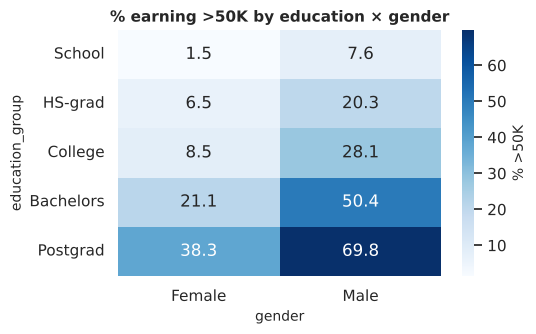

In [76]:
pivot = adult.pivot_table(index="education_group", columns="gender",
                          values="income_num", aggfunc="mean") * 100
pivot = pivot.reindex(["School", "HS-grad", "College", "Bachelors", "Postgrad"])
plt.figure(figsize=(5.5, 3.5))
sns.heatmap(pivot, annot=True, fmt=".1f", cmap="Blues", cbar_kws={"label": "% >50K"})
plt.title("% earning >50K by education × gender")
plt.tight_layout(); plt.show()

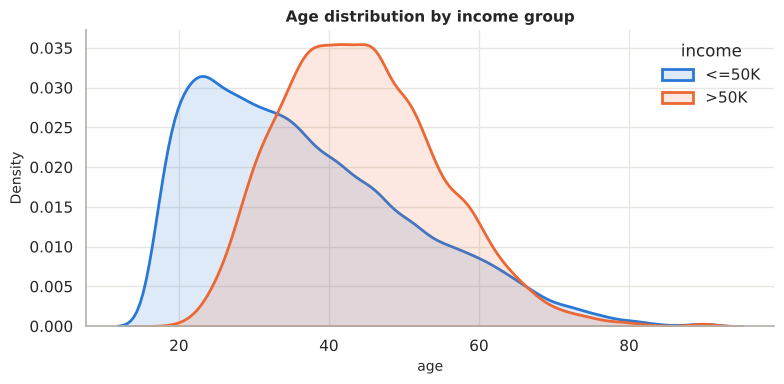

In [77]:
fig, ax = plt.subplots(figsize=(8, 4))
for lvl, col in [("<=50K", BLUE), (">50K", ORANGE)]:
    sub = adult[adult["income"] == lvl]
    sns.kdeplot(sub["age"], ax=ax, color=col, lw=2, label=lvl, fill=True, alpha=0.15)
ax.set_title("Age distribution by income group")
ax.legend(title="income", frameon=False)
plt.tight_layout(); plt.show()

## 2.6 Final verification & export

In [78]:
print("Original shape:", adult_raw.shape, "| Cleaned shape:", adult.shape)
print("Total missing values remaining:", adult.isna().sum().sum())
print("'?' values remaining:", (adult.astype(str) == "?").sum().sum())
print("Duplicated rows:", adult.duplicated().sum())
overview(adult)

Original shape: (48842, 15) | Cleaned shape: (48790, 25)
Total missing values remaining: 0


'?' values remaining: 0
Duplicated rows: 0


,dtype,non_null,missing,missing_%,unique,sample_values
age,int64,48790,0,0.00,74,"[25, 38, 28, 44]"
workclass,str,48790,0,0.00,9,"[Private, Local-gov, Unknown, Self-emp-not-inc]"
fnlwgt,int64,48790,0,0.00,28523,"[226802, 89814, 336951, 160323]"
education,str,48790,0,0.00,16,"[11th, HS-grad, Assoc-acdm, Some-college]"
educational-num,int64,48790,0,0.00,16,"[7, 9, 12, 10]"
marital-status,str,48790,0,0.00,7,"[Never-married, Married-civ-spouse, Widowed, D..."
occupation,str,48790,0,0.00,15,"[Machine-op-inspct, Farming-fishing, Protectiv..."
relationship,str,48790,0,0.00,6,"[Own-child, Husband, Not-in-family, Unmarried]"
race,str,48790,0,0.00,5,"[Black, White, Asian-Pac-Islander, Other]"
gender,str,48790,0,0.00,2,"[Male, Female]"


In [79]:
adult.to_csv("adult_cleaned.csv", index=False)
print("Saved -> adult_cleaned.csv")

Saved -> adult_cleaned.csv


## 2.7 Key insights — Adult dataset
1. Only ≈24% earn `>50K`: the target is **imbalanced**.
2. **Education** is the clearest driver — the share of high earners rises steadily with every education level.
3. **Marital status / relationship**: married people (Husband/Wife) are ~10× more likely to earn `>50K` than never-married people.
4. **Age and hours**: high earners are older (≈44 vs ≈37) and work longer weeks (≈45 vs ≈39 hrs).
5. **Capital gains/losses**: rare, but having any is a strong positive signal.
6. Large gaps exist by **gender** (30% vs 11%) and **race** — sensitive attributes that require care in modelling.
7. Data quality: hidden missing values (`?`) in 3 columns were found and handled (`Unknown` for workclass/occupation, mode for native-country); 52 duplicate rows removed; `educational-num` confirmed as a duplicate encoding of `education`; `fnlwgt` shows no relationship with income.

---
# Part 3 — Hotel Booking Dataset

**Goal:** understand booking behaviour of a City Hotel and a Resort Hotel (July 2015 – August 2017), with special focus on **what drives cancellations** (`is_canceled`), and clean all 36 columns.

## 3.1 Load the data & first look

In [80]:
hotel_raw = pd.read_csv("hotel_booking.csv")
hotel = hotel_raw.copy()
print("Shape:", hotel.shape)
hotel.head()

Shape: (119390, 36)


,hotel,is_canceled,lead_time,arrival_date_year,arrival_date_month,arrival_date_week_number,arrival_date_day_of_month,stays_in_weekend_nights,stays_in_week_nights,adults,children,babies,meal,country,market_segment,distribution_channel,is_repeated_guest,previous_cancellations,previous_bookings_not_canceled,reserved_room_type,assigned_room_type,booking_changes,deposit_type,agent,company,days_in_waiting_list,customer_type,adr,required_car_parking_spaces,total_of_special_requests,reservation_status,reservation_status_date,name,email,phone-number,credit_card
0,Resort Hotel,0,342,2015,July,27,1,0,0,2,0.00,0,BB,PRT,Direct,Direct,0,0,0,C,C,3,No Deposit,NaN,NaN,0,Transient,0.00,0,0,Check-Out,2015-07-01,Ernest Barnes,Ernest.Barnes31@outlook.com,669-792-1661,************4322
1,Resort Hotel,0,737,2015,July,27,1,0,0,2,0.00,0,BB,PRT,Direct,Direct,0,0,0,C,C,4,No Deposit,NaN,NaN,0,Transient,0.00,0,0,Check-Out,2015-07-01,Andrea Baker,Andrea_Baker94@aol.com,858-637-6955,************9157
2,Resort Hotel,0,7,2015,July,27,1,0,1,1,0.00,0,BB,GBR,Direct,Direct,0,0,0,A,C,0,No Deposit,NaN,NaN,0,Transient,75.00,0,0,Check-Out,2015-07-02,Rebecca Parker,Rebecca_Parker@comcast.net,652-885-2745,************3734
3,Resort Hotel,0,13,2015,July,27,1,0,1,1,0.00,0,BB,GBR,Corporate,Corporate,0,0,0,A,A,0,No Deposit,304.00,NaN,0,Transient,75.00,0,0,Check-Out,2015-07-02,Laura Murray,Laura_M@gmail.com,364-656-8427,************5677
4,Resort Hotel,0,14,2015,July,27,1,0,2,2,0.00,0,BB,GBR,Online TA,TA/TO,0,0,0,A,A,0,No Deposit,240.00,NaN,0,Transient,98.00,0,1,Check-Out,2015-07-03,Linda Hines,LHines@verizon.com,713-226-5883,************5498


In [81]:
hotel.info()

<class 'pandas.DataFrame'>
RangeIndex: 119390 entries, 0 to 119389
Data columns (total 36 columns):
 #   Column                          Non-Null Count   Dtype  
---  ------                          --------------   -----  
 0   hotel                           119390 non-null  str    
 1   is_canceled                     119390 non-null  int64  
 2   lead_time                       119390 non-null  int64  
 3   arrival_date_year               119390 non-null  int64  
 4   arrival_date_month              119390 non-null  str    
 5   arrival_date_week_number        119390 non-null  int64  
 6   arrival_date_day_of_month       119390 non-null  int64  
 7   stays_in_weekend_nights         119390 non-null  int64  
 8   stays_in_week_nights            119390 non-null  int64  
 9   adults                          119390 non-null  int64  
 10  children                        119386 non-null  float64
 11  babies                          119390 non-null  int64  
 12  meal                       

In [82]:
hotel.describe(include="all").T

,count,unique,top,freq,mean,std,min,25%,50%,75%,max
hotel,119390,2,City Hotel,79330,NaN,NaN,NaN,NaN,NaN,NaN,NaN
is_canceled,"119,390.00",NaN,NaN,NaN,0.37,0.48,0.00,0.00,0.00,1.00,1.00
lead_time,"119,390.00",NaN,NaN,NaN,104.01,106.86,0.00,18.00,69.00,160.00,737.00
arrival_date_year,"119,390.00",NaN,NaN,NaN,"2,016.16",0.71,"2,015.00","2,016.00","2,016.00","2,017.00","2,017.00"
arrival_date_month,119390,12,August,13877,NaN,NaN,NaN,NaN,NaN,NaN,NaN
arrival_date_week_number,"119,390.00",NaN,NaN,NaN,27.17,13.61,1.00,16.00,28.00,38.00,53.00
arrival_date_day_of_month,"119,390.00",NaN,NaN,NaN,15.80,8.78,1.00,8.00,16.00,23.00,31.00
stays_in_weekend_nights,"119,390.00",NaN,NaN,NaN,0.93,1.00,0.00,0.00,1.00,2.00,19.00
stays_in_week_nights,"119,390.00",NaN,NaN,NaN,2.50,1.91,0.00,1.00,2.00,3.00,50.00
adults,"119,390.00",NaN,NaN,NaN,1.86,0.58,0.00,2.00,2.00,2.00,55.00


## 3.2 Overall data-quality check

In [83]:
overview(hotel)

,dtype,non_null,missing,missing_%,unique,sample_values
hotel,str,119390,0,0.00,2,"[Resort Hotel, City Hotel]"
is_canceled,int64,119390,0,0.00,2,"[0, 1]"
lead_time,int64,119390,0,0.00,479,"[342, 737, 7, 13]"
arrival_date_year,int64,119390,0,0.00,3,"[2015, 2016, 2017]"
arrival_date_month,str,119390,0,0.00,12,"[July, August, September, October]"
arrival_date_week_number,int64,119390,0,0.00,53,"[27, 28, 29, 30]"
arrival_date_day_of_month,int64,119390,0,0.00,31,"[1, 2, 3, 4]"
stays_in_weekend_nights,int64,119390,0,0.00,17,"[0, 1, 2, 4]"
stays_in_week_nights,int64,119390,0,0.00,35,"[0, 1, 2, 3]"
adults,int64,119390,0,0.00,14,"[2, 1, 3, 4]"


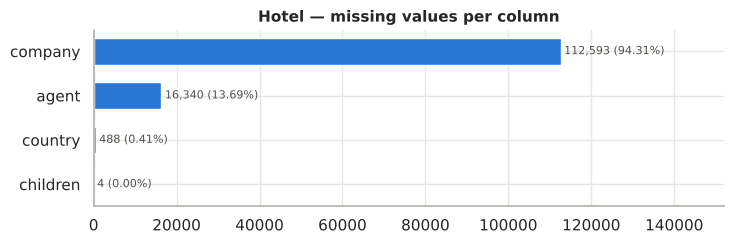

'Undefined' in meal: 1169
'Undefined' in market_segment: 2
'Undefined' in distribution_channel: 5


In [84]:
missing = hotel.isna().sum()
missing = missing[missing > 0].sort_values()
fig, ax = plt.subplots(figsize=(7.5, 2.6))
ax.barh(missing.index, missing.values, color=BLUE, height=0.6)
for i, v in enumerate(missing.values):
    ax.text(v, i, f" {v:,} ({v/len(hotel)*100:.2f}%)", va="center", fontsize=8, color=INK)
ax.set_xlim(0, missing.max() * 1.35)
ax.set_title("Hotel — missing values per column")
plt.tight_layout(); plt.show()

# Hidden missing markers
for c in ["meal", "market_segment", "distribution_channel"]:
    print(f"'Undefined' in {c}: {(hotel[c] == 'Undefined').sum()}")

In [85]:
pii_cols = ["name", "email", "phone-number", "credit_card"]
print("Fully duplicated rows (all 36 columns):", hotel.duplicated().sum())
print("Duplicated bookings ignoring personal columns:",
      hotel.drop(columns=pii_cols).duplicated().sum())

Fully duplicated rows (all 36 columns): 0
Duplicated bookings ignoring personal columns: 31994


**Observations**
- 4 columns have missing values: `company` (≈94% missing!), `agent` (≈14%), `country` (488) and `children` (4).
- Hidden missing markers: `Undefined` appears in `meal`, `market_segment` and `distribution_channel`.
- No row is an exact duplicate. Ignoring the personal columns, ≈32,000 rows have identical booking details. These are typical of **group bookings** (many identical rooms booked at once by one agent), and every one of them has a different guest name — so they are **kept as separate bookings**.
- The last 4 columns (`name`, `email`, `phone-number`, `credit_card`) are **personal / sensitive data** — they are analysed for quality and then removed.

## 3.3 Target variable — `is_canceled`

Column : is_canceled
dtype  : int64
Missing: 0 (0.00%)
Unique : 2
----------------------------------------
             count  percent
is_canceled                
0            75166    62.96
1            44224    37.04


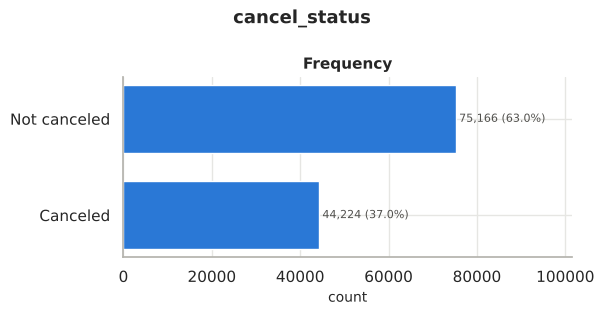

In [86]:
hotel["cancel_status"] = hotel["is_canceled"].map({0: "Not canceled", 1: "Canceled"})
profile(hotel, "is_canceled")
plot_categorical(hotel, "cancel_status")

**Observations — `is_canceled`**
- **37.0% of all bookings were canceled** (44,224 of 119,390) — a high cancellation rate and the key business problem.
- Values are only 0/1 — no cleaning needed. A text label `cancel_status` was added for clearer plots.

## 3.4 Column-by-column analysis & cleaning

### Column 1 — `hotel`

Column : hotel
dtype  : str
Missing: 0 (0.00%)
Unique : 2
----------------------------------------
              count  percent
hotel                       
City Hotel    79330    66.45
Resort Hotel  40060    33.55


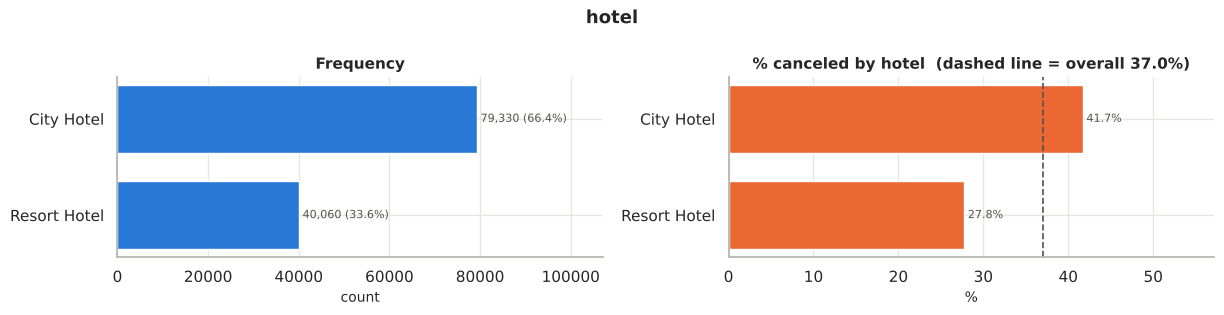

In [87]:
profile(hotel, "hotel")
plot_categorical(hotel, "hotel", target="is_canceled", pos=1, label="canceled")

**Observations — `hotel`**
- City Hotel 79,330 bookings (66%), Resort Hotel 40,060 (34%).
- City Hotel cancellations are much higher: **41.7% vs 27.8%**.

**Cleaning:** none required (two clean categories).

### Column 2 — `is_canceled`
Analysed in section 3.3 (target).

### Column 3 — `lead_time`
*(days between booking and arrival)*

Column : lead_time
dtype  : int64
Missing: 0 (0.00%)
Unique : 479
----------------------------------------
count   119,390.00
mean        104.01
std         106.86
min           0.00
25%          18.00
50%          69.00
75%         160.00
max         737.00
skewness : 1.347
kurtosis : 1.696
zeros    : 6,345 (5.31%)
IQR fences: [-195.00, 373.00] -> outliers: 3,005 (2.52%)


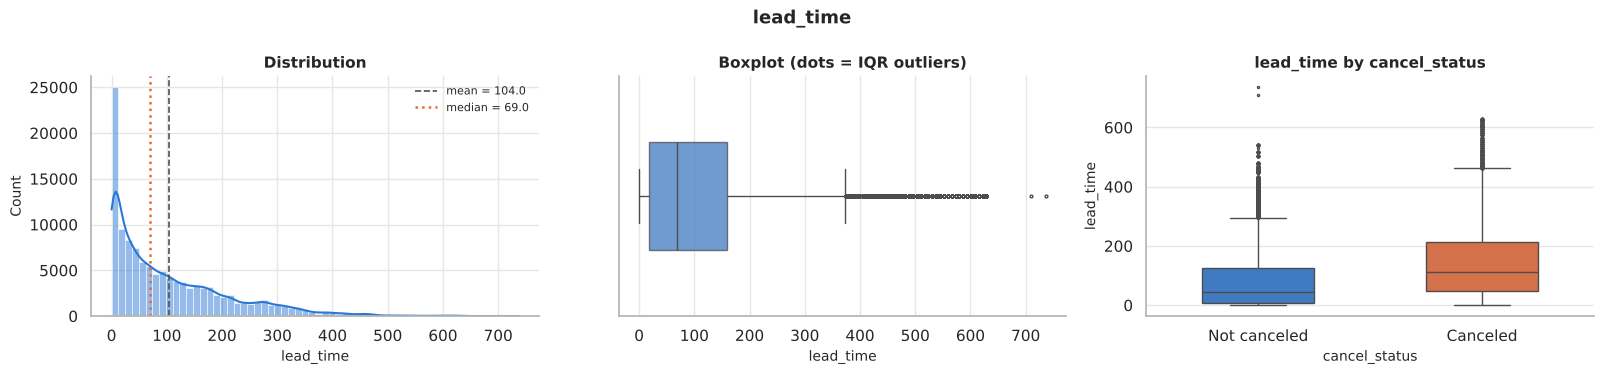

In [88]:
profile(hotel, "lead_time")
plot_numeric(hotel, "lead_time", target="cancel_status", order=["Not canceled", "Canceled"], bins=60)

**Observations — `lead_time`**
- Range 0 – 737 days; median 69, mean 104 → right-skewed (skewness ≈ 1.35).
- **Canceled bookings were made much earlier**: median lead time 113 days vs 45 for kept bookings — the longer the wait, the more likely plans change.
- ≈3,000 IQR outliers (lead time > ~373 days). Booking one to two years ahead is possible (e.g. events, groups), so they are kept.

**Cleaning:** no missing values; outliers kept; add a `lead_time_group` category.

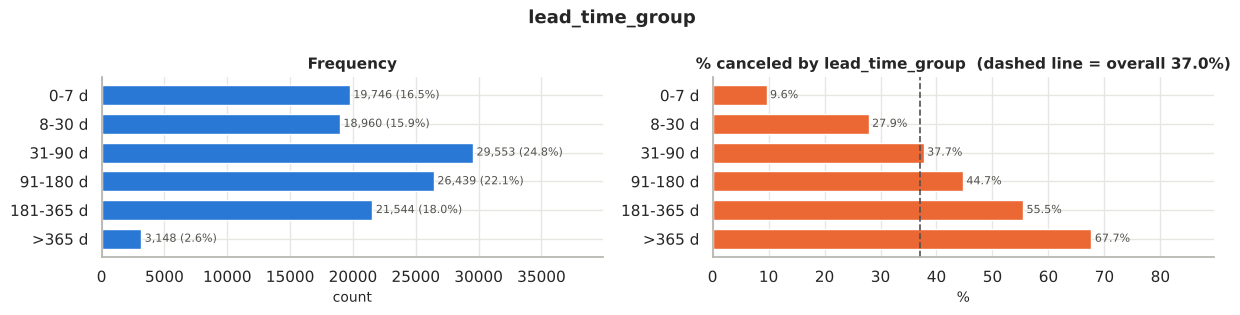

In [89]:
hotel["lead_time_group"] = pd.cut(hotel["lead_time"], bins=[-1, 7, 30, 90, 180, 365, 800],
                                  labels=["0-7 d", "8-30 d", "31-90 d", "91-180 d", "181-365 d", ">365 d"])
plot_categorical(hotel, "lead_time_group", target="is_canceled", pos=1, label="canceled")

### Column 4 — `arrival_date_year`

Column : arrival_date_year
dtype  : int64
Missing: 0 (0.00%)
Unique : 3
----------------------------------------
count   119,390.00
mean      2,016.16
std           0.71
min       2,015.00
25%       2,016.00
50%       2,016.00
75%       2,017.00
max       2,017.00
skewness : -0.233
kurtosis : -0.995
zeros    : 0 (0.00%)
IQR fences: [2,014.50, 2,018.50] -> outliers: 0 (0.00%)


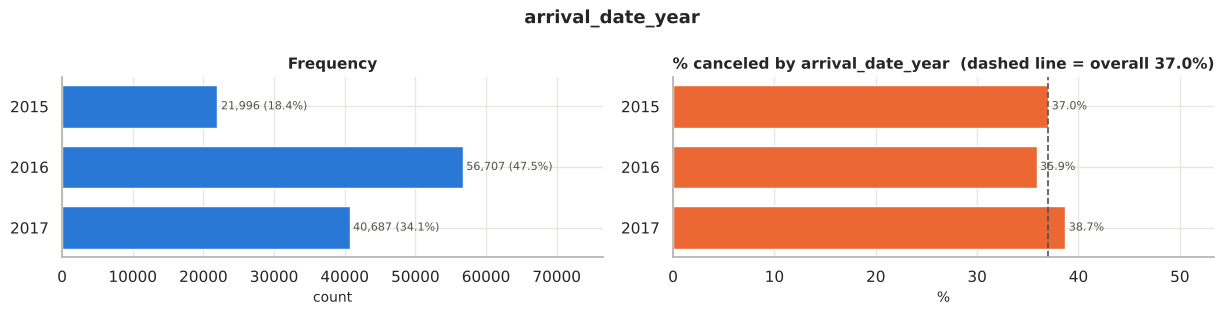

Months available per year: {2015: 6, 2016: 12, 2017: 8}


In [90]:
profile(hotel, "arrival_date_year")
plot_categorical(hotel, "arrival_date_year", target="is_canceled", pos=1, label="canceled", sort_index=True)
print("Months available per year:", hotel.groupby("arrival_date_year")["arrival_date_month"].nunique().to_dict())

**Observations — `arrival_date_year`**
- 2015: 21,996 · 2016: 56,707 · 2017: 40,687.
- **Only 2016 is a complete year** — 2015 has 6 months (Jul–Dec) and 2017 has 8 months (Jan–Aug). Year-to-year totals must therefore not be compared directly.
- Cancellation rate is stable across years (≈36–39%).

**Cleaning:** valid integers, no cleaning needed (used later to build a full arrival date).

### Column 5 — `arrival_date_month`

Column : arrival_date_month
dtype  : str
Missing: 0 (0.00%)
Unique : 12
----------------------------------------
                    count  percent
arrival_date_month                
August              13877    11.62
July                12661    10.60
May                 11791     9.88
October             11160     9.35
April               11089     9.29
June                10939     9.16
September           10508     8.80
March                9794     8.20
February             8068     6.76
November             6794     5.69
December             6780     5.68
January              5929     4.97


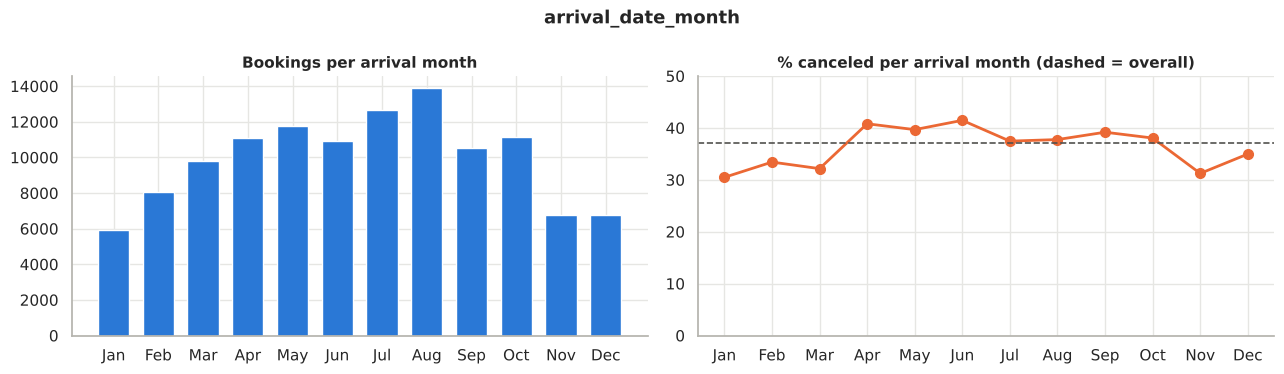

In [91]:
month_order = ["January", "February", "March", "April", "May", "June", "July",
               "August", "September", "October", "November", "December"]
profile(hotel, "arrival_date_month", top=12)

cnt = hotel["arrival_date_month"].value_counts().reindex(month_order)
rate = hotel.groupby("arrival_date_month")["is_canceled"].mean().reindex(month_order) * 100
fig, axes = plt.subplots(1, 2, figsize=(13, 3.8))
axes[0].bar([m[:3] for m in month_order], cnt.values, color=BLUE, width=0.7)
axes[0].set_title("Bookings per arrival month")
axes[1].plot([m[:3] for m in month_order], rate.values, color=ORANGE, lw=2, marker="o", ms=7)
axes[1].axhline(hotel["is_canceled"].mean() * 100, color=INK, ls="--", lw=1.2)
axes[1].set_title("% canceled per arrival month (dashed = overall)")
axes[1].set_ylim(0, 50)
fig.suptitle("arrival_date_month", fontsize=13, fontweight="bold")
plt.tight_layout(); plt.show()

**Observations — `arrival_date_month`**
- Busiest months: **August (13,877)** and July — the summer peak; January and December are quietest. (Jul–Aug are also covered by all three years, which inflates them slightly.)
- Cancellation rate is highest in spring/early summer (April–June ≈ 40–42%) and lowest in winter (≈30–33%).

**Cleaning:** text month names are converted to an ordered month number `arrival_month_num` (1–12), which can be sorted and used in date calculations.

In [92]:
hotel["arrival_month_num"] = hotel["arrival_date_month"].map({m: i + 1 for i, m in enumerate(month_order)})
print("Unmapped months:", hotel["arrival_month_num"].isna().sum())

Unmapped months: 0


### Column 6 — `arrival_date_week_number`

Column : arrival_date_week_number
dtype  : int64
Missing: 0 (0.00%)
Unique : 53
----------------------------------------
count   119,390.00
mean         27.17
std          13.61
min           1.00
25%          16.00
50%          28.00
75%          38.00
max          53.00
skewness : -0.010
kurtosis : -0.986
zeros    : 0 (0.00%)
IQR fences: [-17.00, 71.00] -> outliers: 0 (0.00%)


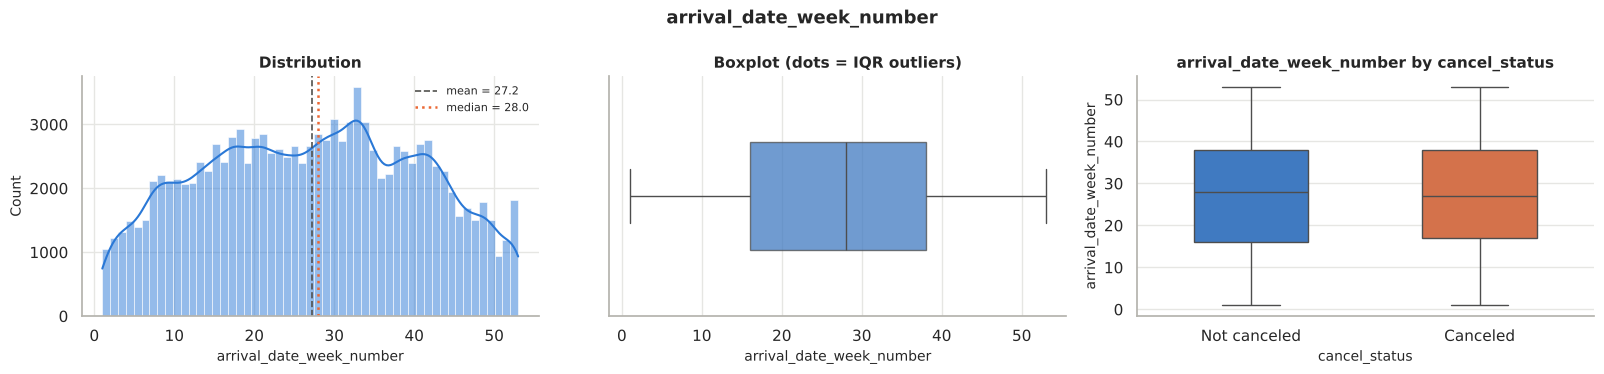

In [93]:
profile(hotel, "arrival_date_week_number")
plot_numeric(hotel, "arrival_date_week_number", target="cancel_status",
             order=["Not canceled", "Canceled"], bins=53)

**Observations — `arrival_date_week_number`**
- Weeks 1–53 (week 53 exists in some years). The histogram mirrors the monthly pattern — peak around weeks 30–35 (summer).
- Distribution is almost identical for canceled vs kept bookings — week number alone is not a driver.

**Cleaning:** none required (valid range 1–53, no missing values).

### Column 7 — `arrival_date_day_of_month`

Column : arrival_date_day_of_month
dtype  : int64
Missing: 0 (0.00%)
Unique : 31
----------------------------------------
count   119,390.00
mean         15.80
std           8.78
min           1.00
25%           8.00
50%          16.00
75%          23.00
max          31.00
skewness : -0.002
kurtosis : -1.187
zeros    : 0 (0.00%)
IQR fences: [-14.50, 45.50] -> outliers: 0 (0.00%)


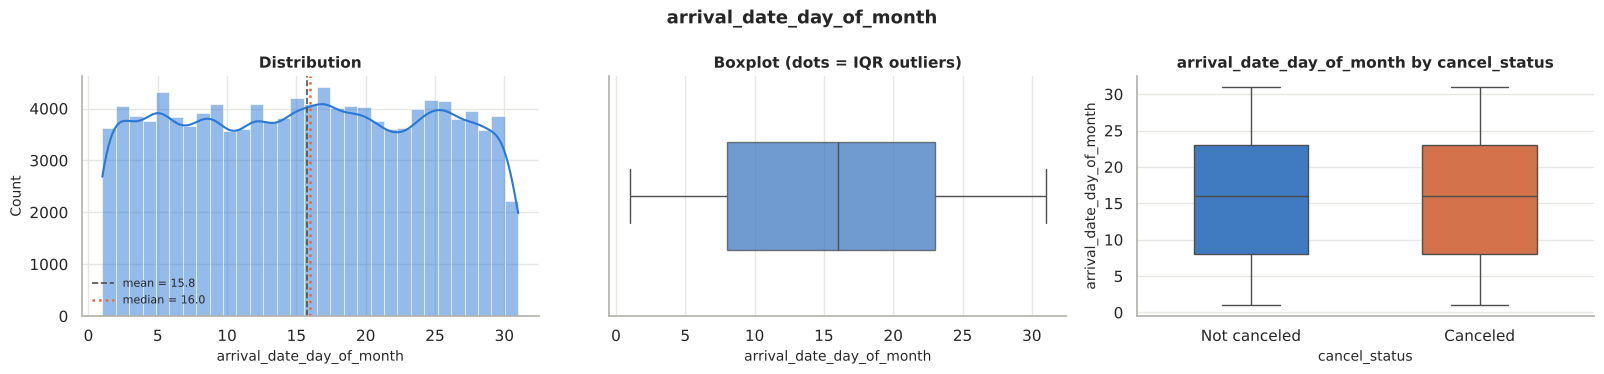

In [94]:
profile(hotel, "arrival_date_day_of_month")
plot_numeric(hotel, "arrival_date_day_of_month", target="cancel_status",
             order=["Not canceled", "Canceled"], bins=31)

**Observations — `arrival_date_day_of_month`**
- Values 1–31, roughly **uniform** (arrivals spread evenly through the month); the lower count for day 31 is natural (not every month has 31 days).
- No difference between canceled and kept bookings.

**Cleaning:** combine year + month + day into one proper **datetime column `arrival_date`** and derive the arrival weekday. The conversion itself validates the three columns (any impossible date like 31 February would fail).

Invalid dates: 0
Arrival dates from 2015-07-01 to 2017-08-31


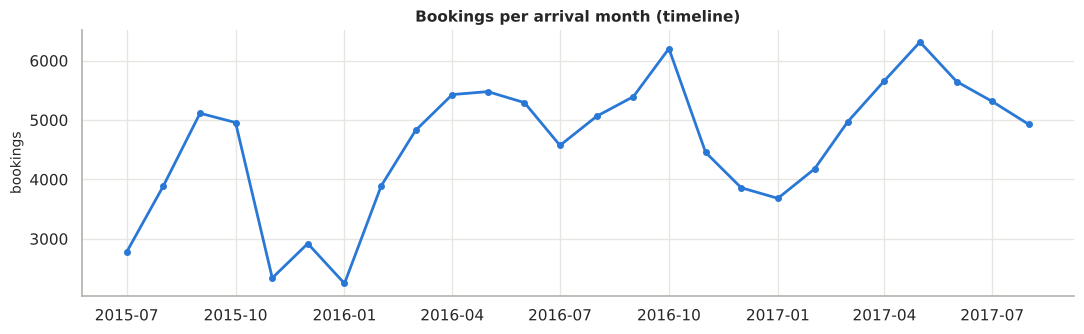

In [95]:
hotel["arrival_date"] = pd.to_datetime(dict(year=hotel["arrival_date_year"],
                                            month=hotel["arrival_month_num"],
                                            day=hotel["arrival_date_day_of_month"]))
hotel["arrival_weekday"] = hotel["arrival_date"].dt.day_name()
print("Invalid dates:", hotel["arrival_date"].isna().sum())
print("Arrival dates from", hotel["arrival_date"].min().date(), "to", hotel["arrival_date"].max().date())

daily = hotel.set_index("arrival_date").resample("MS")["hotel"].count()
fig, ax = plt.subplots(figsize=(11, 3.5))
ax.plot(daily.index, daily.values, color=BLUE, lw=2, marker="o", ms=4)
ax.set_title("Bookings per arrival month (timeline)")
ax.set_ylabel("bookings")
plt.tight_layout(); plt.show()

### Column 8 — `stays_in_weekend_nights`

Column : stays_in_weekend_nights
dtype  : int64
Missing: 0 (0.00%)
Unique : 17
----------------------------------------
count   119,390.00
mean          0.93
std           1.00
min           0.00
25%           0.00
50%           1.00
75%           2.00
max          19.00
skewness : 1.380
kurtosis : 7.174
zeros    : 51,998 (43.55%)
IQR fences: [-3.00, 5.00] -> outliers: 265 (0.22%)


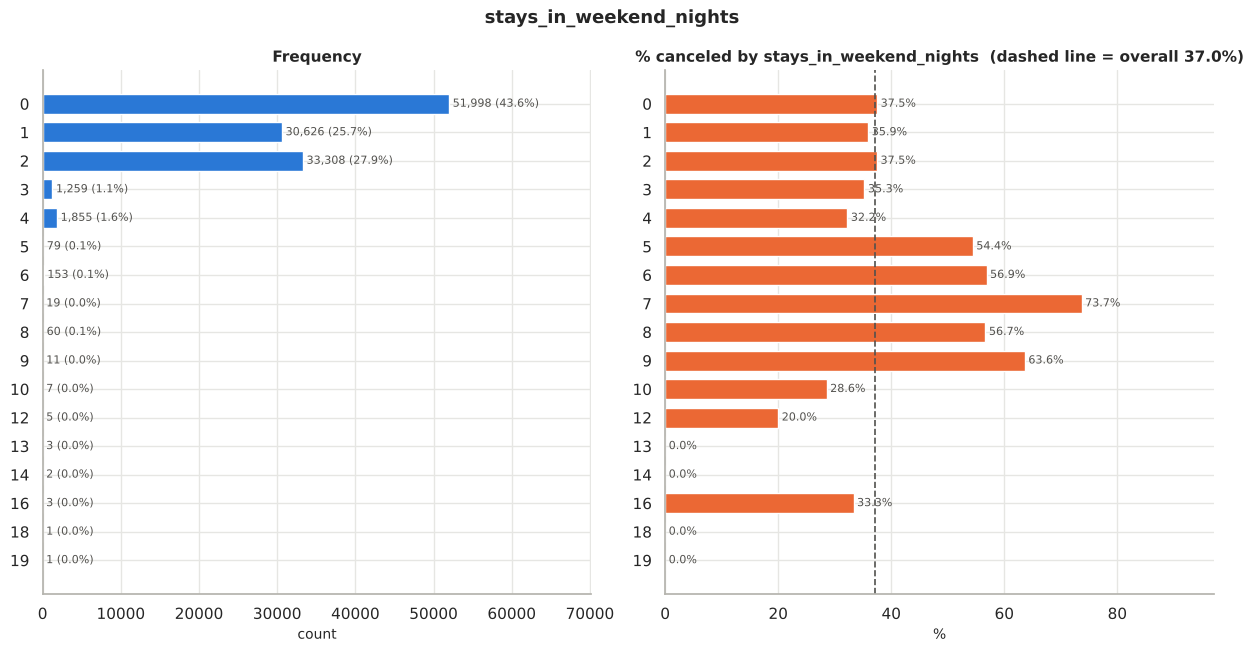

In [96]:
profile(hotel, "stays_in_weekend_nights")
plot_categorical(hotel, "stays_in_weekend_nights", target="is_canceled", pos=1, label="canceled", sort_index=True)

**Observations — `stays_in_weekend_nights`**
- 0–19 weekend nights; most bookings have 0, 1 or 2 (the typical weekend). Values above 4 are rare long stays.
- Cancellation rate does not change much with weekend nights.

**Cleaning:** no missing values; long stays are valid and kept.

### Column 9 — `stays_in_week_nights`

Column : stays_in_week_nights
dtype  : int64
Missing: 0 (0.00%)
Unique : 35
----------------------------------------
count   119,390.00
mean          2.50
std           1.91
min           0.00
25%           1.00
50%           2.00
75%           3.00
max          50.00
skewness : 2.862
kurtosis : 24.285
zeros    : 7,645 (6.40%)
IQR fences: [-2.00, 6.00] -> outliers: 3,354 (2.81%)


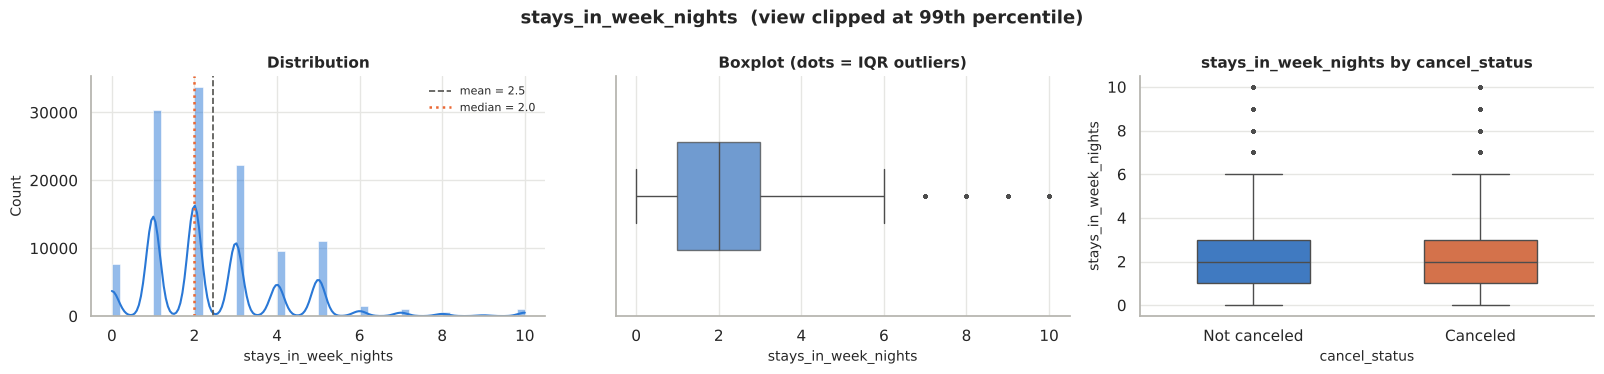

In [97]:
profile(hotel, "stays_in_week_nights")
plot_numeric(hotel, "stays_in_week_nights", target="cancel_status",
             order=["Not canceled", "Canceled"], bins=50, clip_q=0.99)

**Observations — `stays_in_week_nights`**
- 0–50 weeknights; median 2. Skewed (≈2.9) by a few long stays (the plot is zoomed to the 99th percentile for readability).
- Similar distributions for canceled and kept bookings.

**Cleaning:** create `total_nights` = weekend + weeknights, and check bookings with 0 nights.

Bookings with 0 nights: 715 | of these canceled: 4.9%


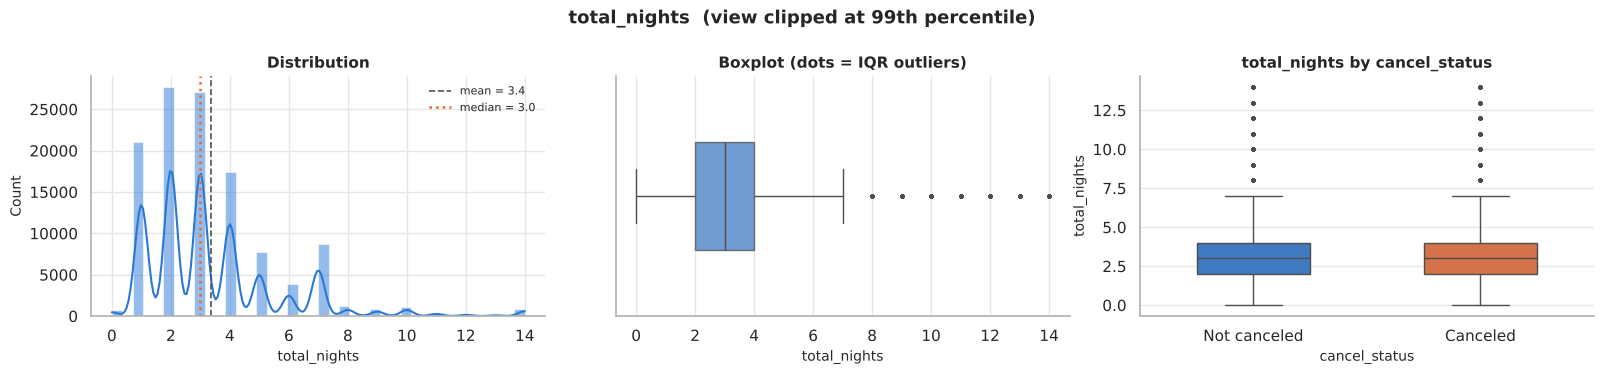

In [98]:
hotel["total_nights"] = hotel["stays_in_weekend_nights"] + hotel["stays_in_week_nights"]
zero_n = (hotel["total_nights"] == 0)
print(f"Bookings with 0 nights: {zero_n.sum():,} | of these canceled: {hotel.loc[zero_n, 'is_canceled'].mean()*100:.1f}%")
plot_numeric(hotel, "total_nights", target="cancel_status",
             order=["Not canceled", "Canceled"], bins=40, clip_q=0.99)

`total_nights` median is 3. The **715 zero-night bookings** are almost never canceled (≈5%) — they look like **day-use rooms** (check-in and check-out on the same day), so they are kept and flagged rather than deleted.

In [99]:
hotel["is_day_use"] = zero_n.astype(int)

### Column 10 — `adults`

Column : adults
dtype  : int64
Missing: 0 (0.00%)
Unique : 14
----------------------------------------
count   119,390.00
mean          1.86
std           0.58
min           0.00
25%           2.00
50%           2.00
75%           2.00
max          55.00
skewness : 18.318
kurtosis : 1352.115
zeros    : 403 (0.34%)
IQR fences: [2.00, 2.00] -> outliers: 29,710 (24.88%)


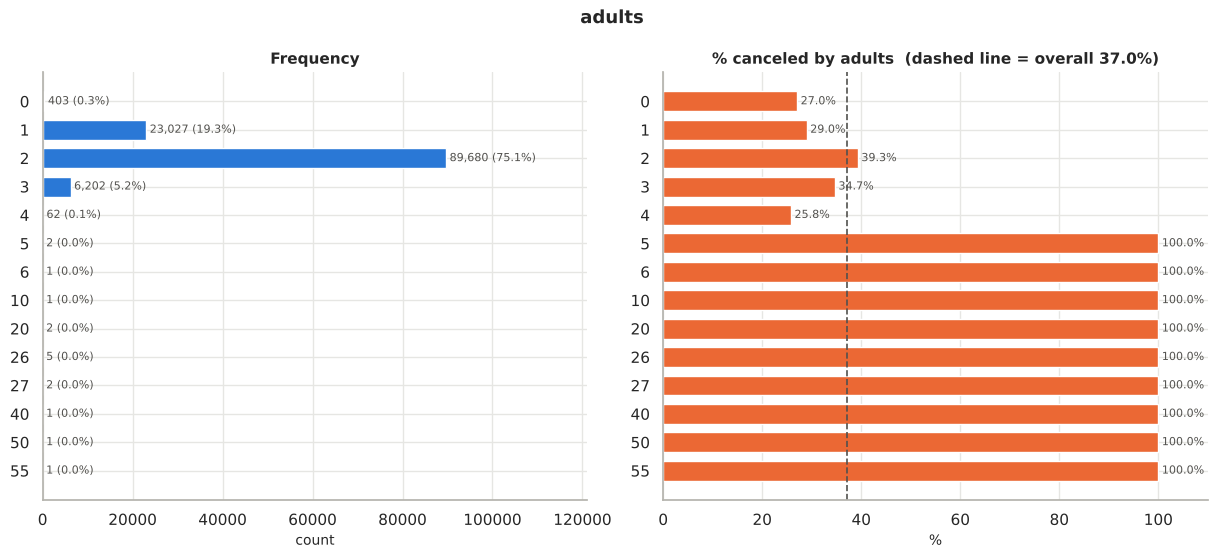

In [100]:
profile(hotel, "adults")
plot_categorical(hotel, "adults", target="is_canceled", pos=1, label="canceled", sort_index=True)

**Observations — `adults`**
- Most bookings are for **2 adults (≈75%)** or 1 adult.
- Values from 5 up to 55 adults in one booking are extreme (group bookings entered as one row).
- **403 bookings have 0 adults** — 223 of them contain only children/babies, and the rest have no guests at all (handled after `babies`).

**Cleaning:** valid integers; extreme group sizes kept. Zero-guest rows are removed in a combined check below.

### Column 11 — `children`

Column : children
dtype  : float64
Missing: 4 (0.00%)
Unique : 5
----------------------------------------
count   119,386.00
mean          0.10
std           0.40
min           0.00
25%           0.00
50%           0.00
75%           0.00
max          10.00
skewness : 4.113
kurtosis : 18.674
zeros    : 110,796 (92.80%)
IQR fences: [0.00, 0.00] -> outliers: 8,590 (7.19%)


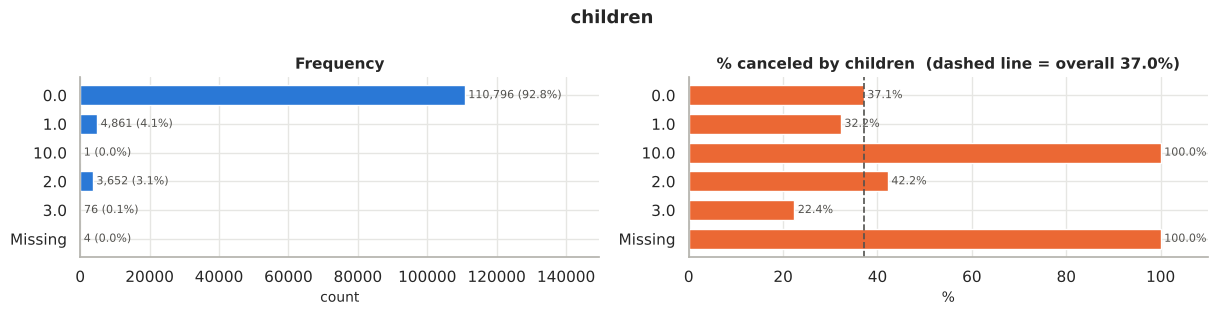

In [101]:
profile(hotel, "children")
plot_categorical(hotel, "children", target="is_canceled", pos=1, label="canceled", sort_index=True)

**Observations — `children`**
- ≈93% of bookings have no children. 4 values are missing; stored as float because of these NaNs.
- One booking has **10 children with 2 adults** — clearly a data-entry error (next highest value is 3).

**Cleaning:** fill the 4 missing values with 0 (most common value), remove the impossible 10-children row, and convert to integer.

In [102]:
hotel["children"] = hotel["children"].fillna(0)
before = len(hotel)
hotel = hotel[hotel["children"] < 10].copy()
hotel["children"] = hotel["children"].astype(int)
print(f"Rows removed: {before - len(hotel)} | missing now: {hotel['children'].isna().sum()} | dtype: {hotel['children'].dtype}")

Rows removed: 1 | missing now: 0 | dtype: int64


### Column 12 — `babies`

Column : babies
dtype  : int64
Missing: 0 (0.00%)
Unique : 5
----------------------------------------
count   119,389.00
mean          0.01
std           0.10
min           0.00
25%           0.00
50%           0.00
75%           0.00
max          10.00
skewness : 24.646
kurtosis : 1633.935
zeros    : 118,472 (99.23%)
IQR fences: [0.00, 0.00] -> outliers: 917 (0.77%)


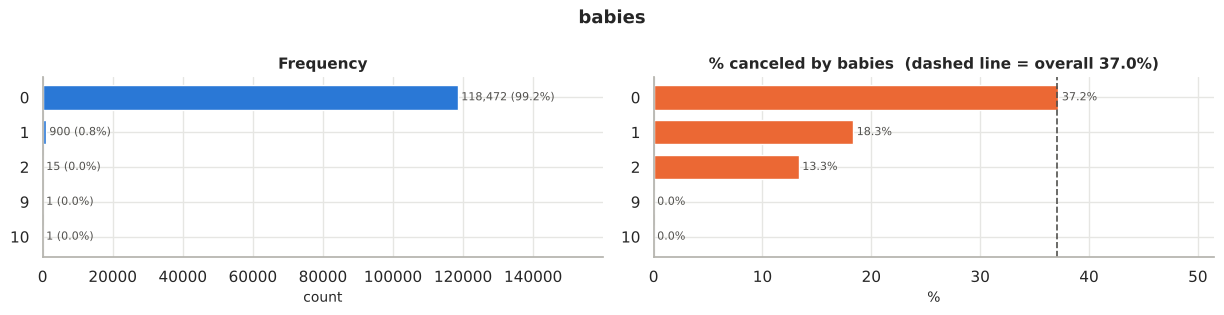

In [103]:
profile(hotel, "babies")
plot_categorical(hotel, "babies", target="is_canceled", pos=1, label="canceled", sort_index=True)

**Observations — `babies`**
- 99.2% of bookings have no babies; 1–2 babies are normal.
- Two rows have **9 and 10 babies** with only 1–2 adults — data-entry errors.
- Bookings with babies cancel less (≈18% vs 37%).

**Cleaning:** remove the 2 impossible rows. Then build `total_guests` and remove bookings with **0 guests** (no adults, children or babies), which cannot be real stays.

In [104]:
before = len(hotel)
hotel = hotel[hotel["babies"] < 9].copy()
print("Rows removed (babies >= 9):", before - len(hotel))

hotel["total_guests"] = hotel["adults"] + hotel["children"] + hotel["babies"]
before = len(hotel)
hotel = hotel[hotel["total_guests"] > 0].copy()
print("Rows removed (0 guests):", before - len(hotel))
print("Shape now:", hotel.shape)

Rows removed (babies >= 9): 2
Rows removed (0 guests): 180
Shape now: (119207, 44)


### Column 13 — `meal`

Column : meal
dtype  : str
Missing: 0 (0.00%)
Unique : 5
----------------------------------------
           count  percent
meal                     
BB         92233    77.37
HB         14458    12.13
SC         10549     8.85
Undefined   1169     0.98
FB           798     0.67


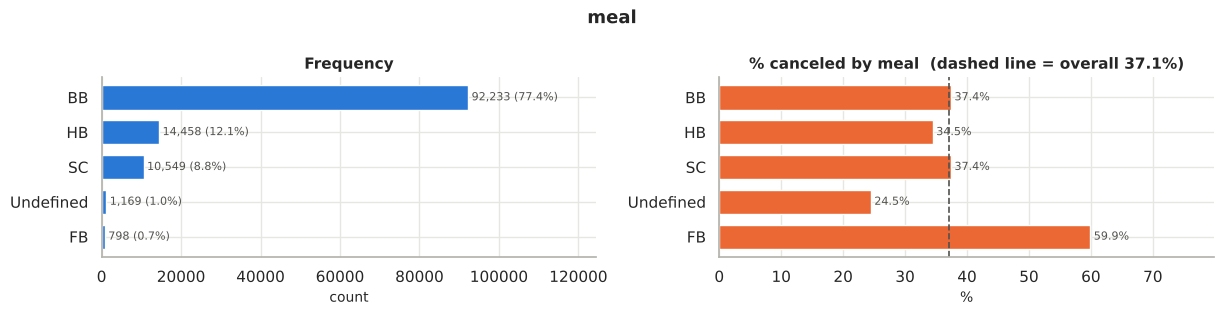

In [105]:
profile(hotel, "meal")
plot_categorical(hotel, "meal", target="is_canceled", pos=1, label="canceled")

**Observations — `meal`**
- `BB` (Bed & Breakfast) dominates (≈77%), followed by `HB` (Half Board) and `SC` (Self Catering, no meal).
- `Undefined` (1,169 rows): according to the dataset documentation, *Undefined* and *SC* both mean **no meal package**.
- `FB` (Full Board) has an unusually high cancellation rate (≈60%).

**Cleaning:** merge `Undefined` into `SC`.

In [106]:
hotel["meal"] = hotel["meal"].replace("Undefined", "SC")
hotel["meal"].value_counts()

meal
BB    92233
HB    14458
SC    11718
FB      798
Name: count, dtype: int64

### Column 14 — `country`

Column : country
dtype  : str
Missing: 478 (0.40%)
Unique : 177
----------------------------------------
         count  percent
country                
PRT      48481    40.67
GBR      12119    10.17
FRA      10401     8.73
ESP       8560     7.18
DEU       7285     6.11
ITA       3761     3.16
IRL       3374     2.83
BEL       2342     1.96
BRA       2222     1.86
NLD       2103     1.76
... 168 more categories


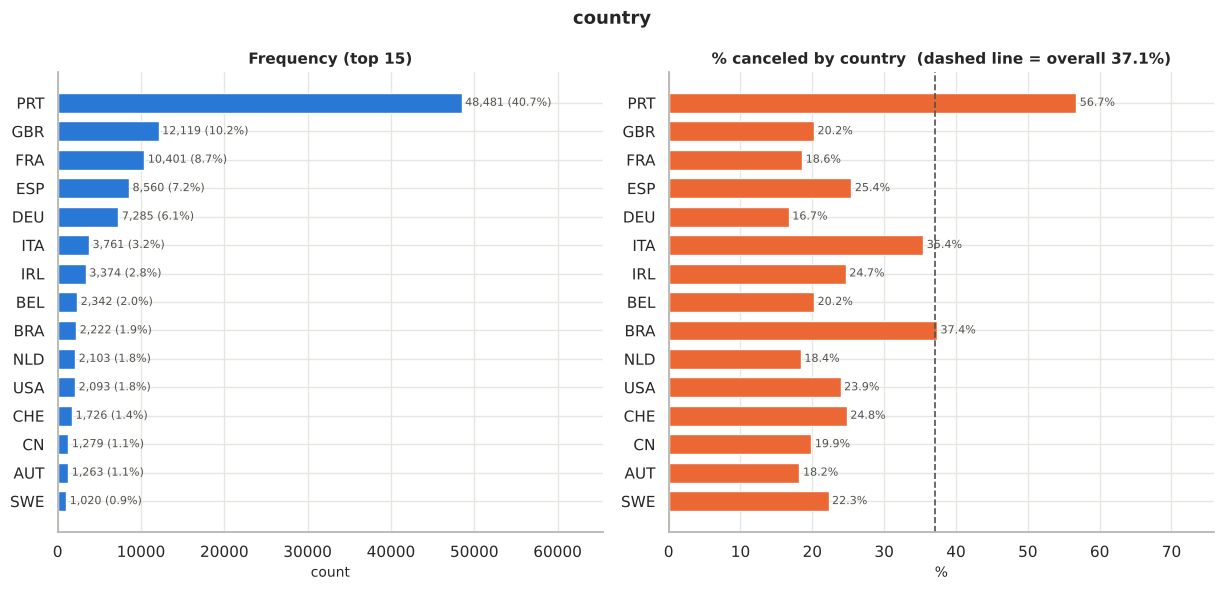

Rows with code 'CN': 1279 | rows with 'CHN': 999


In [107]:
profile(hotel, "country", top=10)
plot_categorical(hotel, "country", target="is_canceled", pos=1, label="canceled", top=15)
print("Rows with code 'CN':", (hotel["country"] == "CN").sum(), "| rows with 'CHN':", (hotel["country"] == "CHN").sum())

**Observations — `country`**
- 177 countries (ISO-3 codes). **Portugal (PRT) ≈ 41%** of bookings — the hotels are in Portugal — followed by GBR, FRA, ESP, DEU.
- Domestic (PRT) bookings cancel far more (≈57%) than foreign ones (≈16–25% for GBR/FRA/DEU).
- 488 missing values (0.4%).
- **Inconsistent coding:** China appears both as `CHN` (ISO-3) and `CN` (ISO-2).

**Cleaning:** fill missing with `Unknown`, unify `CN` → `CHN`, and add `is_domestic` (PRT = 1).

In [108]:
hotel["country"] = hotel["country"].fillna("Unknown").replace("CN", "CHN")
hotel["is_domestic"] = (hotel["country"] == "PRT").astype(int)
print("Missing:", hotel["country"].isna().sum(), "| 'CN' left:", (hotel["country"] == "CN").sum())

Missing: 0 | 'CN' left: 0


### Column 15 — `market_segment`

Column : market_segment
dtype  : str
Missing: 0 (0.00%)
Unique : 8
----------------------------------------
                count  percent
market_segment                
Online TA       56407    47.32
Offline TA/TO   24181    20.28
Groups          19791    16.60
Direct          12582    10.55
Corporate        5281     4.43
Complementary     728     0.61
Aviation          235     0.20
Undefined           2     0.00


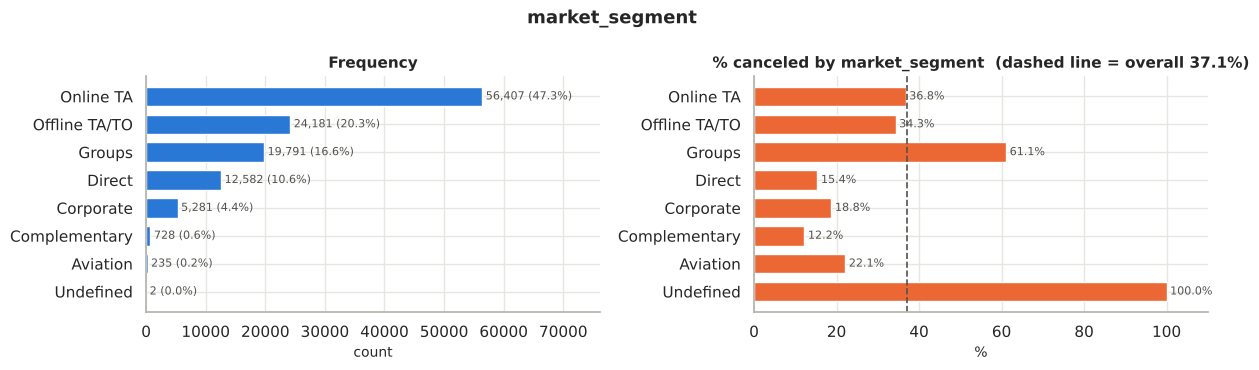

In [109]:
profile(hotel, "market_segment")
plot_categorical(hotel, "market_segment", target="is_canceled", pos=1, label="canceled")

**Observations — `market_segment`**
- `Online TA` (online travel agents) ≈ 47% of bookings, then `Offline TA/TO` and `Groups`.
- **Groups cancel the most (≈61%)**; Direct (≈15%) and Corporate (≈19%) bookings are the most reliable.
- `Undefined`: only 2 rows.

**Cleaning:** replace `Undefined` with the mode (`Online TA`).

In [110]:
mode_ms = hotel.loc[hotel["market_segment"] != "Undefined", "market_segment"].mode()[0]
hotel["market_segment"] = hotel["market_segment"].replace("Undefined", mode_ms)
print("Replaced with:", mode_ms, "| Undefined left:", (hotel["market_segment"] == "Undefined").sum())

Replaced with: Online TA | Undefined left: 0


### Column 16 — `distribution_channel`

Column : distribution_channel
dtype  : str
Missing: 0 (0.00%)
Unique : 5
----------------------------------------
                      count  percent
distribution_channel                
TA/TO                 97748    82.00
Direct                14611    12.26
Corporate              6650     5.58
GDS                     193     0.16
Undefined                 5     0.00


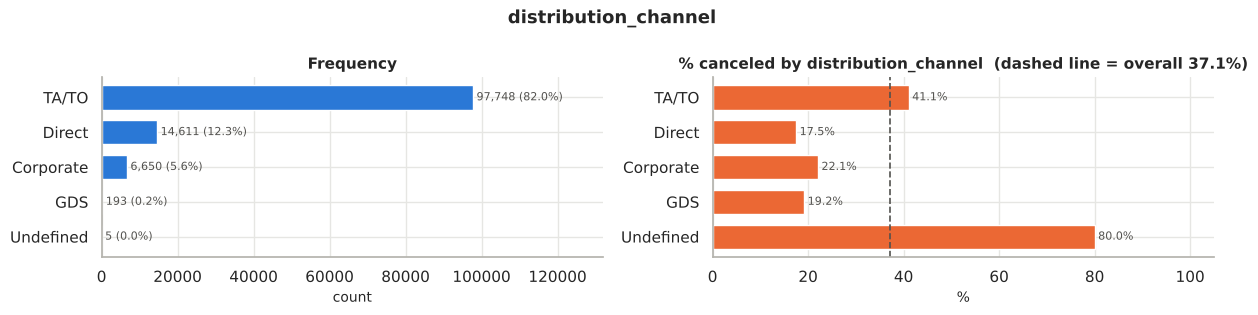

In [111]:
profile(hotel, "distribution_channel")
plot_categorical(hotel, "distribution_channel", target="is_canceled", pos=1, label="canceled")

**Observations — `distribution_channel`**
- `TA/TO` (travel agents / tour operators) ≈ 82% of bookings, with the highest cancellation rate (≈41%).
- Direct (≈17.5%) and Corporate (≈22%) channels cancel much less.
- `Undefined`: 5 rows.

**Cleaning:** replace `Undefined` with the mode (`TA/TO`).

In [112]:
mode_dc = hotel.loc[hotel["distribution_channel"] != "Undefined", "distribution_channel"].mode()[0]
hotel["distribution_channel"] = hotel["distribution_channel"].replace("Undefined", mode_dc)
print("Replaced with:", mode_dc, "| Undefined left:", (hotel["distribution_channel"] == "Undefined").sum())

Replaced with: TA/TO | Undefined left: 0


### Column 17 — `is_repeated_guest`

Column : is_repeated_guest
dtype  : int64
Missing: 0 (0.00%)
Unique : 2
----------------------------------------
                    count  percent
is_repeated_guest                 
0                  115452    96.85
1                    3755     3.15


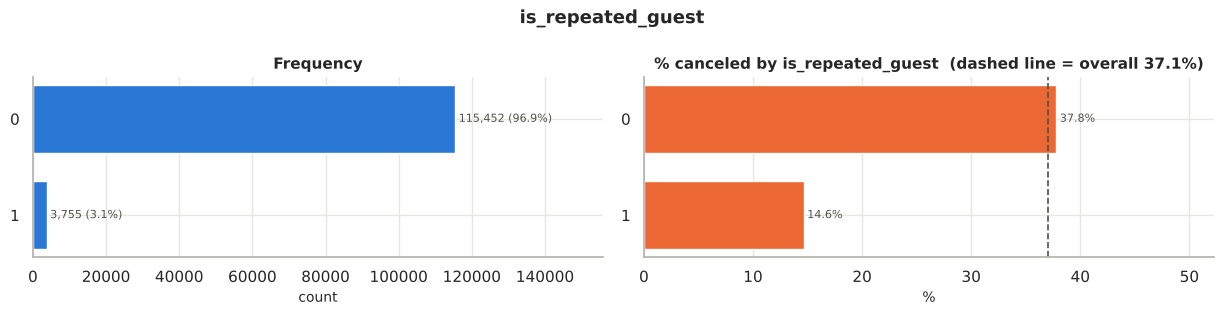

In [113]:
profile(hotel, "is_repeated_guest")
plot_categorical(hotel, "is_repeated_guest", target="is_canceled", pos=1, label="canceled")

**Observations — `is_repeated_guest`**
- Only ≈3% of bookings are from returning guests.
- **Repeat guests cancel far less** (≈14.5% vs ≈38%) — loyalty matters.

**Cleaning:** binary 0/1, no cleaning required.

### Column 18 — `previous_cancellations`

Column : previous_cancellations
dtype  : int64
Missing: 0 (0.00%)
Unique : 15
----------------------------------------
count   119,207.00
mean          0.09
std           0.84
min           0.00
25%           0.00
50%           0.00
75%           0.00
max          26.00
skewness : 24.444
kurtosis : 673.204
zeros    : 112,728 (94.56%)
IQR fences: [0.00, 0.00] -> outliers: 6,479 (5.44%)


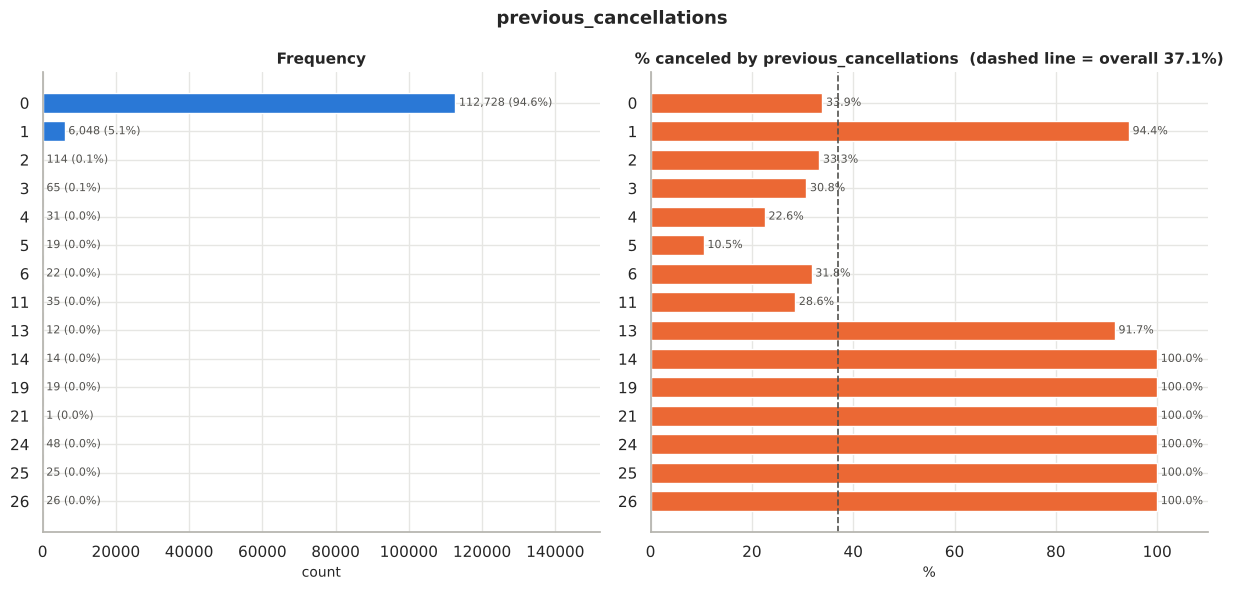

In [114]:
profile(hotel, "previous_cancellations")
plot_categorical(hotel, "previous_cancellations", target="is_canceled", pos=1, label="canceled", sort_index=True)

**Observations — `previous_cancellations`**
- ≈95% of customers have never canceled before (value 0); max is 26.
- Customers with **any** previous cancellation cancel again ≈92% of the time — a very strong signal.

**Cleaning:** no missing values; add binary flag `has_prev_cancel`.

In [115]:
hotel["has_prev_cancel"] = (hotel["previous_cancellations"] > 0).astype(int)
hotel.groupby("has_prev_cancel")["is_canceled"].mean().mul(100).round(1)

has_prev_cancel
0   33.90
1   91.70
Name: is_canceled, dtype: float64

### Column 19 — `previous_bookings_not_canceled`

Column : previous_bookings_not_canceled
dtype  : int64
Missing: 0 (0.00%)
Unique : 73
----------------------------------------
count   119,207.00
mean          0.14
std           1.50
min           0.00
25%           0.00
50%           0.00
75%           0.00
max          72.00
skewness : 23.539
kurtosis : 766.934
zeros    : 115,594 (96.97%)
IQR fences: [0.00, 0.00] -> outliers: 3,613 (3.03%)


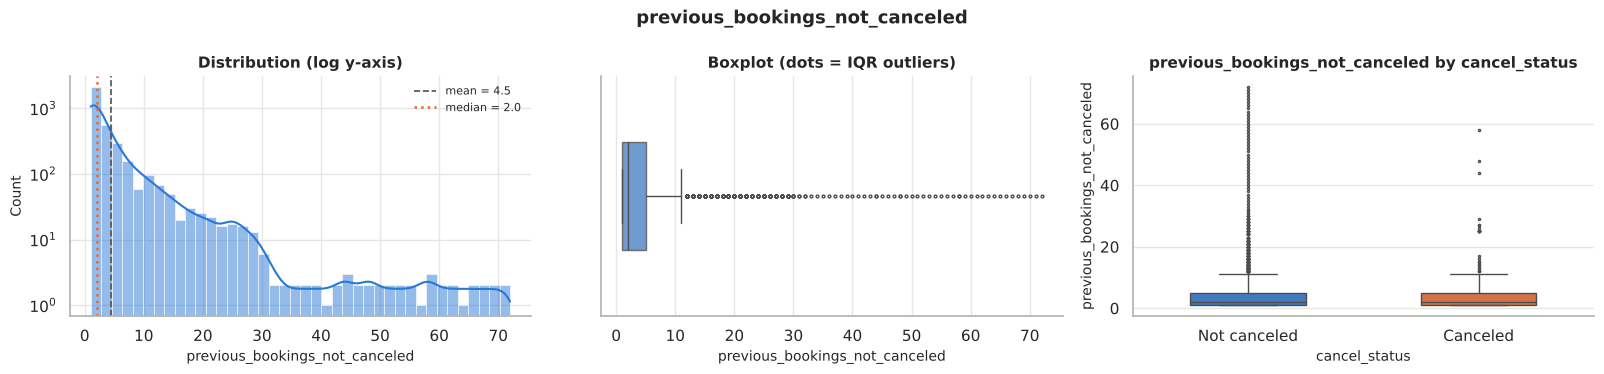

Plots show only non-zero values (≈97% of rows are 0).


In [116]:
profile(hotel, "previous_bookings_not_canceled")
plot_numeric(hotel[hotel["previous_bookings_not_canceled"] > 0], "previous_bookings_not_canceled",
             target="cancel_status", order=["Not canceled", "Canceled"], bins=40, logy=True)
print("Plots show only non-zero values (≈97% of rows are 0).")

**Observations — `previous_bookings_not_canceled`**
- ≈97% zeros, max 72 (frequent corporate customers).
- Customers with earlier completed stays cancel only ≈5.5% of the time vs ≈38% for others.

**Cleaning:** no missing values; add flag `has_prev_stay`.

In [117]:
hotel["has_prev_stay"] = (hotel["previous_bookings_not_canceled"] > 0).astype(int)
hotel.groupby("has_prev_stay")["is_canceled"].mean().mul(100).round(1)

has_prev_stay
0   38.10
1    5.50
Name: is_canceled, dtype: float64

### Column 20 — `reserved_room_type`

Column : reserved_room_type
dtype  : str
Missing: 0 (0.00%)
Unique : 9
----------------------------------------
                    count  percent
reserved_room_type                
A                   85872    72.04
D                   19177    16.09
E                    6519     5.47
F                    2894     2.43
G                    2092     1.75
B                    1115     0.94
C                     931     0.78
H                     601     0.50
L                       6     0.01


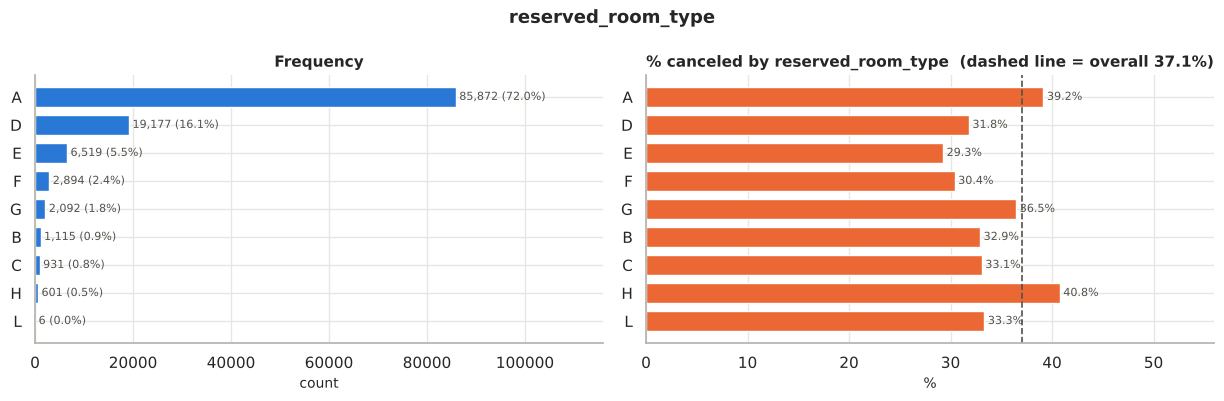

In [118]:
profile(hotel, "reserved_room_type")
plot_categorical(hotel, "reserved_room_type", target="is_canceled", pos=1, label="canceled")

**Observations — `reserved_room_type`**
- Room codes are anonymised (A–L, P). **Type A ≈ 72%** of reservations, then D and E.
- Room type `P` (12 rows) has a 100% cancellation rate; it is too small to matter.

**Cleaning:** strip whitespace (check). No missing values.

In [119]:
hotel["reserved_room_type"] = hotel["reserved_room_type"].str.strip()
sorted(hotel["reserved_room_type"].unique())

['A', 'B', 'C', 'D', 'E', 'F', 'G', 'H', 'L']

### Column 21 — `assigned_room_type`

Column : assigned_room_type
dtype  : str
Missing: 0 (0.00%)
Unique : 11
----------------------------------------
                    count  percent
assigned_room_type                
A                   74020    62.09
D                   25307    21.23
E                    7798     6.54
F                    3751     3.15
G                    2549     2.14
C                    2370     1.99
B                    2153     1.81
H                     712     0.60
I                     359     0.30
K                     187     0.16
L                       1     0.00


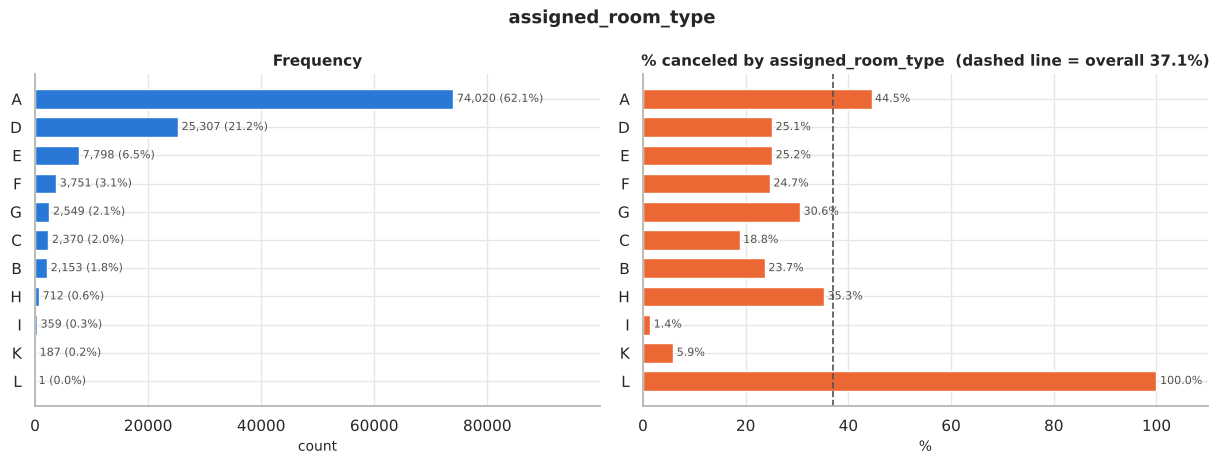

In [120]:
profile(hotel, "assigned_room_type")
plot_categorical(hotel, "assigned_room_type", target="is_canceled", pos=1, label="canceled")

Bookings where assigned room ≠ reserved room: 12.4%


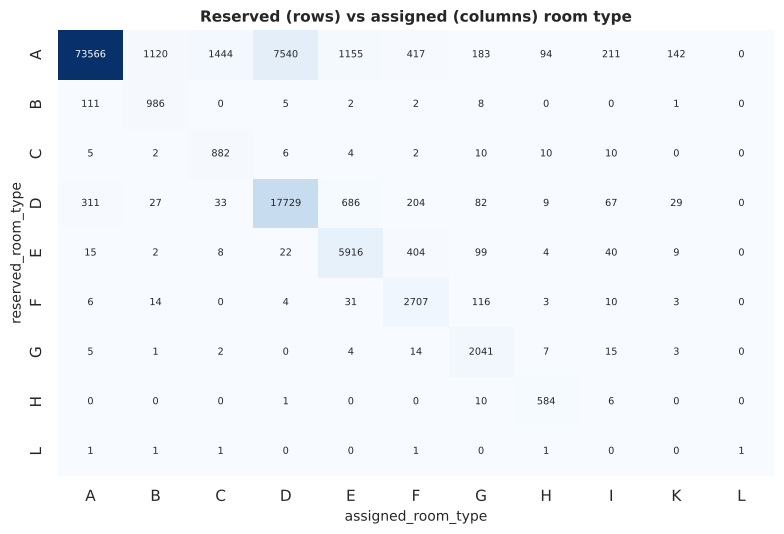

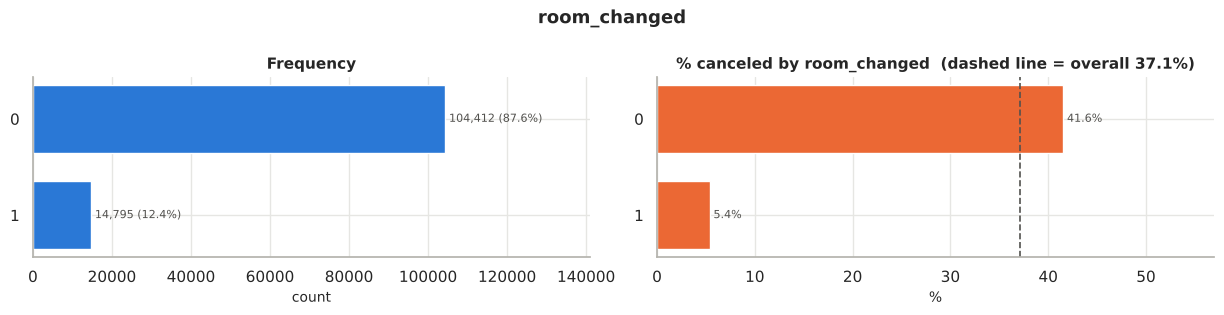

In [121]:
hotel["room_changed"] = (hotel["reserved_room_type"] != hotel["assigned_room_type"]).astype(int)
print(f"Bookings where assigned room ≠ reserved room: {hotel['room_changed'].mean()*100:.1f}%")
ct = pd.crosstab(hotel["reserved_room_type"], hotel["assigned_room_type"])
plt.figure(figsize=(8, 5.5))
sns.heatmap(ct, annot=True, fmt="d", cmap="Blues", cbar=False, annot_kws={"size": 7})
plt.title("Reserved (rows) vs assigned (columns) room type")
plt.tight_layout(); plt.show()
plot_categorical(hotel, "room_changed", target="is_canceled", pos=1, label="canceled")

**Observations — `assigned_room_type`**
- 12 types (two more than reserved: I and K exist only as assigned rooms).
- ≈12.4% of guests got a different room than they reserved (mostly upgrades — off-diagonal cells).
- Bookings with a changed room show a very low cancellation rate (≈5%), but this is **because rooms are assigned at check-in** — canceled guests never arrive, so they rarely get a different room. This is a *leakage* effect, not a cause.

**Cleaning:** no missing values; `room_changed` flag added.

### Column 22 — `booking_changes`

Column : booking_changes
dtype  : int64
Missing: 0 (0.00%)
Unique : 19
----------------------------------------
count   119,207.00
mean          0.22
std           0.64
min           0.00
25%           0.00
50%           0.00
75%           0.00
max          18.00
skewness : 5.501
kurtosis : 63.449
zeros    : 101,232 (84.92%)
IQR fences: [0.00, 0.00] -> outliers: 17,975 (15.08%)


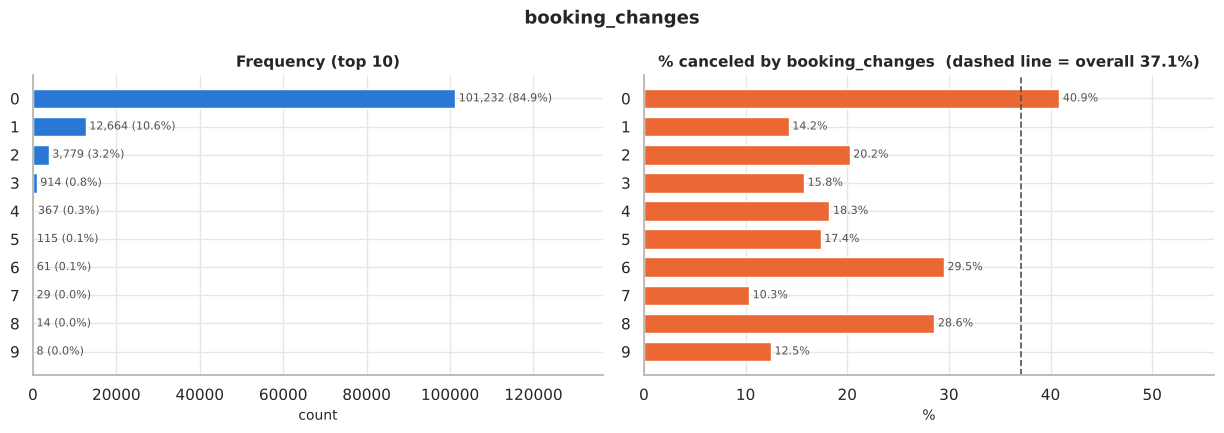

In [122]:
profile(hotel, "booking_changes")
plot_categorical(hotel, "booking_changes", target="is_canceled", pos=1, label="canceled", sort_index=True, top=10)

**Observations — `booking_changes`**
- ≈85% of bookings were never modified; max 21 changes.
- Bookings with at least one change cancel much less (≈16% vs ≈41%) — engaged customers who adjust plans usually come.

**Cleaning:** no missing values; values kept.

### Column 23 — `deposit_type`

Column : deposit_type
dtype  : str
Missing: 0 (0.00%)
Unique : 3
----------------------------------------
               count  percent
deposit_type                 
No Deposit    104458    87.63
Non Refund     14587    12.24
Refundable       162     0.14


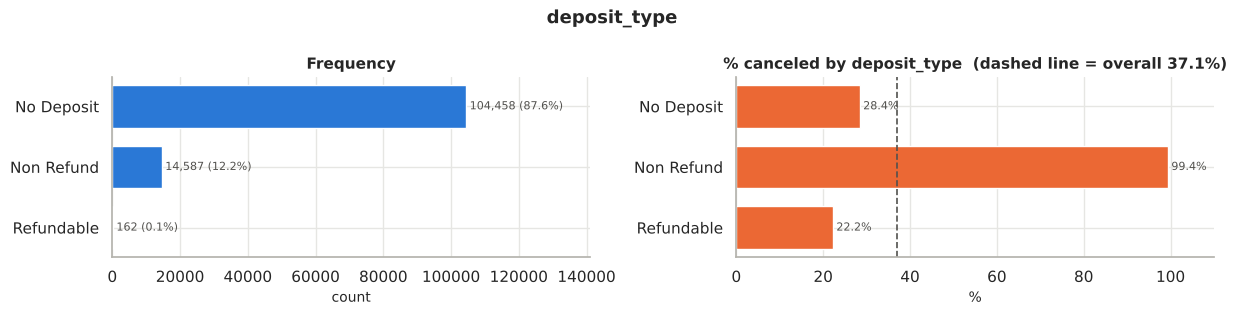

In [123]:
profile(hotel, "deposit_type")
plot_categorical(hotel, "deposit_type", target="is_canceled", pos=1, label="canceled")

**Observations — `deposit_type`**
- `No Deposit` ≈ 88%, `Non Refund` ≈ 12%, `Refundable` only 162 rows.
- **Surprising:** `Non Refund` bookings are canceled **≈99%** of the time. One would expect the opposite; this is a known quirk of this dataset (these are mostly large group / agent bookings from Portugal that were canceled in bulk). Worth flagging as a data-quality concern.

**Cleaning:** no missing values — none required.

### Column 24 — `agent`

Column : agent
dtype  : float64
Missing: 16,280 (13.66%)
Unique : 333
----------------------------------------
count   102,927.00
mean         86.74
std         110.79
min           1.00
25%           9.00
50%          14.00
75%         229.00
max         535.00
skewness : 1.088


kurtosis : -0.011
zeros    : 0 (0.00%)
IQR fences: [-321.00, 559.00] -> outliers: 0 (0.00%)


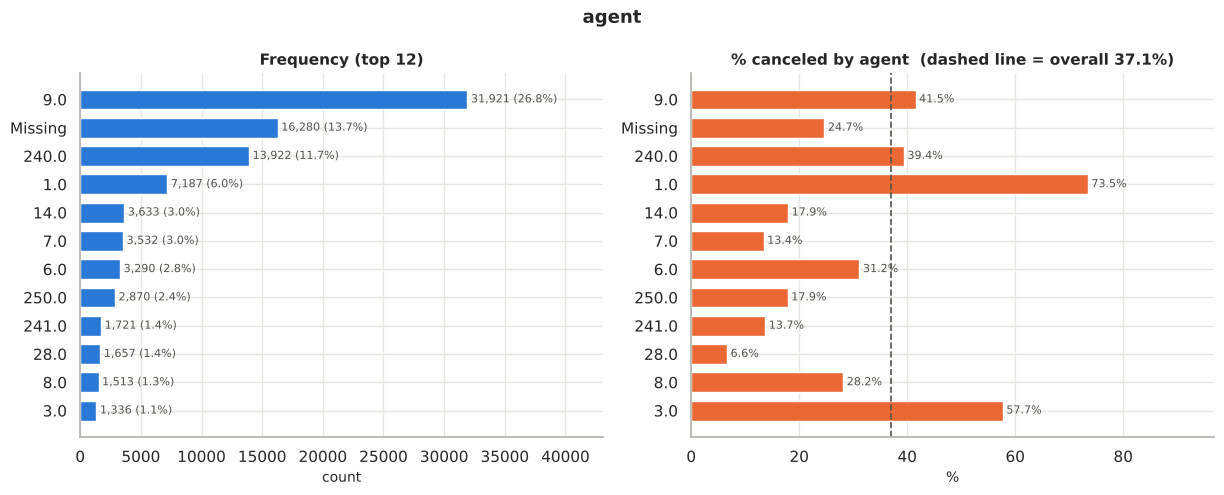

In [124]:
profile(hotel, "agent", top=10)
plot_categorical(hotel, "agent", target="is_canceled", pos=1, label="canceled", top=12)

**Observations — `agent`**
- `agent` is an **ID code**, not a quantity — its mean/std have no meaning. 333 different agents.
- Agent **9** alone handles ≈27% of all bookings, agent 240 ≈12%.
- ≈16,340 missing values (≈13.7%) — meaning the booking was made **without an agent** (direct). Those bookings cancel less (≈25% vs 39%).

**Cleaning:** fill missing with 0 (= "no agent"), convert to integer, and add `has_agent` flag.

In [125]:
hotel["has_agent"] = hotel["agent"].notna().astype(int)
hotel["agent"] = hotel["agent"].fillna(0).astype(int)
print("Missing after cleaning:", hotel["agent"].isna().sum(), "| dtype:", hotel["agent"].dtype)

Missing after cleaning: 0 | dtype: int64


### Column 25 — `company`

Column : company
dtype  : float64
Missing: 112,439 (94.32%)
Unique : 348
----------------------------------------
count   6,768.00
mean      189.09
std       131.59
min         6.00
25%        62.00
50%       178.00
75%       270.00
max       543.00
skewness : 0.603
kurtosis : -0.490
zeros    : 0 (0.00%)
IQR fences: [-250.00, 582.00] -> outliers: 0 (0.00%)


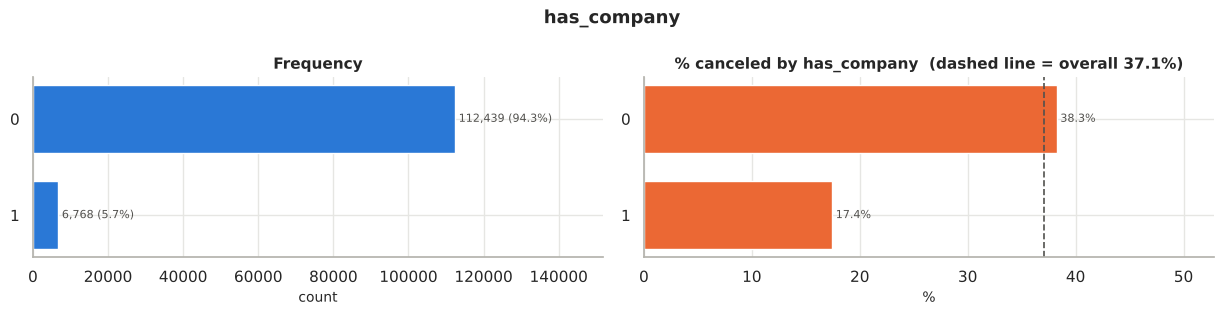

In [126]:
profile(hotel, "company", top=10)
hotel["has_company"] = hotel["company"].notna().astype(int)
plot_categorical(hotel, "has_company", target="is_canceled", pos=1, label="canceled")

**Observations — `company`**
- **≈94% missing** — only ≈6,800 bookings were paid by a company. Like `agent`, it is an ID code.
- With so many gaps the column cannot be imputed meaningfully; however, *whether* a company is involved is useful: company bookings cancel only ≈17.5% vs ≈38%.

**Cleaning:** keep the information as the flag `has_company` (created above) and **drop** the original column.

In [127]:
hotel = hotel.drop(columns="company")
print("company dropped. Shape:", hotel.shape)

company dropped. Shape: (119207, 49)


### Column 26 — `days_in_waiting_list`

Column : days_in_waiting_list
dtype  : int64
Missing: 0 (0.00%)
Unique : 127
----------------------------------------
count   119,207.00
mean          2.32
std          17.60
min           0.00
25%           0.00
50%           0.00
75%           0.00
max         391.00
skewness : 11.949
kurtosis : 186.890
zeros    : 115,514 (96.90%)
IQR fences: [0.00, 0.00] -> outliers: 3,693 (3.10%)


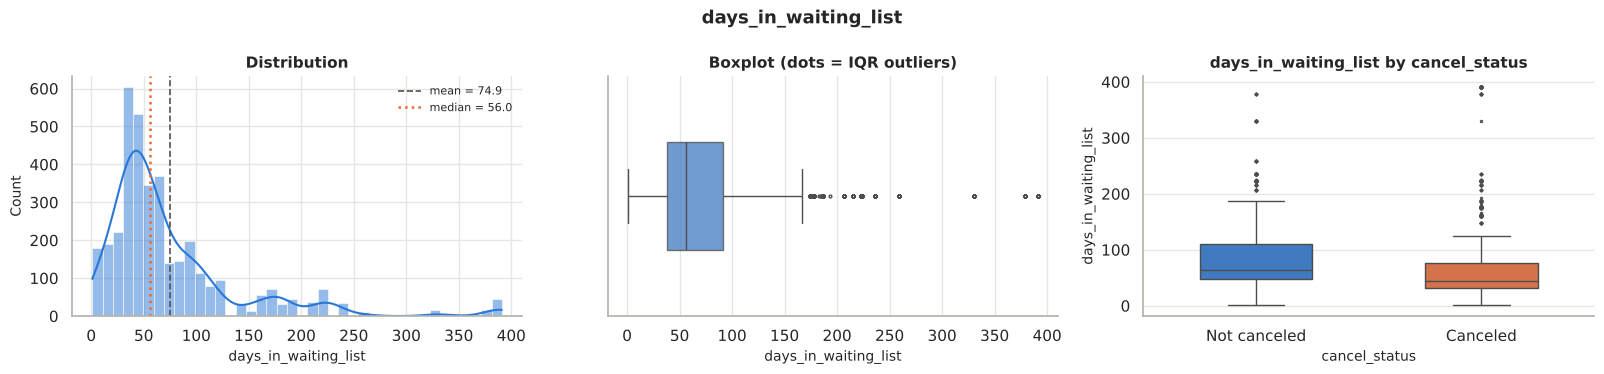

Plots show only non-zero values (≈97% of rows are 0).


In [128]:
profile(hotel, "days_in_waiting_list")
plot_numeric(hotel[hotel["days_in_waiting_list"] > 0], "days_in_waiting_list",
             target="cancel_status", order=["Not canceled", "Canceled"], bins=40)
print("Plots show only non-zero values (≈97% of rows are 0).")

**Observations — `days_in_waiting_list`**
- ≈97% of bookings were confirmed immediately (0 days); the rest waited up to 391 days.
- Bookings that had to wait cancel more often (≈64% vs ≈36%).

**Cleaning:** no missing values; values kept; flag `was_waitlisted` added.

In [129]:
hotel["was_waitlisted"] = (hotel["days_in_waiting_list"] > 0).astype(int)
hotel.groupby("was_waitlisted")["is_canceled"].mean().mul(100).round(1)

was_waitlisted
0   36.20
1   63.90
Name: is_canceled, dtype: float64

### Column 27 — `customer_type`

Column : customer_type
dtype  : str
Missing: 0 (0.00%)
Unique : 4
----------------------------------------
                 count  percent
customer_type                  
Transient        89475    75.06
Transient-Party  25087    21.04
Contract          4071     3.42
Group              574     0.48


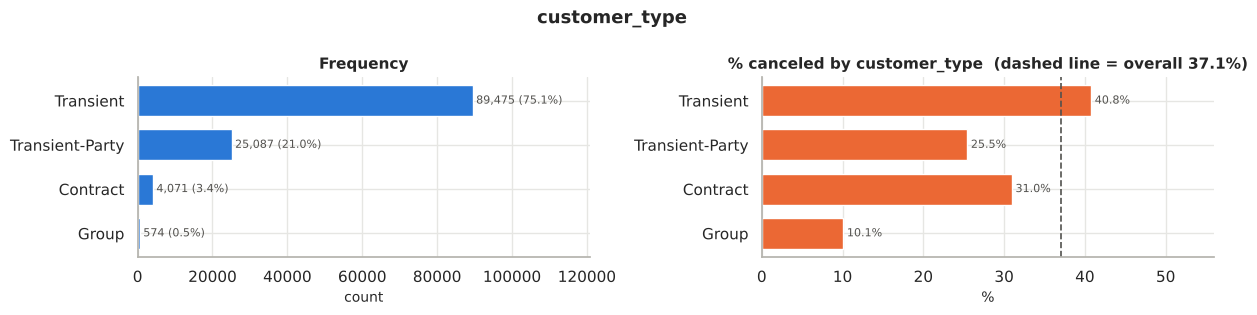

In [130]:
profile(hotel, "customer_type")
plot_categorical(hotel, "customer_type", target="is_canceled", pos=1, label="canceled")

**Observations — `customer_type`**
- `Transient` (individual travellers) ≈ 75% of bookings and the highest cancellation rate (≈41%).
- `Group` bookings (under this label) cancel least (≈10%).

**Cleaning:** none required.

### Column 28 — `adr` (Average Daily Rate, €)

Column : adr
dtype  : float64


Missing: 0 (0.00%)
Unique : 8,865
----------------------------------------
count   119,207.00
mean        101.97
std          50.43
min          -6.38
25%          69.50
50%          94.95
75%         126.00
max       5,400.00
skewness : 10.613
kurtosis : 1022.810
zeros    : 1,810 (1.52%)
IQR fences: [-15.25, 210.75] -> outliers: 3,864 (3.24%)


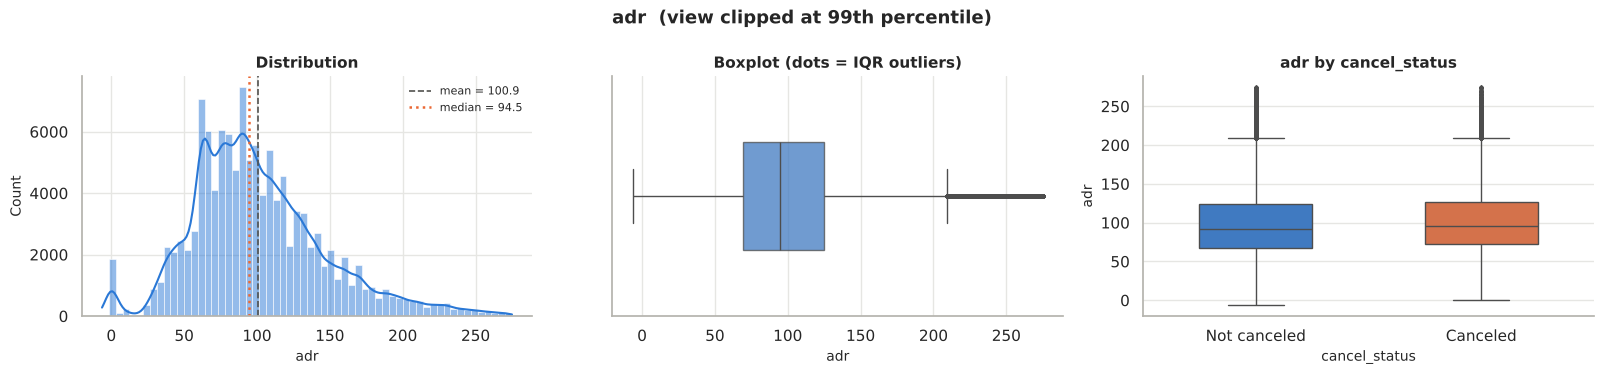

Rows with adr < 0: 1 | adr > 1000: 1 | adr == 0: 1810


In [131]:
profile(hotel, "adr")
plot_numeric(hotel, "adr", target="cancel_status", order=["Not canceled", "Canceled"], bins=60, clip_q=0.995)
print("Rows with adr < 0:", (hotel["adr"] < 0).sum(), "| adr > 1000:", (hotel["adr"] > 1000).sum(),
      "| adr == 0:", (hotel["adr"] == 0).sum())

In [132]:
hotel.loc[(hotel["adr"] < 0) | (hotel["adr"] > 1000),
          ["hotel", "adr", "adults", "total_nights", "market_segment"]]

,hotel,adr,adults,total_nights,market_segment
14969,Resort Hotel,-6.38,2,10,Groups
48515,City Hotel,"5,400.00",2,1,Offline TA/TO


**Observations — `adr`**
- Typical price ≈ €95 per night (median); mean ≈ €102.
- **Two invalid values:** one negative rate (−6.38) and one of **€5,400** (≈10× the next highest value) — clearly entry errors.
- ≈1,800 bookings have a rate of €0 — mostly `Complementary` (free) stays, which are legitimate.
- Canceled bookings have a slightly higher average rate.

**Cleaning:** remove the negative and the €5,400 row. €0 rates are kept.

Rows removed: 2
adr range now: 0.00 - 510.00


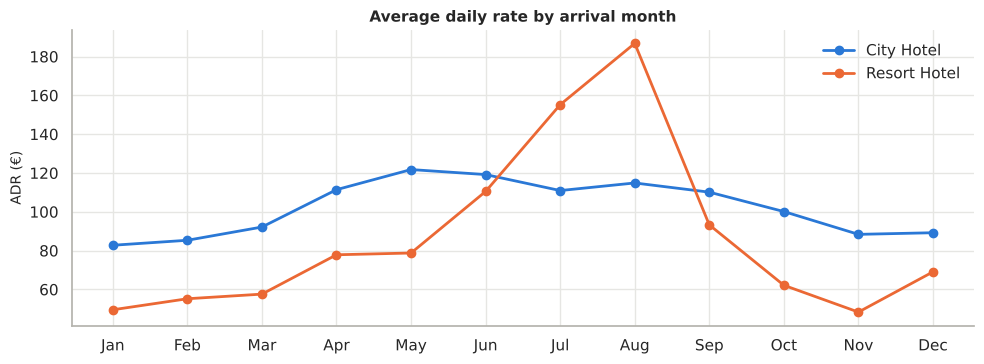

In [133]:
before = len(hotel)
hotel = hotel[(hotel["adr"] >= 0) & (hotel["adr"] < 1000)].copy()
print("Rows removed:", before - len(hotel))
print(f"adr range now: {hotel['adr'].min():.2f} - {hotel['adr'].max():.2f}")

fig, ax = plt.subplots(figsize=(10, 3.8))
m = hotel.groupby(["arrival_month_num", "hotel"])["adr"].mean().unstack()
for h, c in [("City Hotel", BLUE), ("Resort Hotel", ORANGE)]:
    ax.plot([mo[:3] for mo in month_order], m[h].values, color=c, lw=2, marker="o", ms=6, label=h)
ax.set_title("Average daily rate by arrival month")
ax.set_ylabel("ADR (€)")
ax.legend(frameon=False)
plt.tight_layout(); plt.show()

The cleaned ADR shows strong **seasonality**: the Resort Hotel's rate rises from ≈€50 in January to ≈€187 in August, while the City Hotel's price is more stable through the year.

### Column 29 — `required_car_parking_spaces`

Column : required_car_parking_spaces
dtype  : int64
Missing: 0 (0.00%)
Unique : 5
----------------------------------------
count   119,205.00
mean          0.06
std           0.25
min           0.00
25%           0.00
50%           0.00
75%           0.00
max           8.00
skewness : 4.162
kurtosis : 29.995
zeros    : 111,796 (93.78%)
IQR fences: [0.00, 0.00] -> outliers: 7,409 (6.22%)


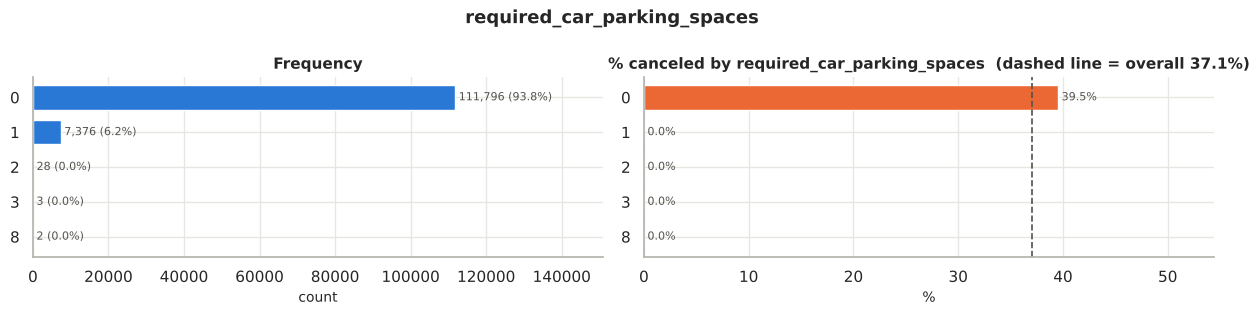

In [134]:
profile(hotel, "required_car_parking_spaces")
plot_categorical(hotel, "required_car_parking_spaces", target="is_canceled", pos=1, label="canceled", sort_index=True)

**Observations — `required_car_parking_spaces`**
- ≈94% of bookings need no parking; a few need 1–3; two rows ask for 8 (possible for a group).
- **No booking that requested parking was ever canceled (0%)** — guests requesting parking are almost certainly arriving (another effect that is recorded close to arrival).

**Cleaning:** no missing values; values kept.

### Column 30 — `total_of_special_requests`

Column : total_of_special_requests
dtype  : int64
Missing: 0 (0.00%)
Unique : 6
----------------------------------------
count   119,205.00
mean          0.57
std           0.79
min           0.00
25%           0.00
50%           0.00
75%           1.00
max           5.00
skewness : 1.349
kurtosis : 1.493
zeros    : 70,198 (58.89%)
IQR fences: [-1.50, 2.50] -> outliers: 2,874 (2.41%)


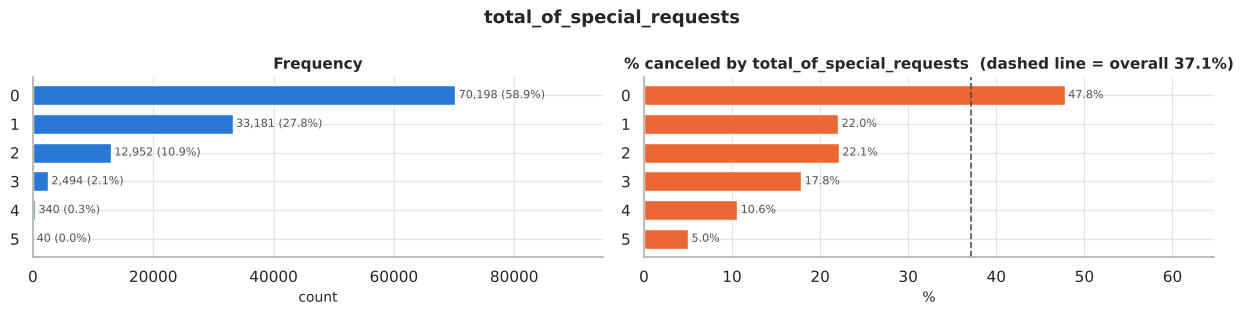

In [135]:
profile(hotel, "total_of_special_requests")
plot_categorical(hotel, "total_of_special_requests", target="is_canceled", pos=1, label="canceled", sort_index=True)

**Observations — `total_of_special_requests`**
- ≈59% of bookings have no special request; up to 5.
- Cancellation falls steadily with more requests: **≈48% with 0 requests → ≈5% with 5** — customers who personalise their stay are committed.

**Cleaning:** none required.

### Column 31 — `reservation_status`

Column : reservation_status
dtype  : str
Missing: 0 (0.00%)
Unique : 3
----------------------------------------
                    count  percent
reservation_status                
Check-Out           75008    62.92
Canceled            42992    36.07
No-Show              1205     1.01


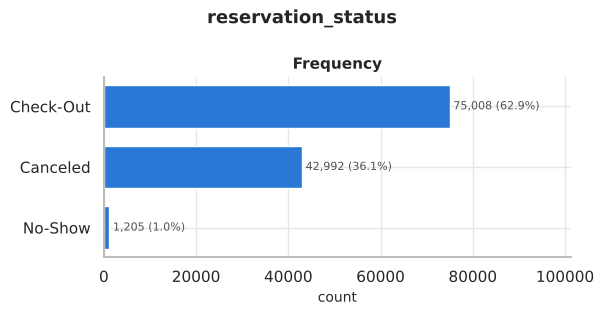

is_canceled,0,1
reservation_status,,
Canceled,0,42992
Check-Out,75008,0
No-Show,0,1205


In [136]:
profile(hotel, "reservation_status")
plot_categorical(hotel, "reservation_status")
pd.crosstab(hotel["reservation_status"], hotel["is_canceled"])

**Observations — `reservation_status`**
- `Check-Out` ≈ 63%, `Canceled` ≈ 36%, `No-Show` ≈ 1%.
- The crosstab shows it is the **target in another form**: Canceled and No-Show are always `is_canceled = 1`, Check-Out is always 0. Fully consistent — no conflicting rows.

**Cleaning:** values are consistent. ⚠️ This column (and `reservation_status_date`) must be **excluded from any prediction model** because it reveals the outcome (*data leakage*).

### Column 32 — `reservation_status_date`

Column : reservation_status_date
dtype  : str
Missing: 0 (0.00%)
Unique : 926
----------------------------------------
                         count  percent
reservation_status_date                
2015-10-21                1460     1.22
2015-07-06                 805     0.68
2016-11-25                 790     0.66
2015-01-01                 763     0.64
2016-01-18                 625     0.52
... 921 more categories
dtype now: datetime64[us]
Range: 2014-10-17 → 2017-09-14


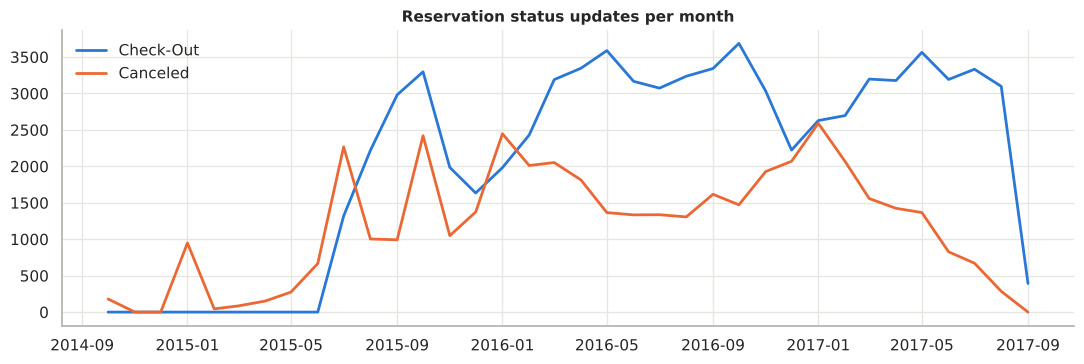

In [137]:
profile(hotel, "reservation_status_date", top=5)
hotel["reservation_status_date"] = pd.to_datetime(hotel["reservation_status_date"])
print("dtype now:", hotel["reservation_status_date"].dtype)
print("Range:", hotel["reservation_status_date"].min().date(), "→", hotel["reservation_status_date"].max().date())

monthly = (hotel.set_index("reservation_status_date")
           .groupby("reservation_status").resample("MS").size().unstack(0).fillna(0))
fig, ax = plt.subplots(figsize=(11, 3.8))
for st, c in [("Check-Out", BLUE), ("Canceled", ORANGE)]:
    ax.plot(monthly.index, monthly[st], color=c, lw=2, label=st)
ax.set_title("Reservation status updates per month")
ax.legend(frameon=False)
plt.tight_layout(); plt.show()

count   42,992.00
mean        88.32
std         90.80
min          0.00
25%         19.00
50%         56.00
75%        130.00
max        526.00
dtype: float64


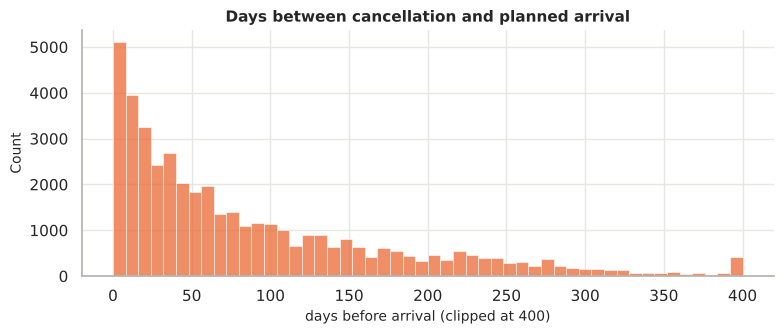

In [138]:
# For canceled bookings: how many days before arrival was the cancellation?
canc = hotel[hotel["reservation_status"] == "Canceled"]
days_before = (canc["arrival_date"] - canc["reservation_status_date"]).dt.days
print(days_before.describe())
plt.figure(figsize=(8, 3.5))
sns.histplot(days_before.clip(upper=400), bins=50, color=ORANGE, edgecolor="white", linewidth=0.4)
plt.title("Days between cancellation and planned arrival")
plt.xlabel("days before arrival (clipped at 400)")
plt.tight_layout(); plt.show()

**Observations — `reservation_status_date`**
- Stored as text → converted to **datetime**.
- Dates range from Oct 2014 to Sep 2017 — earlier than the first arrival because cancellations can happen months before arrival.
- For canceled bookings, the cancellation happens a **median of ≈56 days** before the planned arrival (half of them between ≈19 and ≈130 days), which gives the hotel time to resell rooms.
- Meaning of the date: for `Check-Out` rows it is the check-out date; for `Canceled`/`No-Show` rows it is the date the status was set.

**Cleaning:** type converted to datetime; leakage column (excluded from modelling).

### Columns 33–36 — Personal data: `name`, `email`, `phone-number`, `credit_card`
These columns contain personal identifiers. They are checked for quality, then removed for privacy (they also carry no analytical value).

#### Column 33 — `name`

Column : name
dtype  : str
Missing: 0 (0.00%)
Unique : 81,403
----------------------------------------
                   count  percent
name                             
Michael Johnson       48     0.04
Robert Smith          48     0.04
Michael Smith         47     0.04
John Smith            46     0.04
Christopher Smith     44     0.04
Jennifer Smith        42     0.04
James Smith           39     0.03
David Smith           36     0.03
Michael Williams      35     0.03
Christopher Jones     31     0.03
... 81393 more categories


Words per name: {2: 114574, 3: 4050, 4: 581}


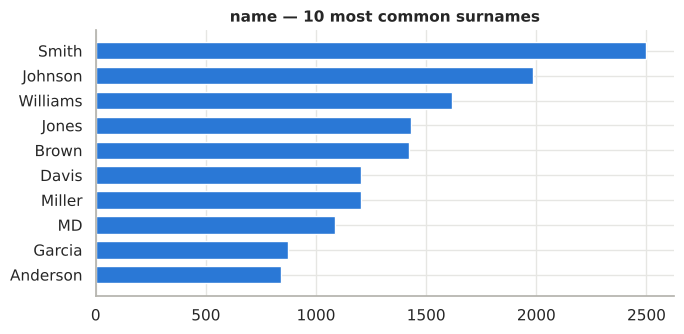

In [139]:
profile(hotel, "name", top=10)
name_len = hotel["name"].str.split().str.len()
print("Words per name:", name_len.value_counts().to_dict())
last = hotel["name"].str.split().str[-1].value_counts().head(10)
fig, ax = plt.subplots(figsize=(7, 3.5))
ax.barh(last.index[::-1], last.values[::-1], color=BLUE, height=0.7)
ax.set_title("name — 10 most common surnames")
plt.tight_layout(); plt.show()

**Observations — `name`:** no missing values; ≈81,500 unique names across ≈119,000 bookings (common names repeat, e.g. "Michael Johnson"). Names look **synthetic** (US-style names for a Portuguese hotel), added to the original dataset.

#### Column 34 — `email`

Column : email
dtype  : str
Missing: 0 (0.00%)
Unique : 115,716
----------------------------------------
                      count  percent
email                               
Michael.C@gmail.com       6     0.01
JSmith@gmail.com          5     0.00
JMiller@gmail.com         5     0.00
James.M@mail.com          5     0.00
Robert.M@outlook.com      5     0.00
... 115711 more categories
Valid email format: 100.00%


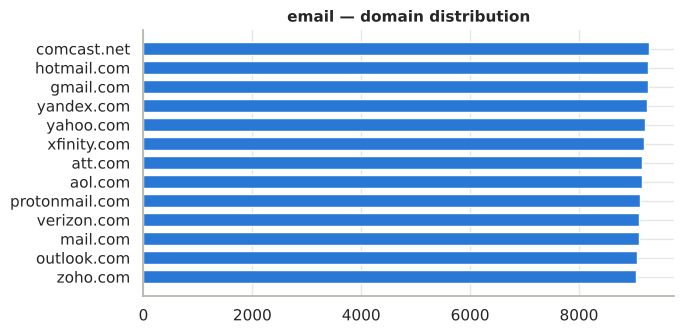

In [140]:
profile(hotel, "email", top=5)
valid = hotel["email"].str.match(r"^[\w.+-]+@[\w-]+\.[\w.]+$")
print(f"Valid email format: {valid.mean()*100:.2f}%")
domains = hotel["email"].str.split("@").str[1].value_counts()
fig, ax = plt.subplots(figsize=(7, 3.5))
ax.barh(domains.index[::-1], domains.values[::-1], color=BLUE, height=0.7)
ax.set_title("email — domain distribution")
plt.tight_layout(); plt.show()

**Observations — `email`:** all values have a valid format; ≈115,900 unique. Domains are split almost **perfectly evenly** (≈9,200 each) — confirms the data is randomly generated.

#### Column 35 — `phone-number`

Column : phone-number
dtype  : str
Missing: 0 (0.00%)
Unique : 119,205
----------------------------------------
              count  percent
phone-number                
669-792-1661      1     0.00
858-637-6955      1     0.00
652-885-2745      1     0.00
... 119202 more categories
Valid ###-###-#### format: 100.00%


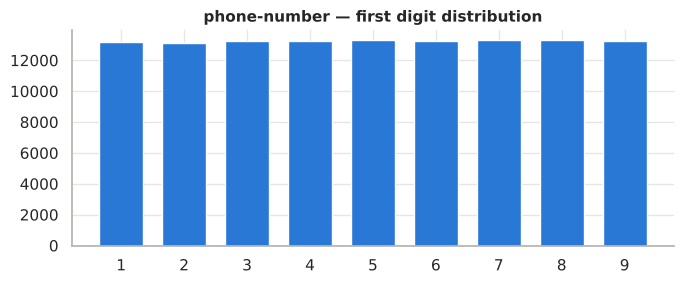

In [141]:
profile(hotel, "phone-number", top=3)
valid = hotel["phone-number"].str.match(r"^\d{3}-\d{3}-\d{4}$")
print(f"Valid ###-###-#### format: {valid.mean()*100:.2f}%")
area = hotel["phone-number"].str[:1].value_counts().sort_index()
fig, ax = plt.subplots(figsize=(7, 3))
ax.bar(area.index, area.values, color=BLUE, width=0.7)
ax.set_title("phone-number — first digit distribution")
plt.tight_layout(); plt.show()

**Observations — `phone-number`:** every number is unique and follows the `###-###-####` format; the first-digit distribution is flat (random data).

#### Column 36 — `credit_card`

Column : credit_card
dtype  : str
Missing: 0 (0.00%)


Unique : 9,000
----------------------------------------
                  count  percent
credit_card                     
************3627     28     0.02
************4923     28     0.02
************3793     27     0.02
... 8997 more categories
Masked format (************1234): 100.00%


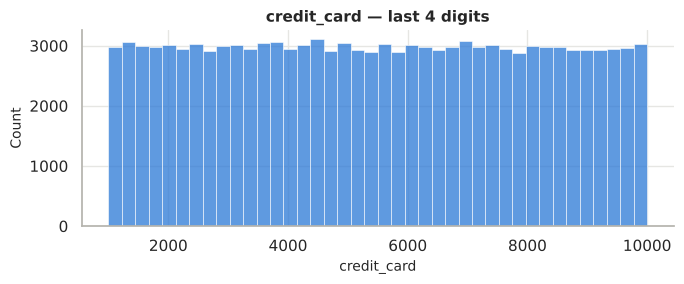

In [142]:
profile(hotel, "credit_card", top=3)
masked = hotel["credit_card"].str.match(r"^\*{12}\d{4}$")
print(f"Masked format (************1234): {masked.mean()*100:.2f}%")
last4 = hotel["credit_card"].str[-4:].astype(int)
plt.figure(figsize=(7, 3))
sns.histplot(last4, bins=40, color=BLUE, edgecolor="white", linewidth=0.4)
plt.title("credit_card — last 4 digits")
plt.tight_layout(); plt.show()

**Observations — `credit_card`:** already **masked** (only the last 4 digits are visible); 9,000 distinct values, uniformly spread.

**Cleaning (columns 33–36):** drop all four personal-data columns — they identify people, are not needed for analysis, and should not be stored in a shared/cleaned file.

In [143]:
hotel = hotel.drop(columns=pii_cols)
print("Personal columns dropped. Shape:", hotel.shape)

Personal columns dropped. Shape: (119205, 46)


## 3.5 Multivariate analysis

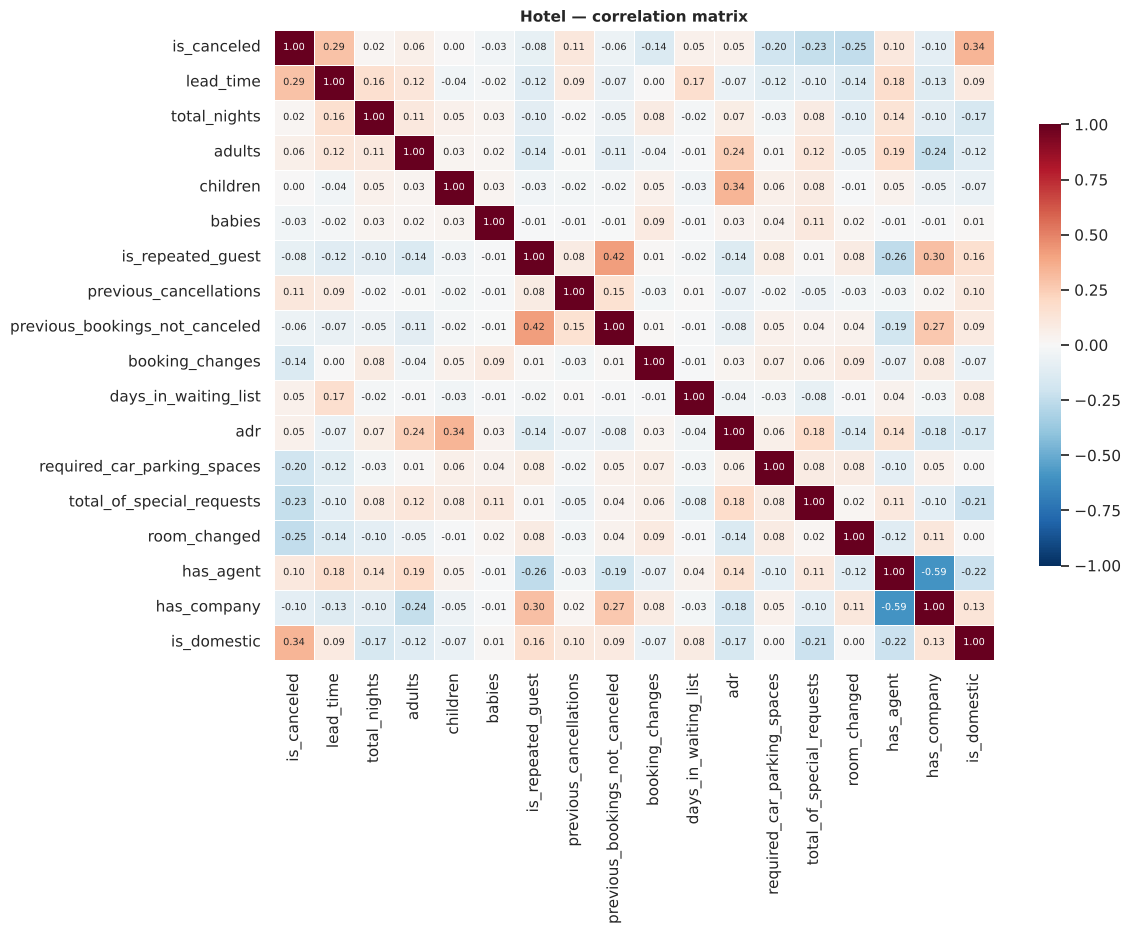

In [144]:
num_cols = ["is_canceled", "lead_time", "total_nights", "adults", "children", "babies",
            "is_repeated_guest", "previous_cancellations", "previous_bookings_not_canceled",
            "booking_changes", "days_in_waiting_list", "adr", "required_car_parking_spaces",
            "total_of_special_requests", "room_changed", "has_agent", "has_company", "is_domestic"]
plt.figure(figsize=(12, 9.5))
sns.heatmap(hotel[num_cols].corr(), annot=True, fmt=".2f", cmap="RdBu_r", center=0,
            vmin=-1, vmax=1, linewidths=0.4, annot_kws={"size": 7}, cbar_kws={"shrink": 0.7})
plt.title("Hotel — correlation matrix")
plt.tight_layout(); plt.show()

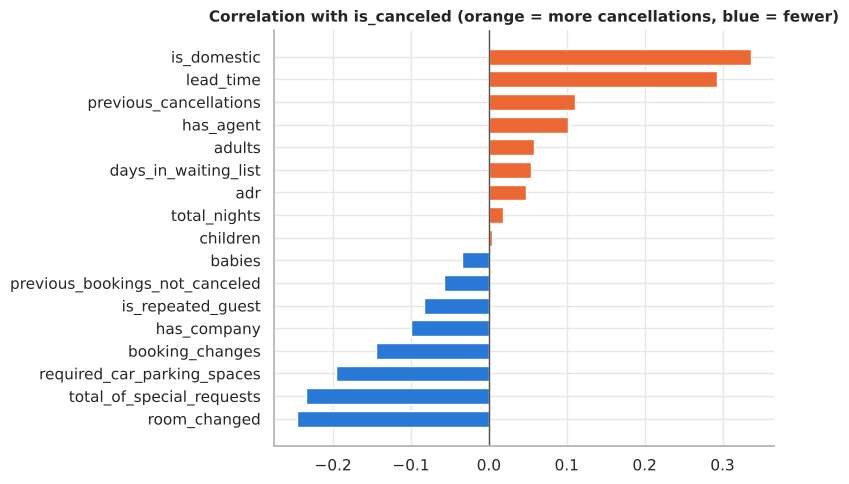

In [145]:
corr_target = hotel[num_cols].corr()["is_canceled"].drop("is_canceled").sort_values()
fig, ax = plt.subplots(figsize=(8, 5))
colors = [ORANGE if v > 0 else BLUE for v in corr_target.values]
ax.barh(corr_target.index, corr_target.values, color=colors, height=0.7)
ax.axvline(0, color=INK, lw=1)
ax.set_title("Correlation with is_canceled (orange = more cancellations, blue = fewer)")
plt.tight_layout(); plt.show()

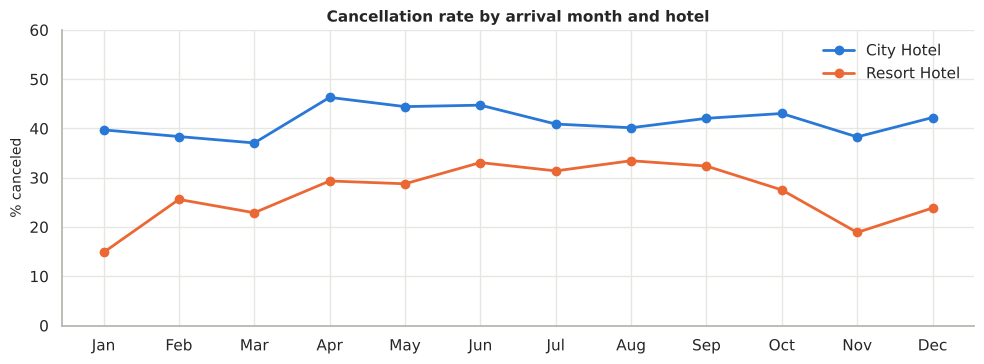

In [146]:
monthly = (hotel.groupby(["arrival_month_num", "hotel"])["is_canceled"].mean().unstack() * 100)
fig, ax = plt.subplots(figsize=(10, 3.8))
for h, c in [("City Hotel", BLUE), ("Resort Hotel", ORANGE)]:
    ax.plot([mo[:3] for mo in month_order], monthly[h].values, color=c, lw=2, marker="o", ms=6, label=h)
ax.set_title("Cancellation rate by arrival month and hotel")
ax.set_ylabel("% canceled"); ax.set_ylim(0, 60)
ax.legend(frameon=False)
plt.tight_layout(); plt.show()

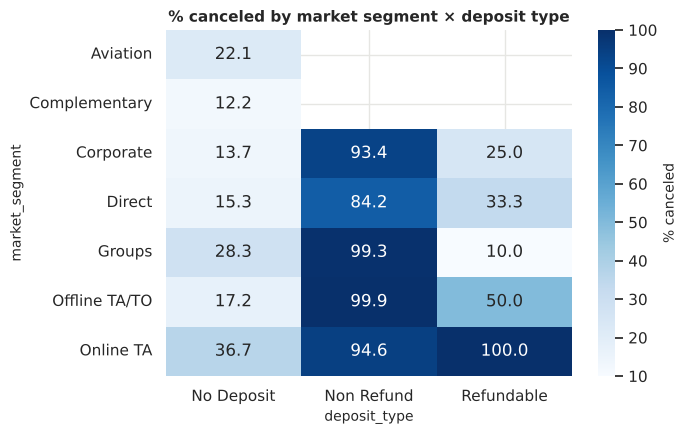

In [147]:
pivot = hotel.pivot_table(index="market_segment", columns="deposit_type",
                          values="is_canceled", aggfunc="mean") * 100
plt.figure(figsize=(7, 4.5))
sns.heatmap(pivot, annot=True, fmt=".1f", cmap="Blues", cbar_kws={"label": "% canceled"})
plt.title("% canceled by market segment × deposit type")
plt.tight_layout(); plt.show()

## 3.6 Final verification & export

In [148]:
print("Original shape:", hotel_raw.shape, "| Cleaned shape:", hotel.shape)
print("Rows removed in total:", len(hotel_raw) - len(hotel))
print("Total missing values remaining:", hotel.isna().sum().sum())
for c in ["meal", "market_segment", "distribution_channel"]:
    print(f"'Undefined' left in {c}:", (hotel[c] == "Undefined").sum())
overview(hotel)

Original shape: (119390, 36) | Cleaned shape: (119205, 46)
Rows removed in total: 185
Total missing values remaining: 0
'Undefined' left in meal: 0
'Undefined' left in market_segment: 0
'Undefined' left in distribution_channel: 0


,dtype,non_null,missing,missing_%,unique,sample_values
hotel,str,119205,0,0.00,2,"[Resort Hotel, City Hotel]"
is_canceled,int64,119205,0,0.00,2,"[0, 1]"
lead_time,int64,119205,0,0.00,479,"[342, 737, 7, 13]"
arrival_date_year,int64,119205,0,0.00,3,"[2015, 2016, 2017]"
arrival_date_month,str,119205,0,0.00,12,"[July, August, September, October]"
arrival_date_week_number,int64,119205,0,0.00,53,"[27, 28, 29, 30]"
arrival_date_day_of_month,int64,119205,0,0.00,31,"[1, 2, 3, 4]"
stays_in_weekend_nights,int64,119205,0,0.00,17,"[0, 1, 2, 4]"
stays_in_week_nights,int64,119205,0,0.00,33,"[0, 1, 2, 3]"
adults,int64,119205,0,0.00,14,"[2, 1, 3, 4]"


In [149]:
hotel = hotel.reset_index(drop=True)
hotel.to_csv("hotel_booking_cleaned.csv", index=False)
print("Saved -> hotel_booking_cleaned.csv")

Saved -> hotel_booking_cleaned.csv


## 3.7 Key insights — Hotel Booking dataset
1. **37% of bookings are canceled** — City Hotel (≈42%) much more than Resort Hotel (≈28%).
2. **Lead time** is the strongest numeric driver: canceled bookings were made ≈113 days ahead (median) vs ≈45 for kept ones.
3. **Customer commitment signals** reduce cancellations: special requests, parking requests, booking changes, being a repeat guest, or having stayed before.
4. **Previous cancellations** predict future ones (≈92% cancel again).
5. **Groups** and **Online/Offline travel agents** cancel most; Direct and Corporate bookings are the most reliable. Domestic (Portuguese) guests cancel far more than foreign guests.
6. `Non Refund` deposits show ≈99% cancellations — a data quirk worth investigating rather than a real customer behaviour.
7. **Seasonality**: demand and prices peak in July–August (Resort ADR more than doubles).
8. Data quality: 5 invalid rows removed (impossible children/babies, negative and €5,400 ADR) plus 180 zero-guest bookings; `children`/`country`/`agent` imputed; `company` (94% missing) replaced by a flag; `Undefined` markers fixed; `CN` → `CHN`; dates converted to datetime; personal data removed; leakage columns identified.

---
# Final Summary

| | Loan | Adult | Hotel Booking |
|---|---|---|---|
| Raw shape | 1,614 × 13 | 48,842 × 15 | 119,390 × 36 |
| Missing / hidden-missing handled | 149 cells in 7 columns (mode / median) | `?` in 3 columns → `Unknown` / mode | `children`, `country`, `agent`, `company`, `Undefined` markers |
| Duplicates | none (ID collisions found, `Loan_ID` dropped) | 52 rows removed | none exact; group-booking repeats kept |
| Invalid values / outliers | income outliers capped | top-codes noted, valid outliers kept | impossible children/babies, negative & €5,400 ADR, 0-guest rows removed |
| Type fixes | `Dependents` text → int | `?` → NaN | dates → datetime, `agent`/`children` → int |
| Removed columns | `Loan_ID` | — | `company` (94% missing), 4 personal-data columns |
| Strongest drivers of target | credit history, loan amount, property area | education, marital status, age, capital gains | lead time, deposit type, special requests, previous cancellations, segment |
| Output file | `loan_cleaned.csv` | `adult_cleaned.csv` | `hotel_booking_cleaned.csv` |

**Lessons learned**
- `info()` alone is not enough — missing values can hide as `?`, `Undefined` or impossible values (0 guests, negative prices).
- Not every outlier is an error: old ages, long lead times and large groups are real; only clearly impossible values were removed.
- Duplicate checks need judgement: repeated IDs (Loan) and identical group bookings (Hotel) are not true duplicates.
- Some columns describe the outcome itself (`reservation_status`) and must be excluded from prediction models to avoid data leakage.